### 1. Import the libraries

Pandas handles tables, NumPy handles numerical operations, and seaborn/matplotlib draw graphs. `Path` handles file locations. A dictionary called `raw` will store the original tables.

In [175]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 30)

DATA_DIR = Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")
table_names = ["circuits", "constructors", "constructor_results", "constructor_standings",
               "drivers", "driver_standings", "races", "results", "qualifying",
               "lap_times", "pit_stops", "sprint_results", "seasons", "status"]

### 2. Load the CSV files

Each table is stored under its name: for example, `raw["drivers"]`. `keep_default_na=False` lets us see the original missing-value markers before cleaning.

In [176]:
raw = {}

if not DATA_DIR.exists() and Path('/kaggle/input').exists():
    folders = []
    for file in Path('/kaggle/input').rglob('results.csv'):
        if all((file.parent / (name + '.csv')).exists() for name in table_names):
            folders.append(file.parent)
    if len(folders) == 1:
        DATA_DIR = folders[0]

if DATA_DIR.exists():
    for name in table_names:
        raw[name] = pd.read_csv(DATA_DIR / (name + '.csv'), keep_default_na=False)

print('Tables loaded:', len(raw))
display(raw['results'].head())

Tables loaded: 14


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


## Initial EDA
EDA means exploring what the data looks like before deciding how to clean or analyze it.

### 3. Count rows, missing values and duplicates

`shape` gives the table size. `isna()` finds real missing cells; `\N` and blank strings must be counted separately. `duplicated()` checks repeated whole rows. Later we also check repeated driver–race pairs, which are a different problem.

In [177]:
def missing_mask(df):
    return df.isna() | df.eq(r'\N') | df.eq('')

summary_rows = []
column_rows = []
for name, df in raw.items():
    missing = missing_mask(df)
    summary_rows.append({
        'table': name, 'rows': len(df), 'columns': len(df.columns),
        'sentinels': int(df.eq(r'\N').sum().sum()),
        'missing_cells': int(missing.sum().sum()),
        'exact_duplicates': int(df.duplicated().sum())
    })
    for column in df.columns:
        column_rows.append({
            'table': name, 'column': column,
            'dtype_before': str(df[column].dtype),
            'missing_pct': 100 * missing[column].mean()
        })

inventory = pd.DataFrame(summary_rows)
schema_before = pd.DataFrame(column_rows)
display(inventory)
display(schema_before)

,table,rows,columns,sentinels,missing_cells,exact_duplicates
0,circuits,77,9,0,0,0
1,constructors,212,5,0,0,0
2,constructor_results,12625,5,12608,12608,0
3,constructor_standings,13391,7,0,0,0
4,drivers,861,9,1559,1559,0
5,driver_standings,34863,7,0,0,0
6,races,1125,18,11349,11349,0
7,results,26759,18,122887,122887,0
8,qualifying,10494,9,11600,11668,0
9,lap_times,589081,6,0,0,0


,table,column,dtype_before,missing_pct
0,circuits,circuitId,int64,0.0
1,circuits,circuitRef,object,0.0
2,circuits,name,object,0.0
3,circuits,location,object,0.0
4,circuits,country,object,0.0
...,...,...,...,...
115,sprint_results,statusId,int64,0.0
116,seasons,year,int64,0.0
117,seasons,url,object,0.0
118,status,statusId,int64,0.0


### 4. Plot missing values

We plot the 20 fields with the most missing values. For example, missing qualifying times should not become zero seconds: that would look like an impossibly fast lap.

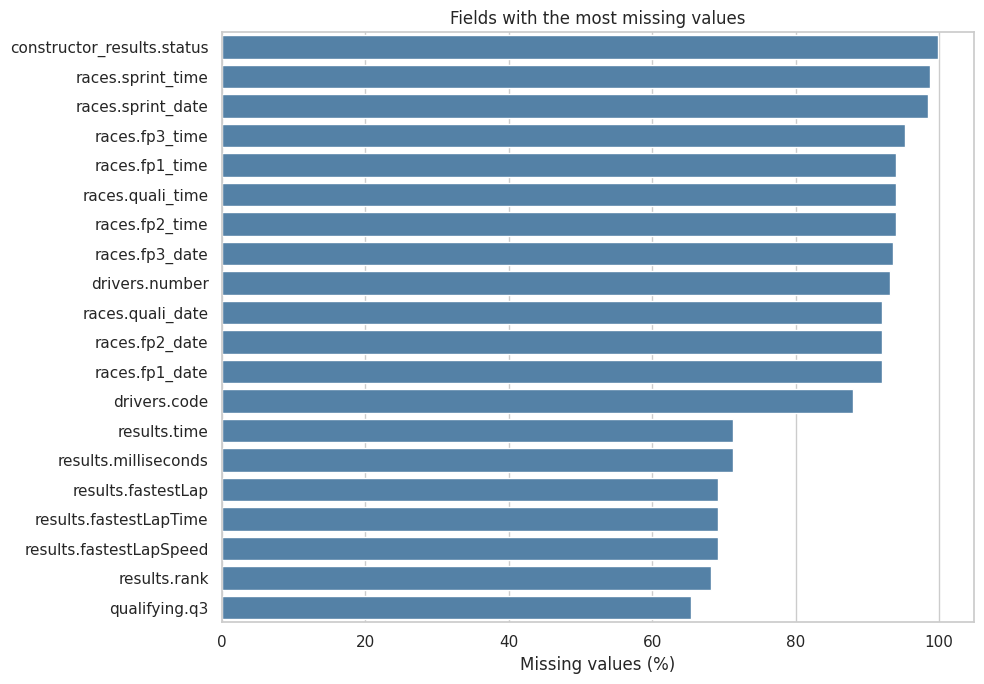

In [178]:
missing_top = schema_before.sort_values('missing_pct', ascending=False).head(20).copy()
missing_top['field'] = missing_top['table'] + '.' + missing_top['column']

plt.figure(figsize=(10, 7))
sns.barplot(data=missing_top, x='missing_pct', y='field', color='steelblue')
plt.xlabel('Missing values (%)')
plt.ylabel('')
plt.title('Fields with the most missing values')
plt.tight_layout()
plt.show()
plt.close()

### 5. Check which years have race results

The race calendar can contain races without results. We compare scheduled races with races actually represented in `results`. A many-to-one merge means many result rows can refer to one race, but the race table must not repeat its key.

,scheduled_races,races_with_results
year,,
2013,19,19
2014,19,19
2015,19,19
2016,21,21
2017,20,20
2018,21,21
2019,21,21
2020,17,17
2021,22,22


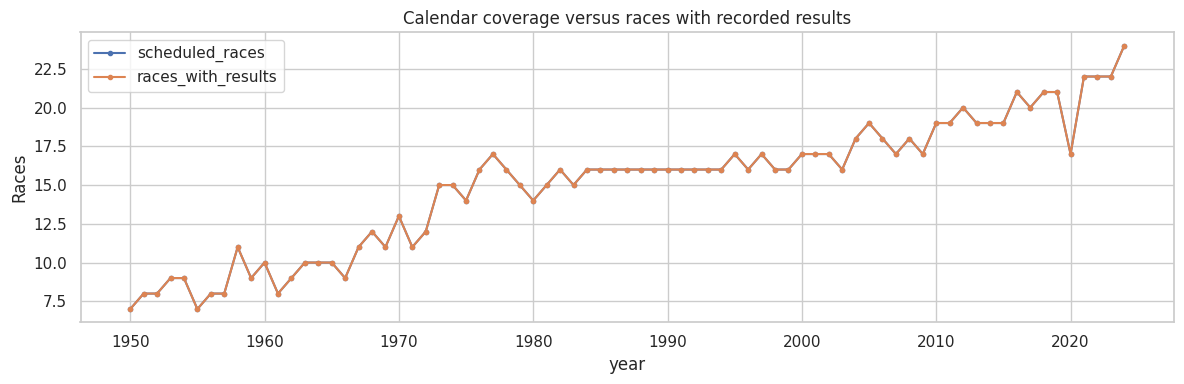

In [179]:
raw_race_results = raw['results'].merge(raw['races'][['raceId','year']], on='raceId', validate='many_to_one')
calendar_coverage = raw['races'].groupby('year').agg(scheduled_races=('raceId','nunique'))
calendar_coverage['races_with_results'] = raw_race_results.groupby('year')['raceId'].nunique()
calendar_coverage = calendar_coverage.fillna(0).astype(int)
display(calendar_coverage.tail(12))
calendar_coverage.plot(figsize=(12,4), marker='.')
plt.ylabel('Races'); plt.title('Calendar coverage versus races with recorded results')
plt.tight_layout()
plt.show()
plt.close()

### 6. Check qualifying coverage

We match each unique driver–race pair with qualifying. The fraction matched is more useful than a raw count because seasons have different numbers of races and entrants. Low coverage means missing history, not poor qualifying performance.

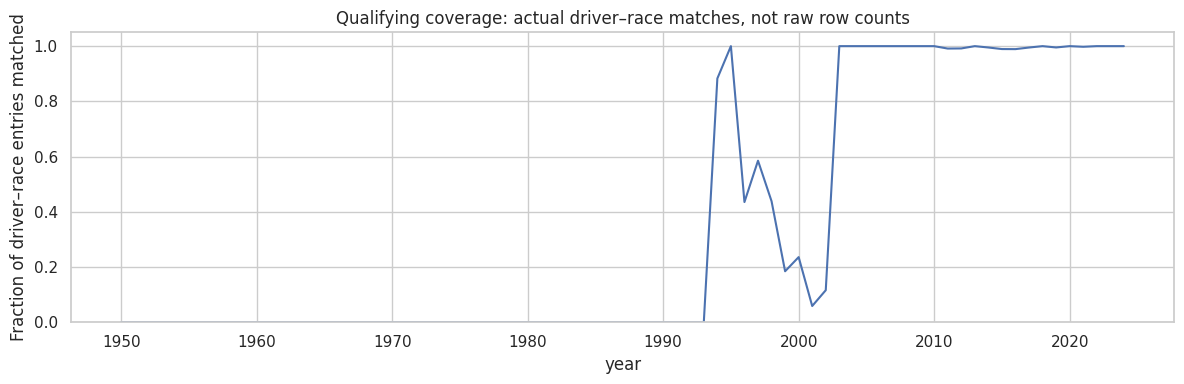

In [180]:
raw_pairs = raw['results'][['raceId','driverId']].drop_duplicates()
qual_pairs = raw['qualifying'][['raceId','driverId']].drop_duplicates().assign(has_qualifying=1)
raw_coverage = (raw_pairs.merge(qual_pairs, on=['raceId','driverId'], how='left', validate='one_to_one')
               .merge(raw['races'][['raceId','year']], on='raceId', validate='many_to_one'))
raw_coverage['has_qualifying'] = raw_coverage['has_qualifying'].fillna(0)
coverage_year = raw_coverage.groupby('year').agg(entries=('driverId','size'), qualifying_coverage=('has_qualifying','mean'))
plt.figure(figsize=(12,4))
sns.lineplot(data=coverage_year.reset_index(), x='year', y='qualifying_coverage')
plt.ylim(0,1.05); plt.ylabel('Fraction of driver–race entries matched')
plt.title('Qualifying coverage: actual driver–race matches, not raw row counts')
plt.tight_layout()
plt.show()
plt.close()

### 7. Look at grids and podium frequency

These are the raw distributions before duplicate handling. Grid 0 is not pole position. The podium plot also shows that the two target classes are not equally common.

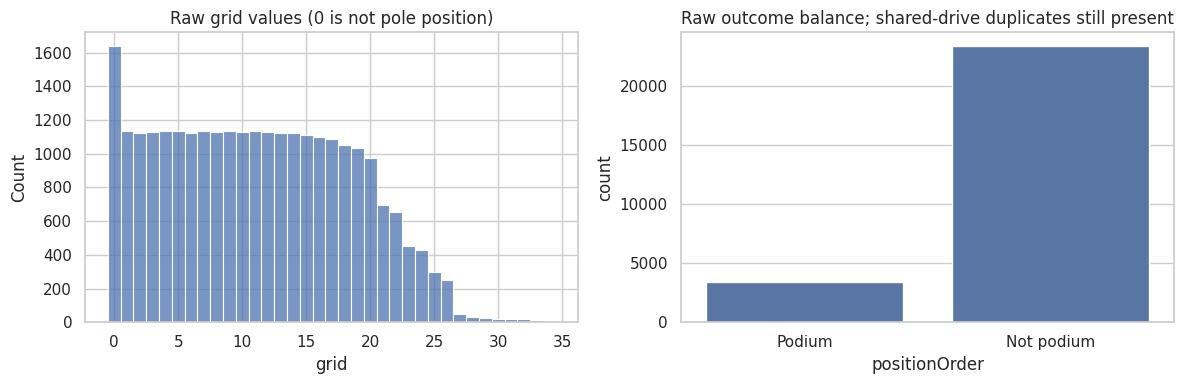

In [181]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=raw['results'], x='grid', discrete=True, ax=axes[0])
axes[0].set_title('Raw grid values (0 is not pole position)')
raw_podium = pd.to_numeric(raw['results']['positionOrder'], errors='coerce').le(3)
sns.countplot(x=raw_podium.map({False:'Not podium',True:'Podium'}), ax=axes[1])
axes[1].set_title('Raw outcome balance; shared-drive duplicates still present')
plt.tight_layout()
plt.show()
plt.close()

## Data cleaning
We clean copies. Missing information stays missing unless there is a justified way to recover it.

### 8. Copy the tables and replace missing markers

`.copy()` protects the raw tables. `.str.strip()` removes surrounding spaces, including the trailing space in one nationality label. We replace `\N` and empty strings with missing values.

In [182]:
clean = {t: d.copy(deep=True) for t,d in raw.items()}
for t,d in clean.items():
    for c in d.select_dtypes(include=['object','string']).columns:
        s = d[c].astype('string').str.strip()
        d[c] = s.mask(s.isin([r'\N','']))

### 9. List the columns that should be numeric

Some columns are read as text because they contain missing markers. We list them explicitly. Counts and IDs use `Int64`, which allows missing integers. Measurements such as points and speed use `Float64`. The small audit function records non-missing values that fail conversion.

In [183]:
numeric_columns = {
 'circuits':['circuitId','lat','lng','alt'],
 'constructors':['constructorId'],
 'constructor_results':['constructorResultsId','raceId','constructorId','points'],
 'constructor_standings':['constructorStandingsId','raceId','constructorId','points','position','wins'],
 'drivers':['driverId','number'],
 'driver_standings':['driverStandingsId','raceId','driverId','points','position','wins'],
 'races':['raceId','year','round','circuitId'],
 'results':['resultId','raceId','driverId','constructorId','number','grid','position','positionOrder','points','laps','milliseconds','fastestLap','rank','fastestLapSpeed','statusId'],
 'qualifying':['qualifyId','raceId','driverId','constructorId','number','position'],
 'lap_times':['raceId','driverId','lap','position','milliseconds'],
 'pit_stops':['raceId','driverId','stop','lap','milliseconds'],
 'sprint_results':['resultId','raceId','driverId','constructorId','number','grid','position','positionOrder','points','laps','milliseconds','fastestLap','statusId'],
 'seasons':['year'], 'status':['statusId']
}
float_fields = {'lat','lng','alt','points','fastestLapSpeed'}
conversion_audit = []
def record_conversion(table, column, before, after):
    bad = before.notna() & after.isna()
    conversion_audit.append({'table':table,'column':column,'invalid_nonmissing':int(bad.sum()),
                             'examples':str(before[bad].head(3).tolist())})

### 10. Convert numeric columns

`pd.to_numeric()` changes numeric text into numbers. `errors="coerce"` marks invalid text as missing, but the audit makes sure we do not silently lose values. The integer check prevents rounding a non-integer by accident.

In [184]:
for t, cols in numeric_columns.items():
    for c in cols:
        before = clean[t][c]
        converted = pd.to_numeric(before, errors='coerce')
        record_conversion(t,c,before,converted)
        if c not in float_fields:
            assert converted.dropna().mod(1).eq(0).all(), (t,c,'non-integer')
        clean[t][c] = converted.astype('Float64' if c in float_fields else 'Int64')

### 11. Convert dates

Dates become datetime values so we can compare them and calculate age. The format is year-month-day. Missing session dates remain missing.

In [185]:
for t, cols in {'drivers':['dob'], 'races':['date','fp1_date','fp2_date','fp3_date','quali_date','sprint_date']}.items():
    for c in cols:
        before = clean[t][c]
        converted = pd.to_datetime(before, format='%Y-%m-%d', errors='coerce')
        record_conversion(t,c,before,converted)
        clean[t][c] = converted

### 12. Convert clock times

A clock time such as 14:00:00 is not a lap duration. Here it becomes time since midnight. We check that it lies within one day.


In [186]:
for t, cols in {'races':['time','fp1_time','fp2_time','fp3_time','quali_time','sprint_time'], 'pit_stops':['time']}.items():
    for c in cols:
        before = clean[t][c]
        converted = pd.to_timedelta(before.astype(object).where(before.notna(), None), errors='coerce')
        record_conversion(t,c,before,converted)
        assert converted.dropna().between(pd.Timedelta(0),pd.Timedelta(days=1),inclusive='left').all()
        clean[t][c] = converted

### 13. Write a small duration converter

A lap time such as `1:23.456` means 60 + 23.456 = 83.456 seconds. The function also handles hours and plain seconds. It returns a missing value when the original is missing or invalid.


In [187]:
def duration_seconds(series):
    # Valid formats: SS.sss, M:SS.sss, H:MM:SS.sss; no race gaps here.
    def parse(value):
        if pd.isna(value): return np.nan
        parts = str(value).split(':')
        try:
            values = [float(v) for v in parts]
            if len(values) not in (1,2,3) or any(v < 0 for v in values): return np.nan
            if len(values)>1 and any(v>=60 for v in values[1:]): return np.nan
            return sum(v * 60**i for i,v in enumerate(reversed(values)))
        except ValueError:
            return np.nan
    return series.map(parse).astype(float)

### 14. Convert qualifying, lap and pit-stop durations

We add columns ending in `_seconds` rather than deleting the original text. Missing Q2/Q3 can mean elimination, no timed lap, or unavailable data; we do not invent a time.


In [188]:
for t, cols in {'qualifying':['q1','q2','q3'], 'lap_times':['time'],
                'pit_stops':['duration'], 'results':['fastestLapTime'],
                'sprint_results':['fastestLapTime']}.items():
    for c in cols:
        converted = duration_seconds(clean[t][c])
        record_conversion(t,c,clean[t][c],converted)
        clean[t][c+'_seconds'] = converted

### 15. Separate race durations from gaps

Race `time` mixes winning durations and gaps such as `+5.478`. We separate those meanings. The milliseconds field becomes elapsed seconds where available. None of these current-race outcomes should be used to predict the same race.


In [189]:
for t in ['results','sprint_results']:
    s = clean[t]['time'].astype('string')
    is_gap = s.str.startswith('+',na=False)
    clean[t]['winner_duration_seconds'] = duration_seconds(s.mask(is_gap))
    clean[t]['gap_to_winner_seconds'] = duration_seconds(s.where(is_gap).str.lstrip('+'))
    parsed = clean[t]['winner_duration_seconds'].combine_first(clean[t]['gap_to_winner_seconds'])
    record_conversion(t,'time',s,parsed)
    clean[t]['elapsed_seconds'] = clean[t]['milliseconds'].astype(float)/1000

### 16. Check that the conversions worked

For lap times and pit stops we compare our parsed seconds with milliseconds divided by 1,000. The two should agree. `assert` stops execution when a condition is false, rather than allowing a hidden error to continue.


In [190]:
for t in ['lap_times','pit_stops']:
    clean[t]['elapsed_seconds'] = clean[t]['milliseconds'].astype(float)/1000
    col = 'time_seconds' if t=='lap_times' else 'duration_seconds'
    difference = (clean[t][col] - clean[t]['elapsed_seconds']).abs()
    assert difference.dropna().le(0.002).all(), f'{t}: seconds disagree with milliseconds'

conversion_audit = pd.DataFrame(conversion_audit)
display(conversion_audit.query('invalid_nonmissing > 0'))
assert conversion_audit['invalid_nonmissing'].sum()==0, 'Inspect conversion failures before continuing.'
assert all(not d.astype('string').eq(r'\N').any().any() for d in clean.values())
print('All observed non-missing numeric/date/time values parsed successfully.')

,table,column,invalid_nonmissing,examples


All observed non-missing numeric/date/time values parsed successfully.


### 17. Check primary keys

A primary key identifies one row in its source table. It must be unique and not missing. Some tables need a combination of columns, such as race + driver + lap for lap times. A unique result ID does not guarantee a unique driver–race pair.


In [191]:
primary_keys = {
 'circuits':['circuitId'], 'constructors':['constructorId'],
 'constructor_results':['constructorResultsId'], 'constructor_standings':['constructorStandingsId'],
 'drivers':['driverId'], 'driver_standings':['driverStandingsId'], 'races':['raceId'],
 'results':['resultId'], 'qualifying':['qualifyId'], 'lap_times':['raceId','driverId','lap'],
 'pit_stops':['raceId','driverId','stop'], 'sprint_results':['resultId'], 'seasons':['year'], 'status':['statusId']
}
key_audit = pd.DataFrame([
 {'table':t,'primary_key':','.join(keys),'null_key_rows':int(clean[t][keys].isna().any(axis=1).sum()),
  'duplicate_key_rows':int(clean[t].duplicated(keys).sum())}
 for t,keys in primary_keys.items()
])

### 18. Check foreign keys

A foreign key points to another table: every `driverId` in results should exist in drivers. We check missing references and references with no matching parent. We also check the combinations used by later joins.


In [192]:
parents = {'raceId':('races','raceId'), 'driverId':('drivers','driverId'),
           'constructorId':('constructors','constructorId'), 'circuitId':('circuits','circuitId'),
           'statusId':('status','statusId'), 'year':('seasons','year')}
foreign_key_rows = []
for t,d in clean.items():
    for c,(parent,key) in parents.items():
        if c in d.columns and t!=parent:
            foreign_key_rows.append({'table':t,'column':c,'parent':parent,
                'null_keys':int(d[c].isna().sum()),
                'orphan_keys':int((d[c].notna() & ~d[c].isin(clean[parent][key])).sum())})
foreign_key_audit = pd.DataFrame(foreign_key_rows)
display(key_audit); display(foreign_key_audit)
assert key_audit[['null_key_rows','duplicate_key_rows']].to_numpy().sum()==0
assert foreign_key_audit[['null_keys','orphan_keys']].to_numpy().sum()==0
for t,keys in {'qualifying':['raceId','driverId'], 'driver_standings':['raceId','driverId'],
               'constructor_standings':['raceId','constructorId']}.items():
    assert not clean[t].duplicated(keys).any(), (t,'join grain is not unique')

,table,primary_key,null_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId,driverId,lap",0,0


,table,column,parent,null_keys,orphan_keys
0,constructor_results,raceId,races,0,0
1,constructor_results,constructorId,constructors,0,0
2,constructor_standings,raceId,races,0,0
3,constructor_standings,constructorId,constructors,0,0
4,driver_standings,raceId,races,0,0
5,driver_standings,driverId,drivers,0,0
6,races,circuitId,circuits,0,0
7,races,year,seasons,0,0
8,results,raceId,races,0,0
9,results,driverId,drivers,0,0


### 19. Find repeated driver–race pairs

Some historical drivers have multiple result rows for one race, often because of shared drives. Counting all of them would give one driver multiple observations in the same race. We count the rows belonging to each pair.


In [193]:
results_all = clean['results'].copy()
pair_keys = ['raceId','driverId']
pair_counts = results_all.groupby(pair_keys).size().rename('source_result_rows').reset_index()
duplicate_detail = (results_all.merge(pair_counts.query('source_result_rows>1'), on=pair_keys, validate='many_to_one')
                    .merge(clean['races'][['raceId','year']], on='raceId', validate='many_to_one'))

### 20. Keep one result for each driver in a race

Keep the row with most laps; if tied, keep the better finishing position, then the smaller result ID. This represents the main recorded participation. The choice uses race outcomes, so it is historical cleanup, not a pre-race selection rule. We flag affected pairs for the modeling teammate and keep discarded rows separately.


In [194]:
results_unique = (results_all.sort_values(['raceId','driverId','laps','positionOrder','resultId'],
                                         ascending=[True,True,False,True,True], kind='stable')
                  .drop_duplicates(pair_keys,keep='first').copy())
results_unique = results_unique.merge(pair_counts,on=pair_keys,validate='one_to_one')
results_unique['had_multiple_results'] = results_unique['source_result_rows'].gt(1)
discarded_results = results_all.loc[~results_all['resultId'].isin(results_unique['resultId'])].copy()

### 21. Check what duplicate handling changed

We compare the retained label with whether any of the original rows was a podium. This checks whether the rule changes the driver’s podium label. The cleaned results replace only our working copy, not the CSV file.


In [195]:
any_podium = results_all.assign(any_podium=results_all['positionOrder'].le(3)).groupby(pair_keys)['any_podium'].max()
sensitivity_duplicates = results_unique.set_index(pair_keys)[['positionOrder']].join(any_podium)
sensitivity_duplicates['retained_podium'] = sensitivity_duplicates['positionOrder'].le(3)
duplicate_target_changes = int(sensitivity_duplicates['retained_podium'].ne(sensitivity_duplicates['any_podium']).sum())
assert not results_unique.duplicated(pair_keys).any()
assert len(results_unique) == len(results_all[pair_keys].drop_duplicates()), 'Duplicate handling must preserve every driver–race pair in the retained period.'
clean['results'] = results_unique.copy()
display(duplicate_detail.groupby('year').agg(affected_rows=('resultId','size'), affected_races=('raceId','nunique')))
display(duplicate_detail[['resultId','raceId','year','driverId','constructorId','grid','laps','positionOrder']].head(20))
print(f'Removed {len(discarded_results)} extra rows from {results_unique.had_multiple_results.sum()} driver–race pairs.')
print(f'Labels differing from the any-podium alternative: {duplicate_target_changes}.')

,affected_rows,affected_races
year,,
1950,8,3
1951,8,2
1952,6,3
1953,30,5
1954,33,5
1955,33,4
1956,24,6
1957,16,5
1958,6,3


,resultId,raceId,year,driverId,constructorId,grid,laps,positionOrder
0,13189,540,1978,229,54,0,0,26
1,13192,540,1978,229,57,0,0,29
2,17363,717,1964,373,172,1,102,7
3,17741,733,1962,465,172,0,0,22
4,17744,733,1962,465,97,0,0,25
5,17962,742,1961,475,102,20,56,19
6,17964,742,1961,475,172,5,44,21
7,18063,745,1961,418,172,11,23,17
8,18083,746,1960,475,170,1,40,17
9,18510,766,1958,541,87,0,0,17


Removed 91 extra rows from 85 driver–race pairs.
Labels differing from the any-podium alternative: 0.


### 22. Check for impossible values

We reject negative laps or grid values, impossible latitude/longitude, and non-positive finishing positions. We do not remove unusual values just because they are far from the average.


In [196]:
assert clean['races']['date'].notna().all()
assert clean['races']['round'].gt(0).all()
assert clean['results']['positionOrder'].notna().all()
assert clean['results']['positionOrder'].gt(0).all()
assert clean['results']['grid'].ge(0).all()
assert clean['results']['laps'].ge(0).all()
assert clean['qualifying']['position'].dropna().gt(0).all()
assert clean['circuits']['lat'].between(-90,90).all()
assert clean['circuits']['lng'].between(-180,180).all()
for t,d in clean.items():
    for c in [c for c in d.columns if c.endswith('_seconds')]:
        assert d[c].dropna().ge(0).all(), (t,c,'negative duration')
print('Domain checks passed. No blanket outlier deletion or imputation applied.')

Domain checks passed. No blanket outlier deletion or imputation applied.


## Join the tables and repeat EDA

### 23. Prepare the columns for joining

We choose the needed columns and rename names/positions before merging. For example, `qualifying_position` is different from finishing position. This avoids confusing suffixes like `position_x` and `position_y`.


In [197]:
race_columns = ['raceId','year','round','circuitId','date','sprint_date']
circuit_info = clean['circuits'][['circuitId','name','country']].rename(columns={'name':'circuit_name','country':'circuit_country'})
driver_info = clean['drivers'][['driverId','forename','surname','nationality','dob']].copy()
driver_info['driver_name'] = driver_info['forename']+' '+driver_info['surname']
driver_info = driver_info.drop(columns=['forename','surname']).rename(columns={'nationality':'driver_nationality'})
constructor_info = clean['constructors'][['constructorId','name']].rename(columns={'name':'constructor_name'})
qual_info = clean['qualifying'][['raceId','driverId','constructorId','position','q1_seconds','q2_seconds','q3_seconds']].rename(
    columns={'constructorId':'qualifying_constructorId','position':'qualifying_position'})

### 24. Combine the tables

Start from unique driver–race results. Add race information, then circuit, driver, constructor, status and qualifying information. `how="left"` keeps entries even when qualifying is missing. `validate` checks the relationship and prevents accidental row multiplication.


In [198]:
analysis = (results_unique
    .merge(clean['races'][race_columns],on='raceId',how='left',validate='many_to_one')
    .merge(circuit_info,on='circuitId',how='left',validate='many_to_one')
    .merge(driver_info,on='driverId',how='left',validate='many_to_one')
    .merge(constructor_info,on='constructorId',how='left',validate='many_to_one')
    .merge(clean['status'],on='statusId',how='left',validate='many_to_one')
    .merge(qual_info,on=pair_keys,how='left',validate='one_to_one'))
assert len(analysis)==len(results_unique)
assert not analysis.duplicated(pair_keys).any()
assert analysis[['date','circuit_name','driver_name','constructor_name','status']].notna().all().all()

### 25. Add basic analysis columns

`podium` is 1 for positions 1–3 and 0 otherwise. Grid 0 becomes missing in a new column, while the original grid stays unchanged. We also add era, age and qualifying coverage flags. Constructor mismatches are reported rather than silently overwritten.


In [199]:
analysis['podium'] = analysis['positionOrder'].le(3).astype(int)
analysis['grid_position'] = analysis['grid'].where(analysis['grid'].gt(0)).astype('Float64')
analysis['grid_unavailable'] = analysis['grid_position'].isna()
MIN_YEAR = int(analysis['year'].min())
LATEST_YEAR = int(analysis['year'].max())
era_labels = [f'{MIN_YEAR}–2013', f'2014–{LATEST_YEAR}']
analysis['era'] = np.where(analysis['year']<2014, *era_labels)
analysis['age_at_race'] = (analysis['date']-analysis['dob']).dt.days/365.2425
analysis['qualifying_matched'] = analysis['qualifying_position'].notna()
analysis['is_sprint_weekend'] = analysis['sprint_date'].notna()
# Do not silently overwrite constructor differences between qualifying and the race.
constructor_mismatches = analysis.loc[analysis['qualifying_constructorId'].notna() &
                                     analysis['constructorId'].ne(analysis['qualifying_constructorId'])]
print('Analytical shape:', analysis.shape)
print('Qualifying/race constructor mismatches:',len(constructor_mismatches))
print('Observed results:', analysis['date'].min().date(), 'to', analysis['date'].max().date())
display(analysis[['raceId','driverId','year','driver_name','circuit_name','grid_position','qualifying_position','podium']].head())

Analytical shape: (26668, 48)
Qualifying/race constructor mismatches: 10
Observed results: 1950-05-13 to 2024-12-08


,raceId,driverId,year,driver_name,circuit_name,grid_position,qualifying_position,podium
0,1,1,2009,Lewis Hamilton,Albert Park Grand Prix Circuit,18.0,15,0
1,1,2,2009,Nick Heidfeld,Albert Park Grand Prix Circuit,9.0,11,0
2,1,3,2009,Nico Rosberg,Albert Park Grand Prix Circuit,5.0,5,0
3,1,4,2009,Fernando Alonso,Albert Park Grand Prix Circuit,10.0,12,0
4,1,5,2009,Heikki Kovalainen,Albert Park Grand Prix Circuit,12.0,14,0


### 26. Compare before and after cleaning

Compare the same original columns so added columns do not distort the percentages. Missingness can also change when older records are excluded: replacing a marker alone does not recover information. The dtype table shows which fields changed from text into meaningful types.


In [200]:
# Compare the same original columns. Derived columns must not distort missingness percentages.
comparison_rows=[]
for t,d in raw.items():
    cols=d.columns
    comparison_rows.append({'table':t,'rows_before':len(d),'rows_after':len(clean[t]),
        'missing_before_pct':100*missing_mask(d).to_numpy().mean(),
        'missing_after_pct':100*clean[t][cols].isna().to_numpy().mean(),
        'sentinels_before':int(d.eq(r'\N').sum().sum()),
        'sentinels_after':int(clean[t][cols].astype('string').eq(r'\N').sum().sum())})
cleaning_comparison=pd.DataFrame(comparison_rows)
schema_after=pd.DataFrame([{'table':t,'column':c,'dtype_after':str(clean[t][c].dtype)}
                          for t,d in raw.items() for c in d.columns])
schema_audit=schema_before.merge(schema_after,on=['table','column'],validate='one_to_one')
display(cleaning_comparison)
display(schema_audit.loc[schema_audit.dtype_before.ne(schema_audit.dtype_after)])

,table,rows_before,rows_after,missing_before_pct,missing_after_pct,sentinels_before,sentinels_after
0,circuits,77,77,0.000000,0.000000,0,0
1,constructors,212,212,0.000000,0.000000,0,0
2,constructor_results,12625,12625,19.973069,19.973069,12608,0
3,constructor_standings,13391,13391,0.000000,0.000000,0,0
4,drivers,861,861,20.118725,20.118725,1559,0
5,driver_standings,34863,34863,0.000000,0.000000,0,0
6,races,1125,1125,56.044444,56.044444,11349,0
7,results,26759,26668,25.513119,25.469560,122887,0
8,qualifying,10494,10494,12.354149,12.354149,11600,0
9,lap_times,589081,589081,0.000000,0.000000,0,0


,table,column,dtype_before,missing_pct,dtype_after
0,circuits,circuitId,int64,0.0,Int64
1,circuits,circuitRef,object,0.0,string
2,circuits,name,object,0.0,string
3,circuits,location,object,0.0,string
4,circuits,country,object,0.0,string
...,...,...,...,...,...
115,sprint_results,statusId,int64,0.0,Int64
116,seasons,year,int64,0.0,Int64
117,seasons,url,object,0.0,string
118,status,statusId,int64,0.0,Int64


### 27. Plot the missingness comparison

This graph checks the effect of cleaning. We should not claim that missing values disappeared simply because their representation changed.


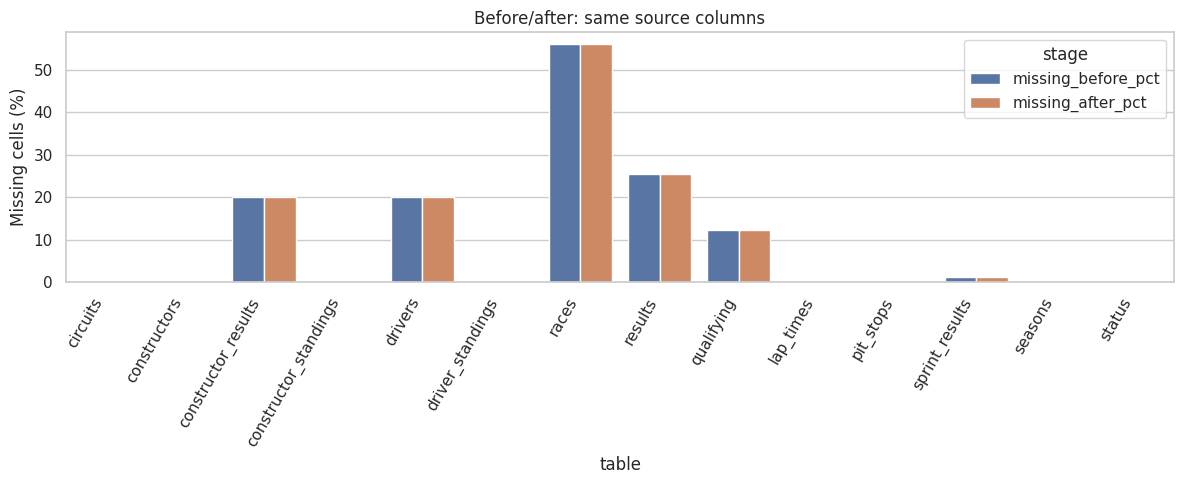

In [201]:
plot_data=cleaning_comparison.melt(id_vars='table',value_vars=['missing_before_pct','missing_after_pct'],
                                 var_name='stage',value_name='missing_pct')
plt.figure(figsize=(12,5))
sns.barplot(data=plot_data,x='table',y='missing_pct',hue='stage')
plt.xticks(rotation=60,ha='right');plt.ylabel('Missing cells (%)');plt.title('Before/after: same source columns')
plt.tight_layout()
plt.show()
plt.close()

### 28. Plot duplicate removal

Both graphs use only the retained period. One shows total rows before and after duplicate handling; the other shows extra driver–race rows. The second should reach zero.


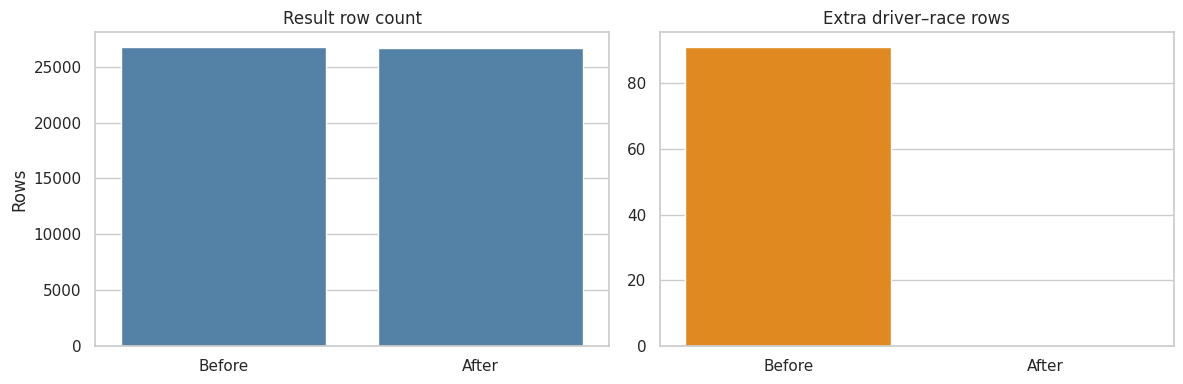

In [202]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.barplot(x=['Before','After'],y=[len(results_all),len(analysis)],ax=axes[0],color='steelblue')
axes[0].set_title('Result row count'); axes[0].set_ylabel('Rows')
sns.barplot(x=['Before','After'],y=[results_all.duplicated(pair_keys).sum(),analysis.duplicated(pair_keys).sum()],ax=axes[1],color='darkorange')
axes[1].set_title('Extra driver–race rows')
plt.tight_layout()
plt.show()
plt.close()

### 29. Plot cleaned positions

These distributions leave unknown grids and missing qualifying positions out of the histogram instead of treating them as real positions.


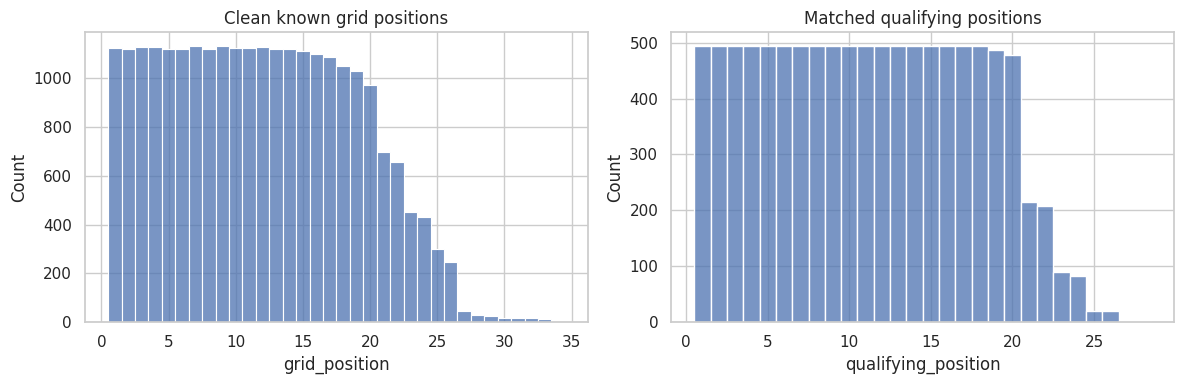

In [203]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=analysis,x='grid_position',discrete=True,ax=axes[0])
axes[0].set_title('Clean known grid positions')
sns.histplot(data=analysis,x='qualifying_position',discrete=True,ax=axes[1])
axes[1].set_title('Matched qualifying positions')
plt.tight_layout()
plt.show()
plt.close()

### 30. Compare eras

We show entries, race counts, podium rates, qualifying coverage and unknown-grid rates before and after 2014. This helps explain why results should not be compared without considering the era.


,entries,races,podium_rate,qualifying_coverage,unavailable_grid_rate
era,,,,,
1950–2013,22042,897,0.122992,0.266945,0.070593
2014–2024,4626,228,0.147860,0.996541,0.017077


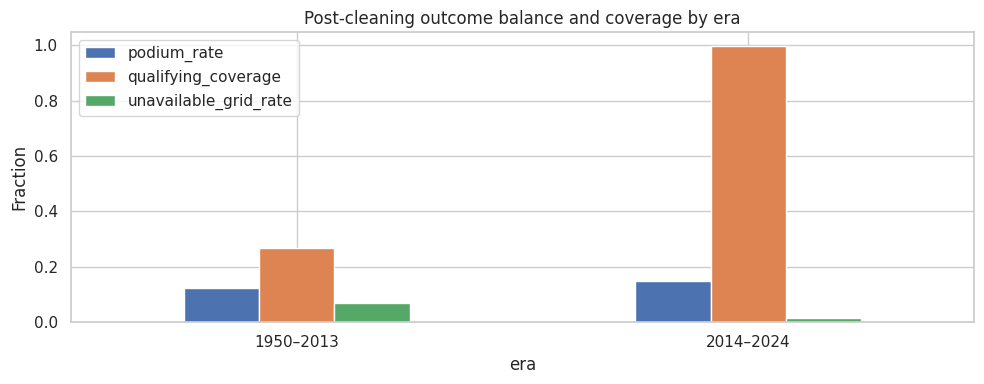

In [204]:
post_summary=analysis.groupby('era').agg(entries=('driverId','size'),races=('raceId','nunique'),
    podium_rate=('podium','mean'),qualifying_coverage=('qualifying_matched','mean'),
    unavailable_grid_rate=('grid_unavailable','mean'))
display(post_summary)
post_summary[['podium_rate','qualifying_coverage','unavailable_grid_rate']].plot.bar(figsize=(10,4))
plt.ylabel('Fraction');plt.xticks(rotation=0);plt.title('Post-cleaning outcome balance and coverage by era')
plt.tight_layout()
plt.show()
plt.close()

### 31. Compare podium rates by grid

Group drivers by starting position, then take the mean of the 0/1 podium column. A mean of 0.30 means 30% reached the podium. We only plot positions with at least 20 entries to avoid very tiny groups.


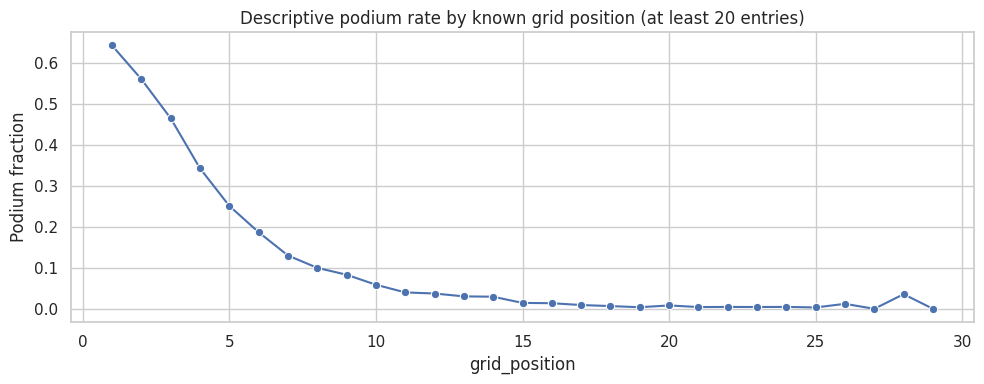

In [205]:
position_rates=(analysis.loc[analysis.grid_position.notna()].groupby('grid_position')
                .agg(entries=('podium','size'),podium_rate=('podium','mean')).reset_index())
plt.figure(figsize=(10,4))
sns.lineplot(data=position_rates.query('entries>=20'),x='grid_position',y='podium_rate',marker='o')
plt.ylabel('Podium fraction');plt.title('Descriptive podium rate by known grid position (at least 20 entries)')
plt.tight_layout()
plt.show()
plt.close()

## Question 1: Front-row starts by circuit
Which circuits turn a front-row start into a podium most often, and does the ranking change from 2014 onward?

We use actual grid positions 1 and 2. Qualifying positions are a separate measure. A circuit’s rate is **podiums from front-row entries / front-row entries**. Unknown grids cannot tell us whether the driver started on the front row.

### 32. Define the rate calculation

This short function counts observations (`n`), counts successes (`events`), and divides successes by observations. We reuse exactly the same calculation for all three questions.


In [206]:
def summarize_rate(data, groups, outcome='podium'):
    summary = data.groupby(groups, observed=True).agg(
        n=(outcome, 'size'),
        events=(outcome, 'sum')
    ).reset_index()
    summary['rate'] = summary['events'] / summary['n']
    return summary

### 33. Calculate and rank circuit rates

Calculate each era separately. Rank circuits only if they have at least 10 front-row observations in that era, roughly five races. This avoids ranking a circuit first because it had one successful race. It is a practical support rule, not a statistical test.


In [207]:
q1_front=analysis.loc[analysis['grid'].isin([1,2])].copy()
q1_rates=summarize_rate(q1_front,['era','circuitId','circuit_name'])
q1_rates['eligible']=q1_rates['n'].ge(10)
q1_ranked=q1_rates.loc[q1_rates.eligible].copy()
q1_ranked['rank']=q1_ranked.groupby('era')['rate'].rank(ascending=False,method='min')
display(q1_rates.sort_values(['era','rate'],ascending=[True,False]))

,era,circuitId,circuit_name,n,events,rate,eligible
29,1950–2013,31,Donington Park,2,2,1.000000,False
62,1950–2013,64,Ain Diab,2,2,1.000000,False
63,1950–2013,65,Pescara Circuit,2,2,1.000000,False
67,1950–2013,69,Circuit of the Americas,4,4,1.000000,False
66,1950–2013,68,Buddh International Circuit,6,5,0.833333,False
...,...,...,...,...,...,...,...
88,2014–2024,32,Autódromo Hermanos Rodríguez,18,11,0.611111,True
78,2014–2024,11,Hungaroring,22,13,0.590909,True
73,2014–2024,5,Istanbul Park,4,2,0.500000,False
84,2014–2024,20,Nürburgring,2,1,0.500000,False


### 34. Plot the circuit leaders

The table contains counts as well as rates. The graph shows the top 12 eligible circuits in each era. A rate of 0.8 means 80%.


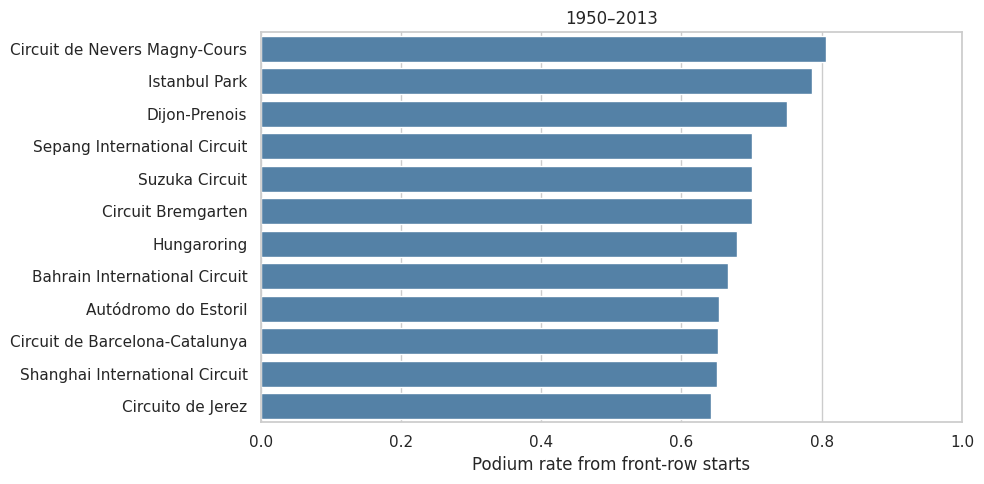

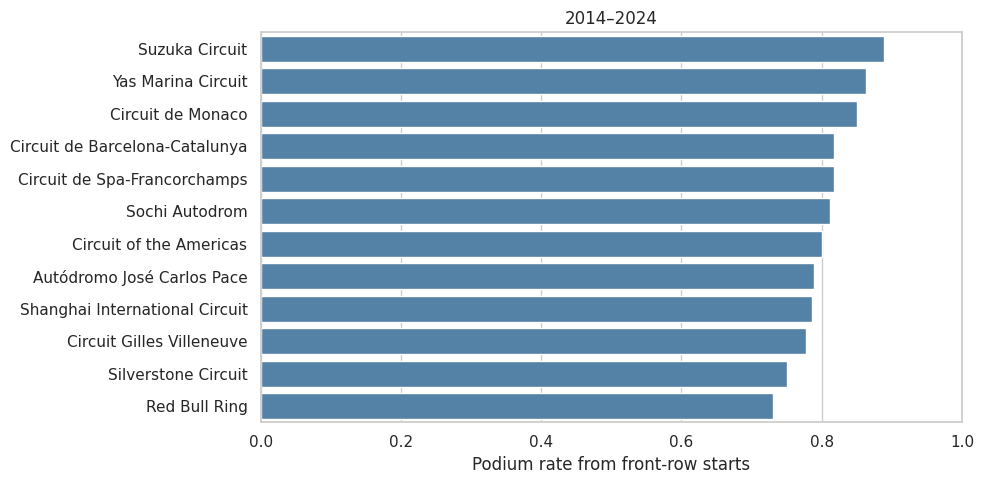

In [208]:
for era in era_labels:
    top_circuits = q1_ranked[q1_ranked['era'] == era].nlargest(12, 'rate')
    plt.figure(figsize=(10, 5))
    sns.barplot(data=top_circuits, x='rate', y='circuit_name', color='steelblue')
    plt.xlim(0, 1)
    plt.xlabel('Podium rate from front-row starts')
    plt.ylabel('')
    plt.title(era)
    plt.tight_layout()
    plt.show()
    plt.close()

### 35. Compare the same circuits across eras

`pivot` puts each era in a separate column. We keep circuits eligible in both eras and rank them again within that common set. Otherwise a rank change could just reflect different circuits entering the comparison. Negative rank change means improvement.


In [209]:
q1_common=q1_ranked.pivot(index=['circuitId','circuit_name'],columns='era',values='rate').dropna()
q1_common.columns=['rate_pre2014','rate_2014on']
q1_common['rank_pre2014']=q1_common['rate_pre2014'].rank(ascending=False,method='min')
q1_common['rank_2014on']=q1_common['rate_2014on'].rank(ascending=False,method='min')
q1_common['rank_change']=q1_common['rank_2014on']-q1_common['rank_pre2014']
q1_common=q1_common.reset_index().sort_values('rank_2014on')
display(q1_common)

,circuitId,circuit_name,rate_pre2014,rate_2014on,rank_pre2014,rank_2014on,rank_change
12,22,Suzuka Circuit,0.700000,0.888889,1.0,1.0,0.0
13,24,Yas Marina Circuit,0.600000,0.863636,6.0,2.0,-4.0
3,6,Circuit de Monaco,0.491667,0.850000,15.0,3.0,-12.0
2,4,Circuit de Barcelona-Catalunya,0.652174,0.818182,4.0,4.0,0.0
7,13,Circuit de Spa-Francorchamps,0.550562,0.818182,12.0,4.0,-8.0
11,18,Autódromo José Carlos Pace,0.596774,0.789474,8.0,6.0,-2.0
10,17,Shanghai International Circuit,0.650000,0.785714,5.0,7.0,2.0
4,7,Circuit Gilles Villeneuve,0.529412,0.777778,13.0,8.0,-5.0
5,9,Silverstone Circuit,0.563830,0.750000,10.0,9.0,-1.0
15,70,Red Bull Ring,0.520000,0.730769,14.0,10.0,-4.0


### 36. Plot the rank comparison

Each circuit has two bars. Smaller ranks are better; a change between the bars means its position in the common-circuit ranking changed.


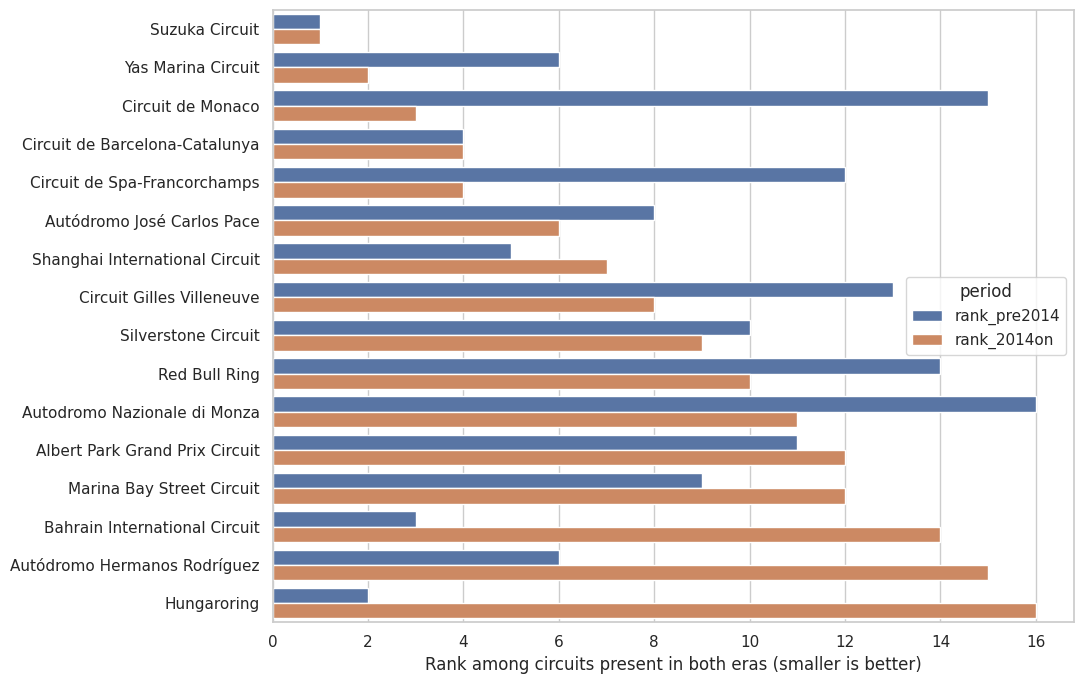

In [210]:
rank_plot = q1_common.melt(
    id_vars='circuit_name', value_vars=['rank_pre2014', 'rank_2014on'],
    var_name='period', value_name='rank'
)
plt.figure(figsize=(11, 7))
sns.barplot(data=rank_plot, y='circuit_name', x='rank', hue='period')
plt.xlabel('Rank among circuits present in both eras (smaller is better)')
plt.ylabel('')
plt.tight_layout()
plt.show()
plt.close()

### 37. Check qualifying versus starting grid

The driver who qualifies second might start elsewhere. We show differences on rows where both values are available, separating sprint weekends. Penalties are one explanation, but sprint formats and other changes also matter. Qualifying-based conversion rates are shown separately.


,n,different_fraction
is_sprint_weekend,,
False,10066,0.225015
True,341,0.460411


,era,circuitId,circuit_name,n_grid,rate_grid,n_qualifying,rate_qualifying
0,1950–2013,1,Albert Park Grand Prix Circuit,36,0.555556,32.0,0.531250
1,1950–2013,2,Sepang International Circuit,30,0.700000,24.0,0.666667
2,1950–2013,3,Bahrain International Circuit,18,0.666667,18.0,0.666667
3,1950–2013,4,Circuit de Barcelona-Catalunya,46,0.652174,30.0,0.633333
4,1950–2013,5,Istanbul Park,14,0.785714,14.0,0.785714
...,...,...,...,...,...,...,...
96,2014–2024,76,Autodromo Internazionale del Mugello,2,1.000000,2.0,1.000000
97,2014–2024,77,Jeddah Corniche Circuit,8,0.875000,8.0,0.750000
98,2014–2024,78,Losail International Circuit,6,0.500000,6.0,0.666667
99,2014–2024,79,Miami International Autodrome,6,1.000000,6.0,1.000000


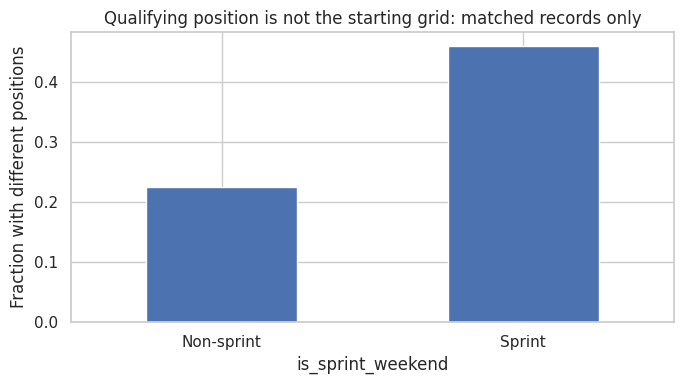

In [211]:
matched_positions=analysis.loc[analysis.grid_position.notna() & analysis.qualifying_position.notna()].copy()
matched_positions['different']=matched_positions.grid_position.ne(matched_positions.qualifying_position)
q1_position_check=matched_positions.groupby('is_sprint_weekend').agg(n=('driverId','size'),different_fraction=('different','mean'))
display(q1_position_check)
q1_qual=summarize_rate(analysis.loc[analysis.qualifying_position.isin([1,2])],['era','circuitId','circuit_name'])
q1_comparison=q1_rates[['era','circuitId','circuit_name','n','rate']].merge(
    q1_qual[['era','circuitId','n','rate']],on=['era','circuitId'],how='outer',suffixes=('_grid','_qualifying'))
display(q1_comparison)
q1_position_check['different_fraction'].plot.bar(figsize=(7,4))
plt.xticks([0,1],['Non-sprint','Sprint'],rotation=0);plt.ylabel('Fraction with different positions')
plt.title('Qualifying position is not the starting grid: matched records only')
plt.tight_layout()
plt.show()
plt.close()

### 38. Check the effect of ambiguous historical pairs

Repeat the front-row calculation after removing every pair that originally had multiple results. This shows how much the duplicate rule matters. It does not change our main answer.


In [212]:
# Historical duplicate sensitivity: exclude every affected pair, not just discarded rows.
q1_no_shared=summarize_rate(q1_front.loc[~q1_front.had_multiple_results],['era','circuitId','circuit_name'])
q1_sensitivity=q1_rates.merge(q1_no_shared,on=['era','circuitId','circuit_name'],suffixes=('_main','_no_ambiguous'))
q1_sensitivity['rate_difference']=q1_sensitivity.rate_main-q1_sensitivity.rate_no_ambiguous

display(q1_sensitivity[["era", "circuit_name", "rate_main", "rate_no_ambiguous", "rate_difference"]])

,era,circuit_name,rate_main,rate_no_ambiguous,rate_difference
0,1950–2013,Albert Park Grand Prix Circuit,0.555556,0.555556,0.0
1,1950–2013,Sepang International Circuit,0.700000,0.700000,0.0
2,1950–2013,Bahrain International Circuit,0.666667,0.666667,0.0
3,1950–2013,Circuit de Barcelona-Catalunya,0.652174,0.652174,0.0
4,1950–2013,Istanbul Park,0.785714,0.785714,0.0
...,...,...,...,...,...
96,2014–2024,Autodromo Internazionale del Mugello,1.000000,1.000000,0.0
97,2014–2024,Jeddah Corniche Circuit,0.875000,0.875000,0.0
98,2014–2024,Losail International Circuit,0.500000,0.500000,0.0
99,2014–2024,Miami International Autodrome,1.000000,1.000000,0.0


### 39. Write the answer

The text uses the calculated values rather than hardcoded numbers. These are historical rankings, not proof that a circuit itself causes a podium.

In [213]:
q1_text=[]
for era,g in q1_ranked.groupby('era'):
    top=g.loc[g.rate.eq(g.rate.max())]
    description='; '.join(f'{r.circuit_name}: {r.events}/{r.n} ({r.rate:.1%})' for r in top.itertuples())
    q1_text.append(f'- **{era}:** {description}.')
q1_changed=int(q1_common.rank_change.ne(0).sum())
q1_answer='\n'.join(q1_text)+f'\n\nAmong {len(q1_common)} commonly eligible circuits, {q1_changed} have a different rank across eras. '
q1_answer+=f'The largest absolute conversion-rate change after excluding ambiguous multi-result pairs is {q1_sensitivity.rate_difference.abs().max():.2%}. '
q1_answer+='These are observed rankings, not evidence that the circuit itself causes podiums. Team strength, drivers, field size and era are not held constant. Small samples and shared race conditions can make rankings unstable.'
display(Markdown('### Q1 answer\n'+q1_answer))

### Q1 answer
- **1950–2013:** Circuit de Nevers Magny-Cours: 29/36 (80.6%).
- **2014–2024:** Suzuka Circuit: 16/18 (88.9%).

Among 16 commonly eligible circuits, 14 have a different rank across eras. The largest absolute conversion-rate change after excluding ambiguous multi-result pairs is 17.50%. These are observed rankings, not evidence that the circuit itself causes podiums. Team strength, drivers, field size and era are not held constant. Small samples and shared race conditions can make rankings unstable.

## Question 2: Home country and podiums
Do drivers reach the podium more often at home when we compare similar starting positions?

Simply comparing all home entries with all away entries is not enough: one group might start nearer the front. We compare the groups at the **same grid position and in the same era**, then use the same weights for both groups.

### 40. Map nationality to country

“British” is a nationality, while the circuit stores “UK.” This dictionary connects them. Dual nationalities can match either country. East German→Germany and Rhodesian→Zimbabwe are explicit modern-country approximations. This measures nationality-based home country, not residence or birthplace.


In [214]:
nationality_countries = {
 'British':{'UK'}, 'German':{'Germany'}, 'Spanish':{'Spain'}, 'Finnish':{'Finland'},
 'Japanese':{'Japan'}, 'French':{'France'}, 'Polish':{'Poland'}, 'Brazilian':{'Brazil'},
 'Italian':{'Italy'}, 'Australian':{'Australia'}, 'Austrian':{'Austria'}, 'American':{'USA'},
 'Dutch':{'Netherlands'}, 'Colombian':{'Colombia'}, 'Portuguese':{'Portugal'}, 'Canadian':{'Canada'},
 'Indian':{'India'}, 'Hungarian':{'Hungary'}, 'Irish':{'Ireland'}, 'Danish':{'Denmark'},
 'Argentine':{'Argentina'}, 'Argentinian':{'Argentina'}, 'Czech':{'Czech Republic'},
 'Malaysian':{'Malaysia'}, 'Swiss':{'Switzerland'}, 'Belgian':{'Belgium'}, 'Monegasque':{'Monaco'},
 'Swedish':{'Sweden'}, 'Venezuelan':{'Venezuela'}, 'New Zealander':{'New Zealand'},
 'Chilean':{'Chile'}, 'Mexican':{'Mexico'}, 'South African':{'South Africa'},
 'Liechtensteiner':{'Liechtenstein'}, 'Rhodesian':{'Zimbabwe'}, 'American-Italian':{'USA','Italy'},
 'Uruguayan':{'Uruguay'}, 'Argentine-Italian':{'Argentina','Italy'}, 'Thai':{'Thailand'},
 'East German':{'Germany'}, 'Russian':{'Russia'}, 'Indonesian':{'Indonesia'}, 'Chinese':{'China'}
}

### 41. Mark home and away entries

For each entry, check whether the circuit country is in the driver’s country set. Unknown information stays missing instead of automatically becoming “away.”


In [215]:
analysis['country_normalized'] = analysis['circuit_country'].replace({'United States': 'USA'})
home_values = []
for nationality, country in zip(analysis['driver_nationality'], analysis['country_normalized']):
    if pd.isna(nationality) or pd.isna(country) or nationality not in nationality_countries:
        home_values.append(pd.NA)
    else:
        home_values.append(country in nationality_countries[nationality])
analysis['home_country'] = pd.array(home_values, dtype='boolean')
print('Entries with unknown home-country status:', analysis['home_country'].isna().sum())

Entries with unknown home-country status: 0


### 42. Show the unadjusted comparison

Use entries with a known positive grid and known home/away status. Exclude explicit non-start/non-qualification labels. First show raw home/away rates, then rates by grid position. These are descriptive entry counts; grid alone does not prove the driver actually took the start.


,home_label,n,events,rate
0,Away,22617,3129,0.138347
1,Home,2313,266,0.115002


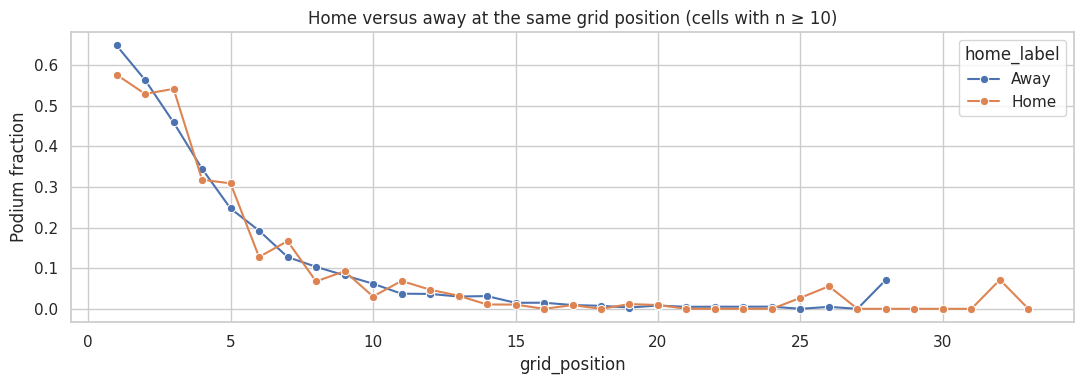

In [216]:
NON_START_STATUSES = {'Did not qualify','Did not prequalify','Withdrew','107% Rule'}
q2=analysis.loc[analysis.grid_position.notna() & analysis.home_country.notna() &
                ~analysis.status.isin(NON_START_STATUSES)].copy()
q2['home_country']=q2.home_country.astype(bool)
q2['home_label']=np.where(q2.home_country,'Home','Away')
q2_crude=summarize_rate(q2,['home_label'])
display(q2_crude)
q2_by_grid=summarize_rate(q2,['grid_position','home_label'])
plt.figure(figsize=(11,4))
sns.lineplot(data=q2_by_grid.loc[q2_by_grid.n.ge(10)],x='grid_position',y='rate',hue='home_label',marker='o')
plt.ylabel('Podium fraction');plt.title('Home versus away at the same grid position (cells with n ≥ 10)')
plt.tight_layout()
plt.show()
plt.close()

### 43. Build comparable groups

Make a separate group for every grid position and era. Count entries and podiums for home and away. We need at least five entries in each group to avoid comparisons based on one or two observations.


In [217]:
q2_groups = summarize_rate(q2, ['grid_position', 'era', 'home_country'])
home_groups = q2_groups[q2_groups['home_country']].copy()
away_groups = q2_groups[~q2_groups['home_country']].copy()

q2_comparison = home_groups.merge(
    away_groups, on=['grid_position', 'era'], suffixes=('_home', '_away'),
    validate='one_to_one'
)
q2_comparison = q2_comparison[
    (q2_comparison['n_home'] >= 5) & (q2_comparison['n_away'] >= 5)
].copy()
display(q2_comparison[['grid_position', 'era', 'n_home', 'n_away', 'rate_home', 'rate_away']])

,grid_position,era,n_home,n_away,rate_home,rate_away
0,1.0,1950–2013,77,818,0.558442,0.603912
1,1.0,2014–2024,15,213,0.666667,0.816901
2,2.0,1950–2013,79,812,0.506329,0.523399
3,2.0,2014–2024,8,218,0.750000,0.711009
4,3.0,1950–2013,81,816,0.543210,0.433824
...,...,...,...,...,...,...
46,26.0,1950–2013,36,207,0.055556,0.004831
47,27.0,1950–2013,21,22,0.000000,0.000000
48,28.0,1950–2013,13,14,0.000000,0.071429
49,29.0,1950–2013,18,6,0.000000,0.000000


### 44. Give both groups the same weights

A weight tells us how much a grid-and-era group contributes to the final average. We use its share of all retained entries. For example, if one group contains 10% of those entries, its rate gets weight 0.10 for BOTH home and away. This removes differences caused just by their grid-and-era mix.


In [218]:
q2_comparison['total_entries'] = q2_comparison['n_home'] + q2_comparison['n_away']
q2_comparison['weight'] = q2_comparison['total_entries'] / q2_comparison['total_entries'].sum()

home_adjusted = (q2_comparison['rate_home'] * q2_comparison['weight']).sum()
away_adjusted = (q2_comparison['rate_away'] * q2_comparison['weight']).sum()
difference_pp = (home_adjusted - away_adjusted) * 100

print(f'Home: {home_adjusted:.2%}')
print(f'Away: {away_adjusted:.2%}')
print(f'Home minus away: {difference_pp:+.2f} percentage points')
print('Entries retained:', q2_comparison['total_entries'].sum(), 'out of', len(q2))
assert np.isclose(q2_comparison['weight'].sum(), 1)

Home: 13.03%
Away: 13.46%
Home minus away: -0.44 percentage points
Entries retained: 23690 out of 24930


### 45. Plot and explain the adjusted comparison

A percentage-point difference is the subtraction of two percentages: 15% minus 12% is 3 percentage points. The result below controls grid and broad era, but not team strength or driver ability. We do not claim significance or a causal home advantage.


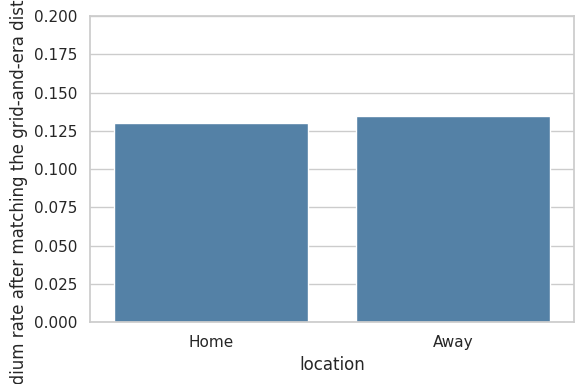

**Answer:** After giving home and away entries the same grid-and-era weights, the podium rates are **13.03% at home** and **13.46% away**. The difference is **-0.44 percentage points**. The observed home rate is lower compared with the away rate in this sample. This is a descriptive result, not a significance test or proof of a causal effect. It only describes the groups with enough home and away entries.

In [219]:
q2_adjusted = pd.DataFrame({
    'location': ['Home', 'Away'],
    'podium_rate': [home_adjusted, away_adjusted]
})
plt.figure(figsize=(6, 4))
sns.barplot(data=q2_adjusted, x='location', y='podium_rate', color='steelblue')
plt.ylabel('Podium rate after matching the grid-and-era distribution')
plt.ylim(0, 0.2)
plt.tight_layout()
plt.show()
plt.close()

q2_answer = (
    f'After giving home and away entries the same grid-and-era weights, '
    f'the podium rates are **{home_adjusted:.2%} at home** and **{away_adjusted:.2%} away**. '
    f'The difference is **{difference_pp:+.2f} percentage points**. '
    f'The observed home rate is {"higher" if difference_pp > 0 else "lower" if difference_pp < 0 else "equal"} compared with the away rate in this sample. '
    'This is a descriptive result, not a significance test '
    'or proof of a causal effect. It only describes the groups with enough home and away entries.'
)
display(Markdown('**Answer:** ' + q2_answer))

## Question 3: Mechanical retirement by constructor
Compare 2014–2021 with 2022 through the latest available year. A mechanical retirement means a car component failed and the race ended early. Crashes, driver mistakes and regulation decisions do not count.

Rate = **estimated mechanical retirements / estimated race starts**. The source has no perfect “started” flag, so the assumptions below are part of the answer.


### 46. Decide which statuses count as mechanical

Keep explicit component failures in the mechanical list. Labels such as “Retired,” puncture or wing damage do not clearly identify the cause, so they are ambiguous. They stay out of the main numerator. Out of fuel is excluded because it does not by itself show a component failure. The lists are long because the dataset has many different status labels.


In [220]:
mechanical_statuses = {
 'Engine','Gearbox','Transmission','Clutch','Hydraulics','Electrical','Radiator','Suspension',
 'Brakes','Differential','Overheating','Mechanical','Driveshaft','Fuel pressure','Water pressure',
 'Throttle','Steering','Technical','Electronics','Heat shield fire','Exhaust','Oil leak','Water leak',
 'Fuel pump','Track rod','Oil pressure','Engine fire','Engine misfire','Pneumatics','Wheel bearing',
 'Fuel system','Oil line','Launch control','Power loss','Drivetrain','Ignition','Battery','Halfshaft',
 'Crankshaft','Alternator','Oil pump','Fuel leak','Injection','Distributor','Turbo','CV joint',
 'Water pump','Spark plugs','Fuel pipe','Oil pipe','Axle','Water pipe','Magneto','Supercharger',
 'Power Unit','ERS','Brake duct','Cooling system'
}
ambiguous_statuses = {'Tyre','Driver Seat','Puncture','Retired','Front wing','Refuelling','Wheel',
 'Broken wing','Wheel rim','Tyre puncture','Wheel nut','Not classified','Handling','Rear wing',
 'Fire','Fuel rig','Fuel','Vibrations','Safety','Chassis','Stalled','Safety concerns','Not restarted',
 'Safety belt','Seat','Damage','Undertray'}
explicit_nonmechanical = {'Accident','Collision','Spun off','Out of fuel','Physical','Injured',
 'Injury','Underweight','Disqualified','Excluded','Driver unwell','Fatal accident','Eye injury',
 'Collision damage','Debris','Illness'}

### 47. Check the status classification

The function assigns each label to a group. “Finished” and “+1 Lap,” for example, are not mechanical retirements. The assertion catches a label we forgot to consider. Status labels are still imperfect: a listed component failure might have followed contact.


In [221]:
def classify_status(s):
    if s in mechanical_statuses: return 'Mechanical (primary)'
    if s in ambiguous_statuses: return 'Ambiguous (sensitivity only)'
    if s in NON_START_STATUSES: return 'Explicit non-start / non-qualifier'
    if s=='Finished' or (s.startswith('+') and 'Lap' in s): return 'Finished / lapped'
    if s in explicit_nonmechanical: return 'Non-mechanical'
    return 'Unmapped'

status_dictionary=clean['status'].copy()
status_dictionary['classification']=status_dictionary.status.map(classify_status)
assert not status_dictionary.classification.eq('Unmapped').any(), 'Review unknown statuses.'
display(status_dictionary)

,statusId,status,classification
0,1,Finished,Finished / lapped
1,2,Disqualified,Non-mechanical
2,3,Accident,Non-mechanical
3,4,Collision,Non-mechanical
4,5,Engine,Mechanical (primary)
...,...,...,...
134,137,Damage,Ambiguous (sensitivity only)
135,138,Debris,Non-mechanical
136,139,Illness,Non-mechanical
137,140,Undertray,Ambiguous (sensitivity only)


### 48. Decide which entries count as starts and early endings

Exclude explicit non-starters. Otherwise count a start when grid is positive OR at least one lap was completed. This retains known-grid zero-lap retirements and pit-lane starters with laps. Zero-grid/zero-lap records remain uncertain and are excluded. Fewer laps than the race maximum is our early-ending proxy, not an exact retirement timestamp.


In [222]:
analysis['status_classification']=analysis.status.map(classify_status)
analysis['estimated_start']=(~analysis.status.isin(NON_START_STATUSES) & (analysis.grid.gt(0)|analysis.laps.gt(0)))
max_laps=results_all.groupby('raceId')['laps'].max()
analysis['fewer_than_race_max_laps']=analysis.laps.lt(analysis.raceId.map(max_laps))
q3_all=analysis.loc[analysis.year.between(2014,LATEST_YEAR)].copy()
q3_periods = ['2014–2021', f'2022–{LATEST_YEAR}']
q3_all['period']=np.where(q3_all.year.le(2021), *q3_periods)
q3_excluded=q3_all.loc[~q3_all.estimated_start].copy()
display(q3_excluded[['year','raceId','driver_name','constructor_name','grid','laps','status']])
q3=q3_all.loc[q3_all.estimated_start].copy()
q3['mechanical_retirement']=(q3.status.isin(mechanical_statuses)&q3.fewer_than_race_max_laps).astype(int)
q3['ambiguous_retirement']=(q3.status.isin(ambiguous_statuses)&q3.fewer_than_race_max_laps).astype(int)
q3['broad_retirement']=(q3.mechanical_retirement.eq(1)|q3.ambiguous_retirement.eq(1)).astype(int)

,year,raceId,driver_name,constructor_name,grid,laps,status
22076,2014,901,Sergio Pérez,Force India,14,0,Withdrew
22163,2014,905,Pastor Maldonado,Lotus F1,15,0,Withdrew
22460,2015,926,Valtteri Bottas,Williams,0,0,Withdrew
22461,2015,926,Kevin Magnussen,McLaren,17,0,Withdrew
22462,2015,926,Daniil Kvyat,Red Bull,12,0,Withdrew
22482,2015,927,Will Stevens,Manor Marussia,0,0,Fuel system
23142,2016,962,Romain Grosjean,Haas F1 Team,20,0,Withdrew
23252,2016,967,Romain Grosjean,Haas F1 Team,7,0,Withdrew
23571,2017,983,Kimi Räikkönen,Ferrari,0,0,Battery
24466,2019,1027,Lando Norris,McLaren,8,48,Withdrew


### 49. Calculate constructor rates

Separate constructor IDs rather than combining rebrands. Calculate counts and rates for each period. Only rank constructors with at least 20 estimated starts; this avoids tiny samples dominating.


In [223]:
q3_rates=summarize_rate(q3,['period','constructorId','constructor_name'],'mechanical_retirement')
q3_rates['eligible']=q3_rates.n.ge(20)
q3_rates['rank']=q3_rates.where(q3_rates.eligible).groupby('period')['rate'].rank(ascending=False,method='min')
display(q3_rates.sort_values(['period','rate'],ascending=[True,False]))

,period,constructorId,constructor_name,n,events,rate,eligible,rank
12,2014–2021,207,Caterham,34,8,0.235294,True,1.0
13,2014–2021,208,Lotus F1,75,13,0.173333,True,2.0
3,2014–2021,5,Toro Rosso,242,39,0.161157,True,3.0
0,2014–2021,1,McLaren,318,43,0.135220,True,4.0
2,2014–2021,4,Renault,200,27,0.135000,True,5.0
...,...,...,...,...,...,...,...,...
30,2022–2024,215,RB F1 Team,48,2,0.041667,True,8.0
19,2022–2024,1,McLaren,136,5,0.036765,True,9.0
22,2022–2024,9,Red Bull,136,5,0.036765,True,9.0
25,2022–2024,117,Aston Martin,133,4,0.030075,True,11.0


### 50. Plot the constructor comparison

Each chart compares constructors within one period. Read the count table too: the same percentage can be based on very different numbers of starts.


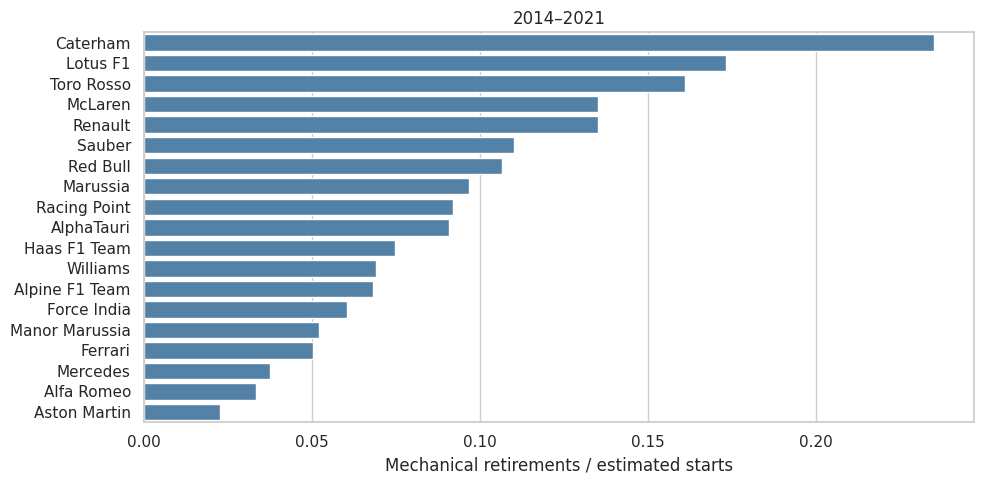

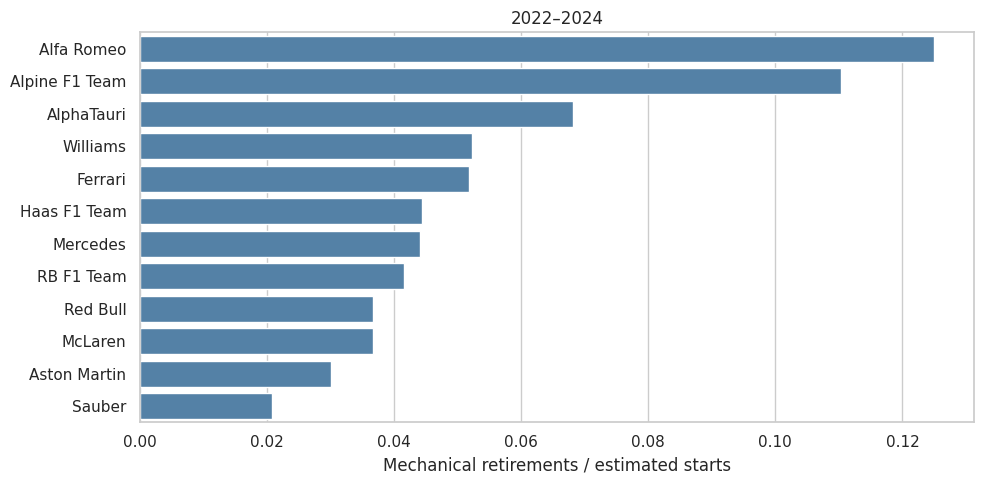

In [224]:
for period in q3_periods:
    constructor_rates = q3_rates[(q3_rates['period'] == period) & q3_rates['eligible']]
    constructor_rates = constructor_rates.sort_values('rate', ascending=False)
    plt.figure(figsize=(10, 5))
    sns.barplot(data=constructor_rates, x='rate', y='constructor_name', color='steelblue')
    plt.xlabel('Mechanical retirements / estimated starts')
    plt.ylabel('')
    plt.title(period)
    plt.tight_layout()
    plt.show()
    plt.close()

### 51. Check alternative assumptions

The broad rate also counts ambiguous early-ending statuses; it is not our main result. The positive-laps-only rate drops zero-lap entries. These alternatives show how the uncertain status and start definitions affect the numbers.


In [225]:
q3_broad=summarize_rate(q3,['period','constructorId','constructor_name'],'broad_retirement')
q3_positive_laps=summarize_rate(q3.loc[q3.laps.gt(0)],['period','constructorId','constructor_name'],'mechanical_retirement')
q3_sensitivity=q3_rates[['period','constructorId','constructor_name','n','events','rate']].merge(
    q3_broad[['period','constructorId','rate']],on=['period','constructorId'],suffixes=('_primary','_broad'))
q3_sensitivity=q3_sensitivity.merge(q3_positive_laps[['period','constructorId','n','rate']].rename(
    columns={'n':'completed_lap_entries','rate':'rate_positive_laps_only'}),on=['period','constructorId'])
display(q3_sensitivity)
q3_status_counts=q3.groupby(['period','status','status_classification']).size().rename('entries').reset_index()
display(q3_status_counts)
print('Mechanical labels not meeting early-ending proxy:', int((q3.status.isin(mechanical_statuses)&~q3.fewer_than_race_max_laps).sum()))
print('Included zero-lap entries:', int(q3.laps.eq(0).sum()))

,period,constructorId,constructor_name,n,events,rate_primary,rate_broad,completed_lap_entries,rate_positive_laps_only
0,2014–2021,1,McLaren,318,43,0.135220,0.160377,309,0.126214
1,2014–2021,3,Williams,319,22,0.068966,0.090909,311,0.070740
2,2014–2021,4,Renault,200,27,0.135000,0.160000,194,0.128866
3,2014–2021,5,Toro Rosso,242,39,0.161157,0.181818,234,0.162393
4,2014–2021,6,Ferrari,319,16,0.050157,0.065831,308,0.045455
...,...,...,...,...,...,...,...,...,...
26,2022–2024,131,Mercedes,136,6,0.044118,0.044118,133,0.045113
27,2022–2024,210,Haas F1 Team,135,6,0.044444,0.051852,130,0.046154
28,2022–2024,213,AlphaTauri,88,6,0.068182,0.079545,85,0.047059
29,2022–2024,214,Alpine F1 Team,136,15,0.110294,0.110294,133,0.105263


,period,status,status_classification,entries
0,2014–2021,+1 Lap,Finished / lapped,911
1,2014–2021,+2 Laps,Finished / lapped,182
2,2014–2021,+3 Laps,Finished / lapped,24
3,2014–2021,+4 Laps,Finished / lapped,6
4,2014–2021,+5 Laps,Finished / lapped,1
...,...,...,...,...
91,2022–2024,Undertray,Ambiguous (sensitivity only),4
92,2022–2024,Vibrations,Ambiguous (sensitivity only),1
93,2022–2024,Water leak,Mechanical (primary),2
94,2022–2024,Water pressure,Mechanical (primary),3


Mechanical labels not meeting early-ending proxy: 1
Included zero-lap entries: 125


### 52. Write the answer

Report the leading constructors with both counts and percentages. These remain estimates based on the documented definitions, rather than independently verified incident histories.


In [226]:
q3_lines=[]
for period,g in q3_rates.loc[q3_rates.eligible].groupby('period'):
    top=g.loc[g.rate.eq(g.rate.max())]
    leaders='; '.join(f'{r.constructor_name}: {r.events}/{r.n} ({r.rate:.2%})' for r in top.itertuples())
    q3_lines.append(f'- **{period}:** {leaders}.')
q3_answer='\n'.join(q3_lines)
q3_answer+=f'\n\nThe start rule excludes {len(q3_excluded)} recorded entries in 2014–{LATEST_YEAR}. '
q3_answer+=f'There are {int(q3.ambiguous_retirement.sum())} included starts with ambiguous early-ending statuses, excluded from the primary numerator. '
q3_answer+='The full tables show every constructor’s denominator and alternative rates. Team rebrands are separate constructor IDs; the result compares those recorded identities, not continuous organizations. Component status labels do not prove the absence of preceding contact, so these are status-based estimates rather than independently verified incident classifications.'
display(Markdown('### Q3 answer\n'+q3_answer))

### Q3 answer
- **2014–2021:** Caterham: 8/34 (23.53%).
- **2022–2024:** Alfa Romeo: 11/88 (12.50%).

The start rule excludes 18 recorded entries in 2014–2024. There are 90 included starts with ambiguous early-ending statuses, excluded from the primary numerator. The full tables show every constructor’s denominator and alternative rates. Team rebrands are separate constructor IDs; the result compares those recorded identities, not continuous organizations. Component status labels do not prove the absence of preceding contact, so these are status-based estimates rather than independently verified incident classifications.

## Save the results for the team
The full analysis table contains race outcomes, so **do not feed all its columns into a model**. Current-race points, status, laps, finishing order, fastest laps and pit stops are future information at the prediction cutoff.

The smaller `pre_race_base` contains basic candidate inputs, IDs, the target and the duplicate flag. It is not the finished modeling table. The target is a label, not a feature. The duplicate flag is for excluding ambiguous historical pairs, not for predicting podiums. The modeling teammate still needs past-only form/standings, a chronological split and training-only preprocessing.

### 53. Save a few useful CSVs

Save the full historical analysis, a smaller pre-race handoff table and discarded duplicate rows. Only the output folder is written. The original CSVs remain unchanged. The `clean` dictionary also remains available for the next team section.


In [227]:
pre_race_columns = ['raceId', 'driverId', 'date', 'year', 'era', 'round', 'circuitId', 'constructorId',
                   'grid_position', 'qualifying_position', 'q1_seconds', 'q2_seconds', 'q3_seconds',
                   'age_at_race', 'home_country', 'podium', 'had_multiple_results']
pre_race_base = analysis[pre_race_columns].copy()
assert not pre_race_base.duplicated(['raceId', 'driverId']).any()
assert pre_race_base['podium'].isin([0, 1]).all()

output_folder = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('student_outputs')
output_folder.mkdir(exist_ok=True)
analysis.to_csv(output_folder / 'f1_analysis.csv', index=False)
pre_race_base.to_csv(output_folder / 'f1_pre_race_base.csv', index=False)
discarded_results.to_csv(output_folder / 'discarded_duplicates.csv', index=False)

print('Final driver–race rows:', len(analysis))
print('Saved to:', output_folder.resolve())

Final driver–race rows: 26668
Saved to: /kaggle/working


## What to remember when explaining this work
- **EDA:** inspect counts, missingness, coverage and distributions before making decisions.
- **Cleaning:** fix representations and duplicate entries without inventing missing information.
- **Joins:** connect tables using IDs and check that joining does not multiply rows.
- **Q1:** use actual grid 1–2, divide podiums by front-row observations, and compare the same circuits across eras.
- **Q2:** compare home and away using the same grid-and-era distribution, not just raw averages.
- **Q3:** define mechanical failure and estimated starts explicitly, then divide failures by starts.
- **Limits:** historical qualifying is incomplete, nationality is only a home proxy, and start/status records are imperfect. These comparisons do not establish causation.

This completes EDA, cleaning and the three analysis questions. The separate sections below cover feature selection, past-only form engineering and preprocessing experiments. Final model comparison and held-out test evaluation remain separate team tasks.

## Feature Selection
We predict whether a driver reaches the podium **after qualifying and before the Grand Prix**. The recorded starting grid is a proxy for the grid known at that cutoff; the archive does not contain timestamped grid revisions. If the grid was not known then, omit it. Current-race outcomes are labels or historical inputs for later races, never predictors for the same race.

### 54. Build leakage-safe recent-form features
Use each driver's previous five appearances and each constructor's previous five races. Shift outcomes by one race **before** rolling averages. Constructor points are first averaged across its drivers within a race, so the current teammate's outcome cannot enter another driver's predictor. History uses all available years; early entries have limited history, which we record explicitly. Exclude ambiguous multi-result pairs from the modeling data and its history.

### Why combine era, season normalization and missingness?
These components address different problems while retaining historical races:

| Component | Implementation | Reason |
| --- | --- | --- |
| Era | Existing before-2014 / 2014-onward category, one-hot encoded; retain numeric year | Allows a broad period effect alongside gradual calendar trends. It is a coarse grouping, not a complete history of regulation changes. |
| Within-season normalization | Replace raw recent driver/team points with season-relative scores based only on earlier dates | Reduces dependence on the absolute points scale across seasons without using future results. |
| Missing-data indicators | One binary flag per numeric input, calculated before imputation | Distinguishes unavailable qualifying, unknown grid or insufficient history from an observed performance value. |

**Exact normalization.** First average each driver's points over their previous five appearances **in the current season**. For a constructor, average points per driver within each previous race, then average the constructor's previous five races in that season. For both, compute:

`normalized_recent_points = (recent_points_mean - prior_season_points_mean) / prior_season_points_std`

The reference mean and population standard deviation use all eligible driver–race points from **strictly earlier race dates in the same season**. A value of +1 means the recent points average is one reference standard deviation above the earlier season-wide per-driver mean. Team form uses the same per-driver reference, making its scale interpretable in the same units. This is a relative score, not a probability or a z-score of the sampling distribution of a five-race mean.

**Example.** If the earlier season reference has mean 4 and standard deviation 6, recent averages of 10 and 4 become +1 and 0. If a scoring system simply doubles every points value, both the mean and standard deviation double and these scores stay the same. Actual scoring changes need not be simple multipliers, so comparability remains imperfect.

**Why not normalize using the complete season?** A complete-season mean/std would include races that had not happened at prediction time. We instead update the reference after each completed race date. Earlier validation/test outcomes may update later-race history, matching the notebook's existing next-race evaluation; we never use later outcomes for an earlier prediction. Starting a new season resets points history and its reference. The podium and finishing-position history still uses career appearances; existing history counts describe that general career history, not the current-season normalization sample.

**Cold starts and missing records.** A first season race has no reference; a driver/team's first season appearance has no season points history; a zero-variance reference cannot be standardized. These cases remain NaN. The pipeline records a 1 missing flag, then fills the value using training-only imputation. It does not replace unknown performance with zero, discard the row, or borrow a previous season's points scale. A first race therefore has less usable points information. Missing flags indicate availability, not the reason a record is missing; historical coverage can itself act as an era proxy.

**Two separate scaling stages.** Season normalization defines meaningful historical features using information available at each race. The later training-only StandardScaler handles numerical conditioning for the linear model and FNN. Era and missing flags complement the normalized features; none guarantees improved predictions, so use the existing validation and ablation results to evaluate the combination.


In [228]:
model_data = analysis.loc[~analysis['had_multiple_results']].copy()
model_data = model_data.sort_values(['date', 'raceId', 'driverId'], kind='stable').reset_index(drop=True)
assert not model_data.duplicated(['driverId', 'date']).any(), 'Review same-day driver races before calculating history.'
assert model_data['points'].notna().all()

def past_five_mean(series):
    return series.shift(1).rolling(5, min_periods=1).mean()

# Non-points form retains the previous five career appearances.
for source, feature in [('podium', 'driver_podium_rate_last5'),
                        ('positionOrder', 'driver_finish_last5')]:
    model_data[feature] = model_data.groupby('driverId', sort=False)[source].transform(past_five_mean)
model_data['driver_history_count'] = model_data.groupby('driverId', sort=False).cumcount().clip(upper=5)
model_data['driver_history_date'] = model_data.groupby('driverId', sort=False)['date'].shift(1)

# Points history resets at the season boundary to avoid mixing scoring systems.
model_data['driver_points_last5'] = model_data.groupby(['year', 'driverId'], sort=False)['points'].transform(past_five_mean)
constructor_history = (model_data.groupby(['year', 'constructorId', 'raceId', 'date'], as_index=False)
                       .agg(points_per_driver=('points', 'mean'))
                       .sort_values(['date', 'raceId', 'constructorId'], kind='stable'))
assert not constructor_history.duplicated(['constructorId', 'date']).any()
constructor_history['constructor_points_last5'] = constructor_history.groupby(['year', 'constructorId'])['points_per_driver'].transform(past_five_mean)
constructor_history['constructor_history_count'] = constructor_history.groupby('constructorId').cumcount().clip(upper=5)
constructor_history['constructor_history_date'] = constructor_history.groupby('constructorId')['date'].shift(1)
model_data = model_data.merge(constructor_history[['raceId', 'constructorId', 'constructor_points_last5',
    'constructor_history_count', 'constructor_history_date']], on=['raceId', 'constructorId'], validate='many_to_one')

# One reference per season/date: ALL reference outcomes precede the predicted date.
# Grouping dates also prevents two races on the same date from leaking into one another.
def prior_season_points_reference(frame):
    daily = (frame.assign(points_squared=frame['points'].astype(float).pow(2))
             .groupby(['year', 'date'], as_index=False)
             .agg(points_sum=('points', 'sum'), points_sq_sum=('points_squared', 'sum'),
                  entries=('points', 'size'))
             .sort_values(['year', 'date']))
    for column in ['points_sum', 'points_sq_sum', 'entries']:
        daily['prior_' + column] = daily.groupby('year')[column].transform(lambda s: s.cumsum().shift(1))
    count = daily['prior_entries'].where(daily['prior_entries'].gt(0))
    mean = daily['prior_points_sum'] / count
    variance = (daily['prior_points_sq_sum'] / count - mean.pow(2)).clip(lower=0)
    daily['season_points_mean_prior'] = mean
    daily['season_points_std_prior'] = np.sqrt(variance).where(variance.gt(1e-12))
    daily['season_reference_date'] = daily.groupby('year')['date'].shift(1)
    return daily[['year', 'date', 'season_points_mean_prior', 'season_points_std_prior',
                  'season_reference_date']]

season_reference = prior_season_points_reference(model_data)
model_data = model_data.merge(season_reference, on=['year', 'date'], validate='many_to_one')
for source, feature in [('driver_points_last5', 'driver_points_season_z_last5'),
                        ('constructor_points_last5', 'constructor_points_season_z_last5')]:
    model_data[feature] = ((model_data[source] - model_data['season_points_mean_prior']) /
                          model_data['season_points_std_prior'])
    assert np.isfinite(model_data[feature].dropna()).all()
for column in ['driver_history_date', 'constructor_history_date', 'season_reference_date']:
    assert (model_data[column].isna() | model_data[column].lt(model_data['date'])).all(), 'History must precede the predicted race.'
display(model_data[['date', 'driver_name', 'points', 'driver_points_last5',
    'season_points_mean_prior', 'season_points_std_prior', 'driver_points_season_z_last5',
    'constructor_points_season_z_last5']].head(12))
print('History and season-normalization audits passed: all outcome-derived inputs use earlier race dates only.')


,date,driver_name,points,driver_points_last5,season_points_mean_prior,season_points_std_prior,driver_points_season_z_last5,constructor_points_season_z_last5
0,1950-05-13,Juan Fangio,0.0,NaN,<NA>,<NA>,<NA>,<NA>
1,1950-05-13,Louis Chiron,0.0,NaN,<NA>,<NA>,<NA>,<NA>
2,1950-05-13,Bob Gerard,0.0,NaN,<NA>,<NA>,<NA>,<NA>
3,1950-05-13,Louis Rosier,2.0,NaN,<NA>,<NA>,<NA>,<NA>
4,1950-05-13,Toulo de Graffenried,0.0,NaN,<NA>,<NA>,<NA>,<NA>
5,1950-05-13,Nino Farina,9.0,NaN,<NA>,<NA>,<NA>,<NA>
6,1950-05-13,Johnny Claes,0.0,NaN,<NA>,<NA>,<NA>,<NA>
7,1950-05-13,Peter Walker,0.0,NaN,<NA>,<NA>,<NA>,<NA>
8,1950-05-13,Tony Rolt,0.0,NaN,<NA>,<NA>,<NA>,<NA>
9,1950-05-13,Prince Bira,0.0,NaN,<NA>,<NA>,<NA>,<NA>


History and season-normalization audits passed: all outcome-derived inputs use earlier race dates only.


### 55. Choose features and split chronologically
Keep whole races together: earliest 70% of races for training, next 15% for validation, final 15% for testing. We reserve the test data and do not use it for plots, preprocessing choices or model selection. Form features can use earlier validation/test race outcomes once those races have finished: this simulates updating predictions one race at a time, not forecasting an entire future season at once.

| Chosen feature | Reason and evidence to inspect |
| --- | --- |
| Starting grid and qualifying position | Pre-race competitive position; inspect the training podium-rate plots. |
| Driver's past-five points, podium rate and finishing position | Recent results reflect observed form; inspect training outcome rates across form bins. Use within-season normalized points from earlier dates; keep season year and era for remaining period differences. |
| Constructor's season-normalized past-five points per driver | Relative team form using earlier same-season races, without the current teammate's outcome. |
| Driver and constructor history counts | Distinguish limited/no history from reliably observed form. |
| Driver age, home-country flag and season year | Contextual candidates; evidence may be weak, so report it without claiming a causal effect. |
| Racing era (before 2014 versus 2014 onward) | Existing year-based grouping, one-hot encoded alongside numeric year; check training/validation era coverage. |
| Circuit and constructor identity | Track context and team identity; encode as categories, never ordered numeric IDs. |

Era adds a baseline offset in the linear model; the FNN can learn interactions with other inputs. Season normalization separately reduces points-scale differences; neither component guarantees transfer to an era absent from training. Numeric missing flags preserve availability before imputation.

Exclude raw Q1/Q2/Q3 times from this baseline because lap durations are not comparable across circuits and Q2/Q3 availability depends on elimination. Exclude driver identity to limit memorization. Current-race points, laps, status, positionOrder, fastest laps, pit stops and sprint outcomes are excluded. Retaining a candidate is a hypothesis; the evidence below is descriptive, not proof of independent predictive value.

In [229]:
numeric_features = ['grid_position', 'qualifying_position', 'age_at_race', 'year', 'home_country',
                    'driver_points_season_z_last5', 'driver_podium_rate_last5', 'driver_finish_last5',
                    'constructor_points_season_z_last5', 'driver_history_count', 'constructor_history_count']
# Reuse the existing pre-2014 / 2014-onward era, derived only from race year.
# Keep numeric year as well, to represent gradual changes within each era.
categorical_features = ['circuitId', 'constructorId', 'era']
selected_features = numeric_features + categorical_features
forbidden_features = {'podium', 'points', 'positionOrder', 'laps', 'status', 'fastestLapTime',
                      'elapsed_seconds', 'driver_history_date', 'constructor_history_date', 'season_reference_date',
                      'driver_points_last5', 'constructor_points_last5', 'season_points_mean_prior', 'season_points_std_prior'}
assert not forbidden_features.intersection(selected_features)
X = model_data[selected_features].copy()
for column in numeric_features:
    X[column] = pd.to_numeric(X[column], errors='coerce').astype(float)
for column in categorical_features:
    X[column] = X[column].astype('string').fillna('Unknown').astype(str)
y = model_data['podium'].astype(int)
race_order = model_data[['raceId', 'date']].drop_duplicates().sort_values(['date', 'raceId'])
assert len(race_order) >= 20, 'Too few races for this three-way split.'
n_train = int(len(race_order) * 0.70)
n_validation_end = int(len(race_order) * 0.85)
train_ids = race_order.iloc[:n_train]['raceId']
validation_ids = race_order.iloc[n_train:n_validation_end]['raceId']
test_ids = race_order.iloc[n_validation_end:]['raceId']
train_mask = model_data['raceId'].isin(train_ids)
validation_mask = model_data['raceId'].isin(validation_ids)
test_mask = model_data['raceId'].isin(test_ids)
assert model_data.loc[train_mask, 'date'].max() < model_data.loc[validation_mask, 'date'].min()
assert model_data.loc[validation_mask, 'date'].max() < model_data.loc[test_mask, 'date'].min()
X_train, X_validation, X_test = X.loc[train_mask], X.loc[validation_mask], X.loc[test_mask]
y_train, y_validation, y_test = y.loc[train_mask], y.loc[validation_mask], y.loc[test_mask]
assert y_train.nunique() == y_validation.nunique() == 2
split_summary = pd.DataFrame([{'split': name, 'races': model_data.loc[mask, 'raceId'].nunique(),
    'entries': int(mask.sum()), 'first_date': model_data.loc[mask, 'date'].min(),
    'last_date': model_data.loc[mask, 'date'].max()} for name, mask in
    [('Train', train_mask), ('Validation', validation_mask), ('Test (reserved)', test_mask)]])
display(split_summary)
# Coverage audit only: the encoder is still fitted on training data alone.
era_split_coverage = pd.DataFrame({
    'Train': X_train['era'].value_counts(),
    'Validation': X_validation['era'].value_counts(),
}).fillna(0).astype(int)
display(era_split_coverage.rename_axis('era'))
unseen_validation_eras = sorted(set(X_validation['era']) - set(X_train['era']))
if unseen_validation_eras:
    print('Validation eras absent from training:', unseen_validation_eras,
          '\nThe encoder accepts them, but the model cannot learn an era-specific effect without training examples.')

,split,races,entries,first_date,last_date
0,Train,787,19483,1950-05-13,2008-03-23
1,Validation,169,3721,2008-04-06,2016-11-27
2,Test (reserved),169,3379,2017-03-26,2024-12-08


,Train,Validation
era,,
1950–2013,19483,2474
2014–2024,0,1247


Validation eras absent from training: ['2014–2024'] 
The encoder accepts them, but the model cannot learn an era-specific effect without training examples.


### 56. Plot feature associations and report evidence
Use **training data only**. Each point shows a group's observed podium rate and its sample size is saved in the evidence table. Continuous values use quantile bins; grid and qualifying use actual positions. These associations can reflect team strength, era and other confounders, so they do not establish causation. Missing values form their own group rather than being interpreted as zero performance.

,feature,feature_group,entries,podiums,podium_rate
0,grid_position,1.0,777,451,0.580438
1,grid_position,10.0,783,52,0.066411
2,grid_position,11.0,787,37,0.047014
3,grid_position,12.0,783,35,0.044700
4,grid_position,13.0,781,27,0.034571
...,...,...,...,...,...
365,constructorId,96,1,0,0.000000
366,constructorId,97,6,0,0.000000
367,constructorId,98,2,0,0.000000
368,constructorId,99,11,0,0.000000


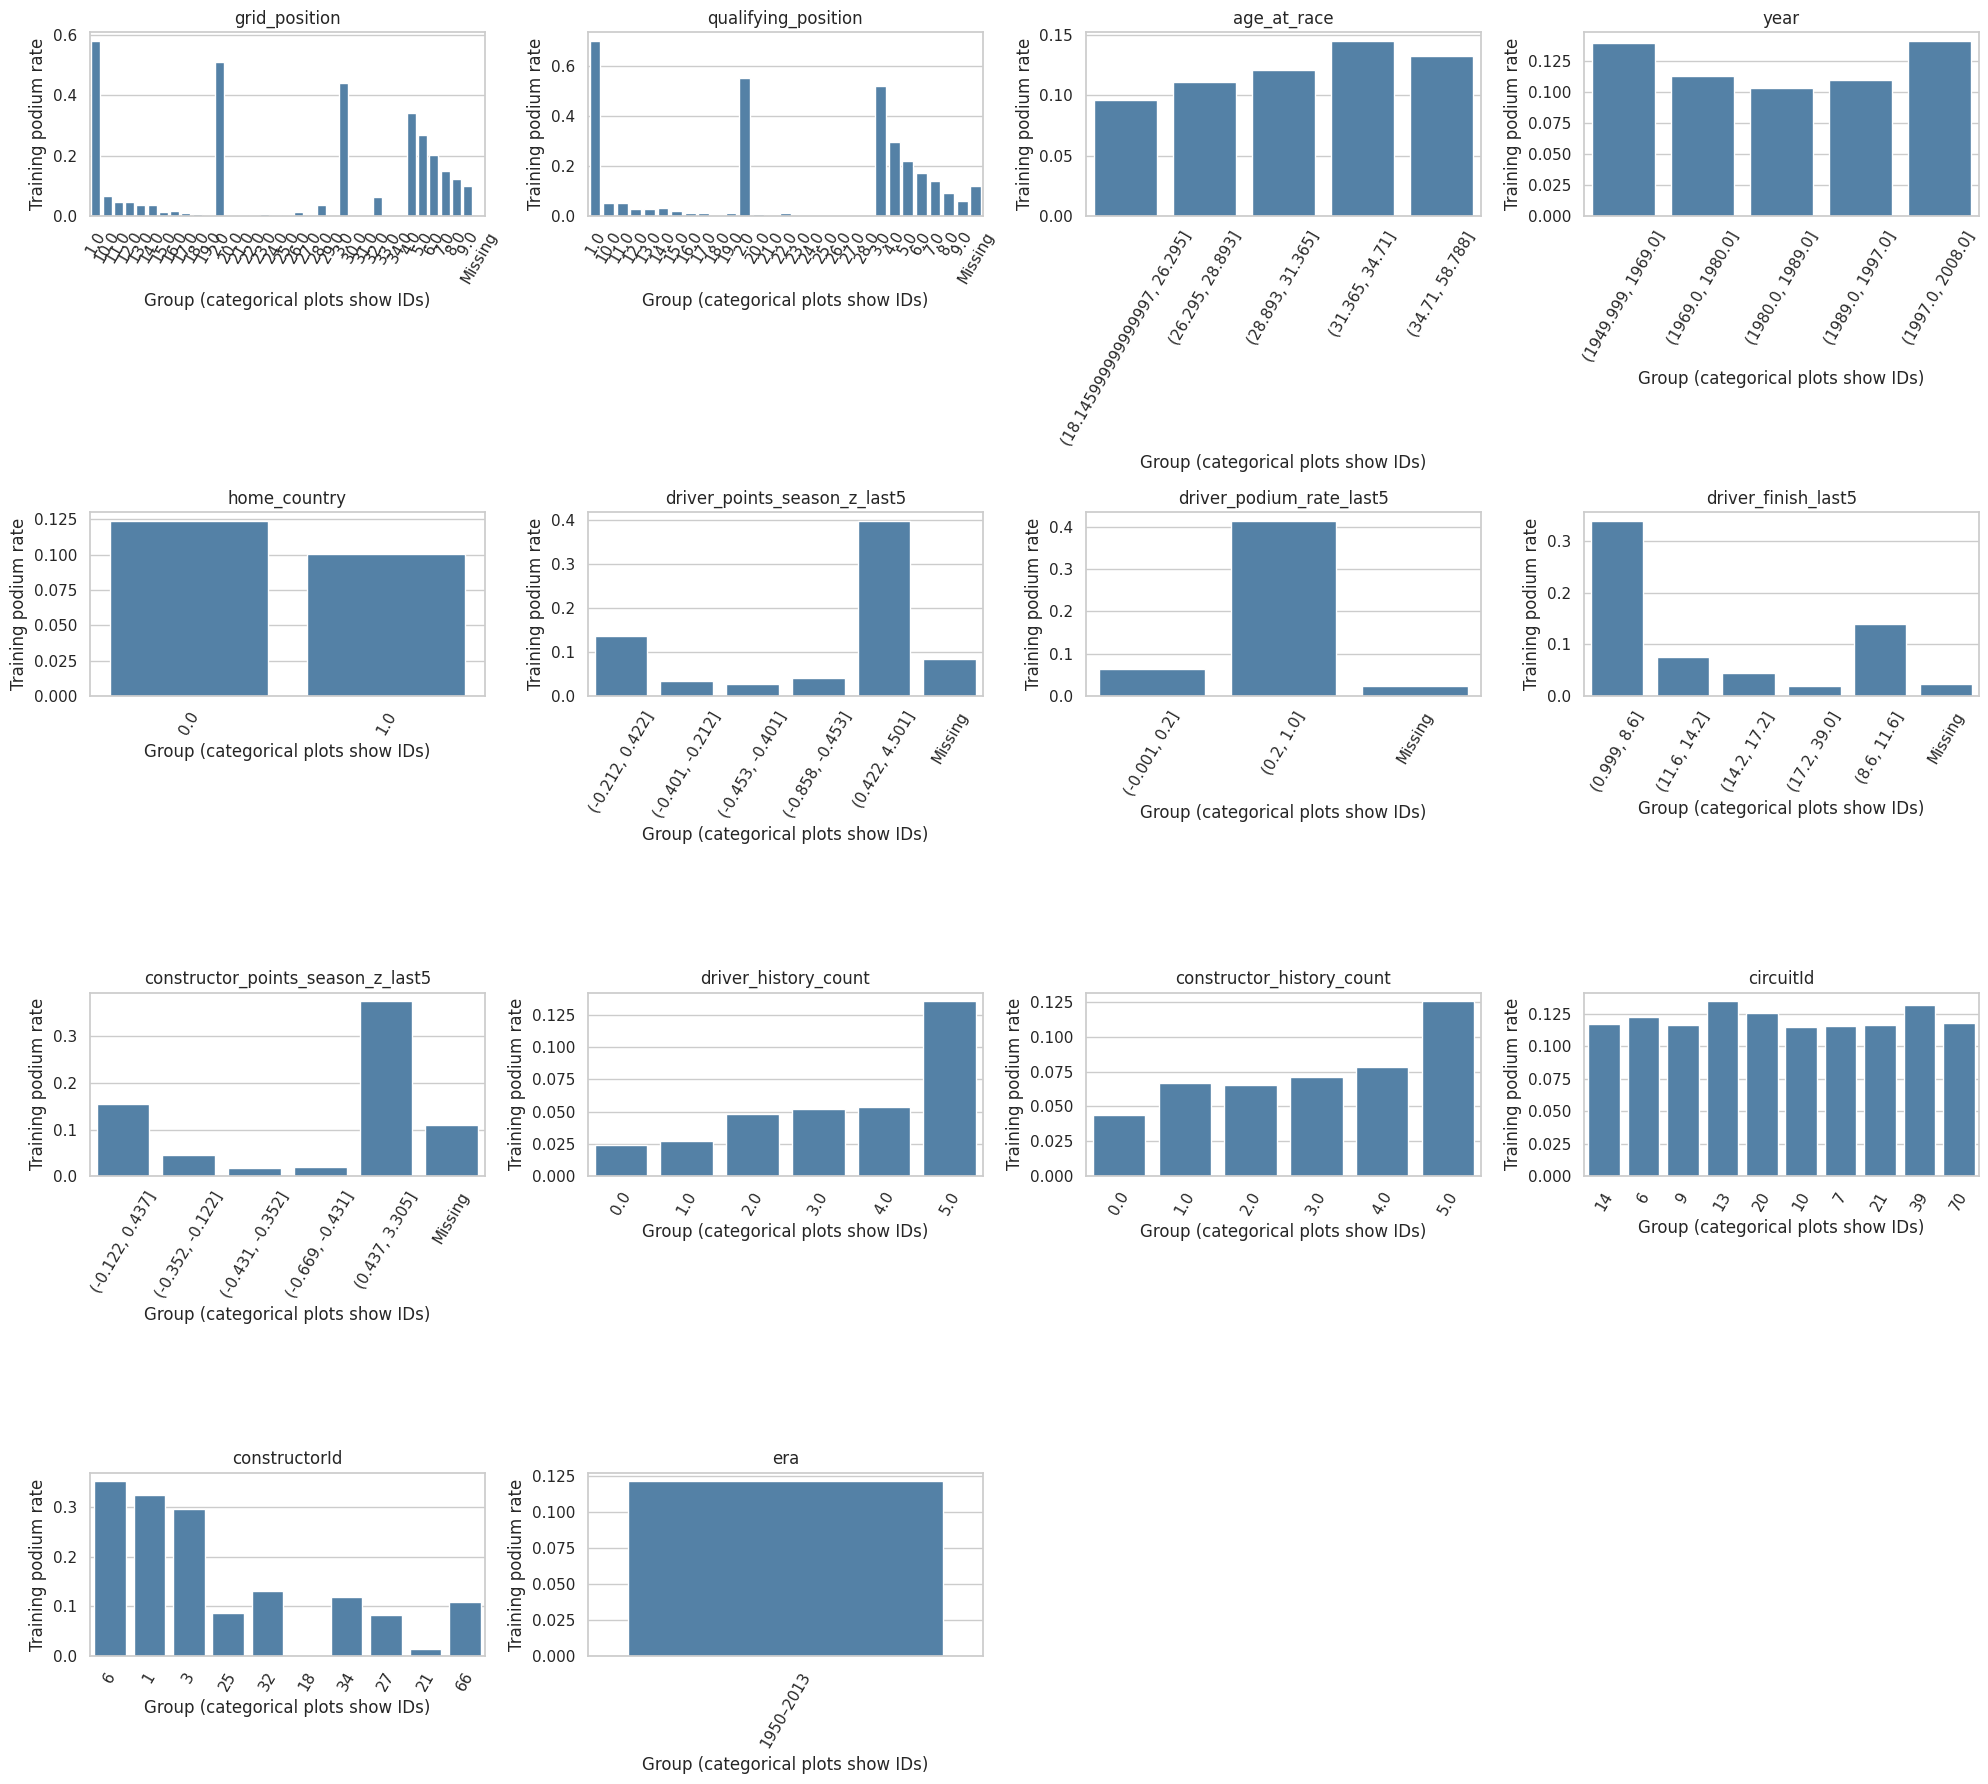

,eligible_groups,lowest_rate,highest_rate,observed_rate_range_pp
feature,,,,
qualifying_position,25,0.000000,0.698718,69.871795
grid_position,28,0.000000,0.580438,58.043758
constructorId,82,0.000000,0.447368,44.736842
driver_podium_rate_last5,3,0.023720,0.413236,38.951539
driver_points_season_z_last5,6,0.027141,0.397717,37.057590
constructor_points_season_z_last5,6,0.016771,0.375000,35.822851
driver_finish_last5,6,0.019006,0.339062,32.005626
circuitId,53,0.083333,0.200000,11.666667
driver_history_count,6,0.023720,0.135317,11.159675


Rate ranges describe training associations, not independent feature importance. Groups below 30 entries are excluded from this range summary.


In [230]:
evidence_parts = []
train_evidence = X_train.copy()
train_evidence['podium'] = y_train
for feature in selected_features:
    values = train_evidence[feature]
    if feature in categorical_features or feature == 'home_country':
        bins = values.astype('string').fillna('Missing')
    elif feature in ['grid_position', 'qualifying_position', 'driver_history_count', 'constructor_history_count']:
        bins = values.astype('string').fillna('Missing')
    elif values.nunique() > 1:
        bins = pd.qcut(values, q=min(5, values.nunique()), duplicates='drop').astype('string').fillna('Missing')
    else:
        bins = values.astype('string').fillna('Missing')
    summary = train_evidence.assign(feature_group=bins).groupby('feature_group', observed=True).agg(
        entries=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean')).reset_index()
    summary.insert(0, 'feature', feature)
    evidence_parts.append(summary)
feature_evidence = pd.concat(evidence_parts, ignore_index=True)
display(feature_evidence)
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for axis, feature in zip(axes.flat, selected_features):
    data = feature_evidence.loc[feature_evidence['feature'].eq(feature)].copy()
    if feature in categorical_features:
        data = data.nlargest(10, 'entries')  # Limit category plots to the most represented IDs.
    sns.barplot(data=data, x='feature_group', y='podium_rate', ax=axis, color='steelblue')
    axis.set_title(feature)
    axis.set_xlabel('Group (categorical plots show IDs)')
    axis.set_ylabel('Training podium rate')
    axis.tick_params(axis='x', rotation=60)
for axis in list(axes.flat)[len(selected_features):]:
    axis.set_visible(False)
plt.tight_layout(); plt.show(); plt.close()
evidence_ranges = feature_evidence.loc[feature_evidence['entries'].ge(30)].groupby('feature').agg(
    eligible_groups=('feature_group', 'size'), lowest_rate=('podium_rate', 'min'), highest_rate=('podium_rate', 'max'))
evidence_ranges['observed_rate_range_pp'] = 100 * (evidence_ranges['highest_rate'] - evidence_ranges['lowest_rate'])
display(evidence_ranges.sort_values('observed_rate_range_pp', ascending=False))
print('Rate ranges describe training associations, not independent feature importance. Groups below 30 entries are excluded from this range summary.')

### 57. Final retained and removed features
The baseline retains **14 input features: 11 numeric and 3 categorical**. These are the exact inputs in `selected_features`. The training association plots provide descriptive evidence; they do not prove independent importance, and this baseline has not used an automatic feature-elimination procedure.

| Retained feature | Why it was chosen |
| --- | --- |
| `grid_position` | Starting position affects the distance and overtaking needed to reach the podium. Use only if the grid was known at the prediction cutoff; inspect its training podium rates. |
| `qualifying_position` | Pre-race measure of competitive pace. Kept alongside grid because penalties and grid changes can make them differ. |
| `age_at_race` | Candidate measure of driver career stage; retained for evaluation, without assuming age causes better results. |
| `year` | Captures broad changes in technology, regulations and points systems that affect comparisons across seasons. |
| `era` | Reuses the before/after-2014 analysis grouping as a categorical input, allowing a broad era effect alongside gradual numeric year effects. |
| `home_country` | Tests the possible association between racing at home and podium outcomes; retained as a candidate even if the descriptive association is weak. |
| `driver_points_season_z_last5` | Previous-five same-season driver points, standardized against earlier dates in that season; reduces points-scale differences. |
| `driver_podium_rate_last5` | Measures recent success at the exact outcome being predicted, using only previous races. |
| `driver_finish_last5` | Describes recent finishing positions, including performances that earned no points or podium. |
| `constructor_points_season_z_last5` | Previous-five same-season team points per driver, standardized against earlier season-wide driver points. |
| `driver_history_count` | Records how many previous appearances support driver form, capped at five; distinguishes sparse history from low performance. |
| `constructor_history_count` | Records how many previous races support team form, capped at five. |
| `circuitId` | Represents circuit context as a categorical feature; the numerical ID itself has no ordered meaning. |
| `constructorId` | Represents team identity as a categorical feature, supplementing short-term team form. |

**Removed from the predictor set:** current-race outcomes and retirement-derived fields (leakage); Q1/Q2/Q3 lap times (not directly comparable across circuits and affected by elimination); driver identity and names (memorization); raw grid (replaced with the cleaned grid); dates, IDs, labels and audit fields (metadata); duplicate representations of age, country, team and circuit; and other descriptive fields outside this baseline. Current-race points and finishing positions remain available only to calculate form for later races.

`podium` is the **target label**, not an input. `raceId`, `driverId`, `date` and `split` are handoff metadata. The three categorical inputs are later one-hot encoded, and preprocessing creates a missingness flag for each numeric input; therefore the transformed model has more than 14 columns.

The tables below enumerate **every retained and excluded column actually present in the working table**, with a reason for each exclusion. The selection is for this baseline; exclusion does not establish that a feature is useless.

In [231]:
retained_feature_reasons = {
    'grid_position': 'Starting position known before the race; cleaned grid with unknown values left missing.',
    'qualifying_position': 'Pre-race competitive position; may differ from grid due to penalties.',
    'age_at_race': 'Candidate driver career-stage context.',
    'year': 'Season context for technology, regulation and scoring changes.',
    'era': 'Categorical before-2014 versus 2014-onward context; derived from race year only.',
    'home_country': 'Candidate home-race context.',
    'driver_points_season_z_last5': 'Previous-five same-season points normalized by earlier season-wide points mean/std; no future reference statistics.',
    'driver_podium_rate_last5': 'Recent podium frequency, using only previous appearances.',
    'driver_finish_last5': 'Recent finishing performance, using only previous appearances.',
    'constructor_points_season_z_last5': 'Previous-five same-season points per driver normalized by earlier season-wide driver points mean/std.',
    'driver_history_count': 'Amount of available driver history, capped at five.',
    'constructor_history_count': 'Amount of available team history, capped at five.',
    'circuitId': 'Categorical circuit context.',
    'constructorId': 'Categorical team identity.'
}
assert set(retained_feature_reasons) == set(selected_features)
retained_features_summary = pd.DataFrame([{'feature': feature,
    'type': 'Categorical' if feature in categorical_features else 'Numeric',
    'reason': retained_feature_reasons[feature]} for feature in selected_features])

outcome_fields = {'position', 'positionText', 'positionOrder', 'points', 'laps', 'milliseconds', 'time',
    'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'status',
    'winner_duration_seconds', 'gap_to_winner_seconds', 'elapsed_seconds', 'fastestLapTime_seconds',
    'status_classification', 'estimated_start', 'fewer_than_race_max_laps'}
qualifying_time_fields = {'q1', 'q2', 'q3', 'q1_seconds', 'q2_seconds', 'q3_seconds'}
identity_fields = {'driverId', 'driver_name', 'forename', 'surname', 'driverRef', 'code', 'number'}
audit_fields = {'had_multiple_results', 'source_result_rows', 'qualifying_constructorId',
                'qualifying_matched', 'grid_unavailable', 'driver_history_date', 'constructor_history_date',
                'season_reference_date', 'season_points_mean_prior', 'season_points_std_prior'}
redundant_fields = {'dob', 'driver_nationality', 'circuit_country', 'country_normalized',
                    'circuit_name', 'constructor_name'}
def excluded_feature_reason(column):
    if column == 'podium':
        return 'Prediction target; kept as the label, excluded from model inputs.'
    if column in outcome_fields or column.startswith(('mechanical_', 'ambiguous_', 'broad_')):
        return 'Current-race outcome or outcome-derived information; unavailable before the race (leakage).'
    if column in qualifying_time_fields:
        return 'Raw qualifying durations vary across circuits and sessions; Q2/Q3 availability reflects elimination.'
    if column in {'driver_points_last5', 'constructor_points_last5'}:
        return 'Raw same-season points history replaced by its season-normalized version; retained here for audit only.'
    if column == 'grid':
        return 'Replaced by grid_position, which treats unknown grid 0 as missing.'
    if column in identity_fields:
        return 'Driver identity/name/number is excluded to limit memorization; driverId is retained as metadata.'
    if column in audit_fields:
        return 'Audit/coverage field, not a performance input; ambiguous pairs are excluded before modeling.'
    if column in redundant_fields:
        return 'Duplicate or source representation already captured by cleaned age, home-country, year or categorical IDs.'
    if column == 'raceId' or column == 'date' or column == 'split':
        return 'Join, chronology or split metadata; excluded from predictor inputs.'
    if column == 'round':
        return 'Within-season schedule position omitted from this baseline; it has no direct performance measurement.'
    if column == 'is_sprint_weekend' or column.startswith('sprint'):
        return 'Sprint context omitted from this baseline; current sprint outcomes are not used as features.'
    if column.endswith('_date') or column.endswith('_time'):
        return 'Session schedule metadata excluded from this baseline.'
    return 'Descriptive/source field outside the explicitly defined baseline; no independent predictive value was established.'
removed_features_summary = pd.DataFrame([{'excluded_column': column,
    'reason': excluded_feature_reason(column)} for column in sorted(set(model_data.columns) - set(selected_features))])
assert len(retained_features_summary) == len(selected_features)
assert set(retained_features_summary['feature']) | set(removed_features_summary['excluded_column']) == set(model_data.columns)
print('Final inputs:', ', '.join(selected_features))
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(retained_features_summary)
    display(removed_features_summary)
retained_features_summary.to_csv(output_folder / 'retained_features_summary.csv', index=False)
removed_features_summary.to_csv(output_folder / 'removed_features_summary.csv', index=False)

Final inputs: grid_position, qualifying_position, age_at_race, year, home_country, driver_points_season_z_last5, driver_podium_rate_last5, driver_finish_last5, constructor_points_season_z_last5, driver_history_count, constructor_history_count, circuitId, constructorId, era


,feature,type,reason
0,grid_position,Numeric,Starting position known before the race; cleaned grid with unknown values left missing.
1,qualifying_position,Numeric,Pre-race competitive position; may differ from grid due to penalties.
2,age_at_race,Numeric,Candidate driver career-stage context.
3,year,Numeric,"Season context for technology, regulation and scoring changes."
4,home_country,Numeric,Candidate home-race context.
5,driver_points_season_z_last5,Numeric,Previous-five same-season points normalized by earlier season-wide points mean/std; no future reference statistics.
6,driver_podium_rate_last5,Numeric,"Recent podium frequency, using only previous appearances."
7,driver_finish_last5,Numeric,"Recent finishing performance, using only previous appearances."
8,constructor_points_season_z_last5,Numeric,Previous-five same-season points per driver normalized by earlier season-wide driver points mean/std.
9,driver_history_count,Numeric,"Amount of available driver history, capped at five."


,excluded_column,reason
0,circuit_country,"Duplicate or source representation already captured by cleaned age, home-country, year or categorical IDs."
1,circuit_name,"Duplicate or source representation already captured by cleaned age, home-country, year or categorical IDs."
2,constructor_history_date,"Audit/coverage field, not a performance input; ambiguous pairs are excluded before modeling."
3,constructor_name,"Duplicate or source representation already captured by cleaned age, home-country, year or categorical IDs."
4,constructor_points_last5,Raw same-season points history replaced by its season-normalized version; retained here for audit only.
5,country_normalized,"Duplicate or source representation already captured by cleaned age, home-country, year or categorical IDs."
6,date,"Join, chronology or split metadata; excluded from predictor inputs."
7,dob,"Duplicate or source representation already captured by cleaned age, home-country, year or categorical IDs."
8,driverId,Driver identity/name/number is excluded to limit memorization; driverId is retained as metadata.
9,driver_history_date,"Audit/coverage field, not a performance input; ambiguous pairs are excluded before modeling."


## Data Pre-processing and Feature Engineering
### 58. Compare preprocessing orders using a fixed baseline
All fitted medians, scaling parameters, clipping limits and category vocabularies use **training data only**. Preserve numerical missingness with explicit flags in every experiment. One-hot encode identities with unknown validation categories ignored. We avoid oversampling so the observed class distribution stays unchanged.

Compare A: median imputation → standardization; B: training 1st/99th-percentile clipping → median imputation → standardization; C: standardization of observed values → median imputation. Use the same features, splits, logistic-regression baseline and threshold 0.5. Standardization and median imputation are often equivalent in their location but can produce different scales because observed-only versus imputed variances differ. Clipping can suppress legitimate extreme values; evaluate it rather than assuming it helps. This small model is an experiment for preprocessing, not a completed final-model study.

**Missing-data indicators are included in both models.** For every numeric input, the separate `missing_flags` branch emits 1 if its original value is missing and 0 otherwise. It reads the unprocessed columns, so imputation cannot erase this information. Indicators remain binary and are not scaled or clipped. For example, an unavailable normalized points score becomes an imputed numeric value plus flag=1; an observed score of zero has flag=0. We reuse this existing mechanism instead of adding duplicate `qualifying_missing` or `points_missing` inputs. Every numeric feature gets a flag even when training has no missing values, keeping the input layout consistent; a constant training flag still has no learnable missingness effect. Categorical missing values use the existing `Unknown` label.

The training-only summary below reports which numeric inputs need imputation and confirms the flags match the source NaNs. SHAP and raw-feature permutation recompute a numeric feature's flag when that raw feature changes, so availability and value are explained together; they do not claim to separate those two effects.


In [232]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

class TrainingQuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper
    def fit(self, values, y=None):
        values = pd.DataFrame(np.asarray(values, dtype=float))
        self.lower_bounds_ = values.quantile(self.lower).to_numpy()
        self.upper_bounds_ = values.quantile(self.upper).to_numpy()
        return self
    def transform(self, values):
        values = np.asarray(values, dtype=float)
        # Entirely missing training columns remain missing until imputation.
        low = np.where(np.isnan(self.lower_bounds_), -np.inf, self.lower_bounds_)
        high = np.where(np.isnan(self.upper_bounds_), np.inf, self.upper_bounds_)
        return np.clip(values, low, high)

class NumericMissingFlags(BaseEstimator, TransformerMixin):
    def fit(self, values, y=None):
        return self
    def transform(self, values):
        return pd.isna(np.asarray(values)).astype(float)

def make_preprocessor(order):
    imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    scaler = StandardScaler()
    if order == 'A: impute -> scale':
        steps = [('impute', imputer), ('scale', scaler)]
    elif order == 'B: clip -> impute -> scale':
        steps = [('clip', TrainingQuantileClipper()), ('impute', imputer), ('scale', scaler)]
    elif order == 'C: scale -> impute':
        steps = [('scale', scaler), ('impute', imputer)]
    else:
        raise ValueError(order)
    return ColumnTransformer([
        ('numeric', Pipeline(steps), numeric_features),
        ('missing_flags', NumericMissingFlags(), numeric_features),
        ('categories', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

missing_flags_train = pd.DataFrame(
    NumericMissingFlags().fit_transform(X_train[numeric_features]),
    index=X_train.index, columns=[f'{feature} [missing flag]' for feature in numeric_features])
assert np.array_equal(missing_flags_train.to_numpy(), X_train[numeric_features].isna().to_numpy().astype(float))
missing_indicator_summary = pd.DataFrame({
    'feature': numeric_features,
    'missing_train_entries': X_train[numeric_features].isna().sum().to_numpy(),
    'missing_train_fraction': X_train[numeric_features].isna().mean().to_numpy(),
    'indicator_column': list(missing_flags_train.columns),
})
display(missing_indicator_summary)

experiment_orders = ['A: impute -> scale', 'B: clip -> impute -> scale', 'C: scale -> impute']
experiment_rows, fitted_experiments = [], {}
for order in experiment_orders:
    pipeline = Pipeline([('preprocess', make_preprocessor(order)),
                         ('model', LogisticRegression(max_iter=3000, random_state=42))])
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_validation)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    experiment_rows.append({'order': order, 'validation_accuracy': accuracy_score(y_validation, predictions),
        'validation_macro_f1': f1_score(y_validation, predictions, average='macro', zero_division=0),
        'validation_podium_f1': f1_score(y_validation, predictions, zero_division=0),
        'validation_roc_auc': roc_auc_score(y_validation, probabilities),
        'converged': bool((pipeline.named_steps['model'].n_iter_ < 3000).all())})
    fitted_experiments[order] = pipeline
preprocessing_experiments = pd.DataFrame(experiment_rows)
display(preprocessing_experiments)
assert preprocessing_experiments['converged'].all(), 'Increase iterations or review scaling before interpreting experiments.'
# Macro F1 is the predeclared selection metric; stable order breaks exact ties in favor of A.
best_order = preprocessing_experiments.sort_values('validation_macro_f1', ascending=False, kind='stable').iloc[0]['order']
selected_pipeline = fitted_experiments[best_order]
display(Markdown(f'**Preprocessing experiment result:** {best_order} has the highest validation macro F1. '
    'All reported numbers use the same chronological validation races. The test split remains reserved. '
    'This single split does not establish that this ordering is universally best.'))

,feature,missing_train_entries,missing_train_fraction,indicator_column
0,grid_position,1546,0.079351,grid_position [missing flag]
1,qualifying_position,16065,0.824565,qualifying_position [missing flag]
2,age_at_race,0,0.000000,age_at_race [missing flag]
3,year,0,0.000000,year [missing flag]
4,home_country,0,0.000000,home_country [missing flag]
5,driver_points_season_z_last5,2812,0.144331,driver_points_season_z_last5 [missing flag]
6,driver_podium_rate_last5,801,0.041113,driver_podium_rate_last5 [missing flag]
7,driver_finish_last5,801,0.041113,driver_finish_last5 [missing flag]
8,constructor_points_season_z_last5,2000,0.102654,constructor_points_season_z_last5 [missing flag]
9,driver_history_count,0,0.000000,driver_history_count [missing flag]


,order,validation_accuracy,validation_macro_f1,validation_podium_f1,validation_roc_auc,converged
0,A: impute -> scale,0.881215,0.708858,0.484848,0.899801,True
1,B: clip -> impute -> scale,0.881483,0.713286,0.493685,0.900233,True
2,C: scale -> impute,0.881215,0.707672,0.482436,0.901376,True


**Preprocessing experiment result:** B: clip -> impute -> scale has the highest validation macro F1. All reported numbers use the same chronological validation races. The test split remains reserved. This single split does not establish that this ordering is universally best.

### 59. Show the effect on distributions, ranges and values
Compare training numeric fields before preprocessing with the transformed values from each fitted numeric pipeline. Report missing counts, minimum, maximum, mean and standard deviation. Zero after standardization means approximately the training mean, not zero race performance. Binary flags and one-hot categories are separate from these numeric summaries. Plot grid and recent driver points to show the distribution changes. These steps do not alter the target labels or entry counts.

,stage,feature,missing,minimum,maximum,mean,std
0,Before preprocessing,grid_position,1546,1.000000,34.000000,1.222339e+01,7.042088
1,Before preprocessing,qualifying_position,16065,1.000000,28.000000,1.154886e+01,6.486660
2,Before preprocessing,age_at_race,0,18.146848,58.788339,3.064309e+01,5.078735
3,Before preprocessing,year,0,1950.000000,2008.000000,1.982692e+03,15.049432
4,Before preprocessing,home_country,0,0.000000,1.000000,1.131756e-01,0.316807
...,...,...,...,...,...,...,...
39,C: scale -> impute,driver_podium_rate_last5,0,-0.559185,3.949047,-2.298966e-02,0.985502
40,C: scale -> impute,driver_finish_last5,0,-2.139753,4.497025,-3.242109e-03,0.979353
41,C: scale -> impute,constructor_points_season_z_last5,0,-1.081311,5.218447,-4.478190e-02,0.956492
42,C: scale -> impute,driver_history_count,0,-3.495985,0.375526,2.859239e-16,1.000000


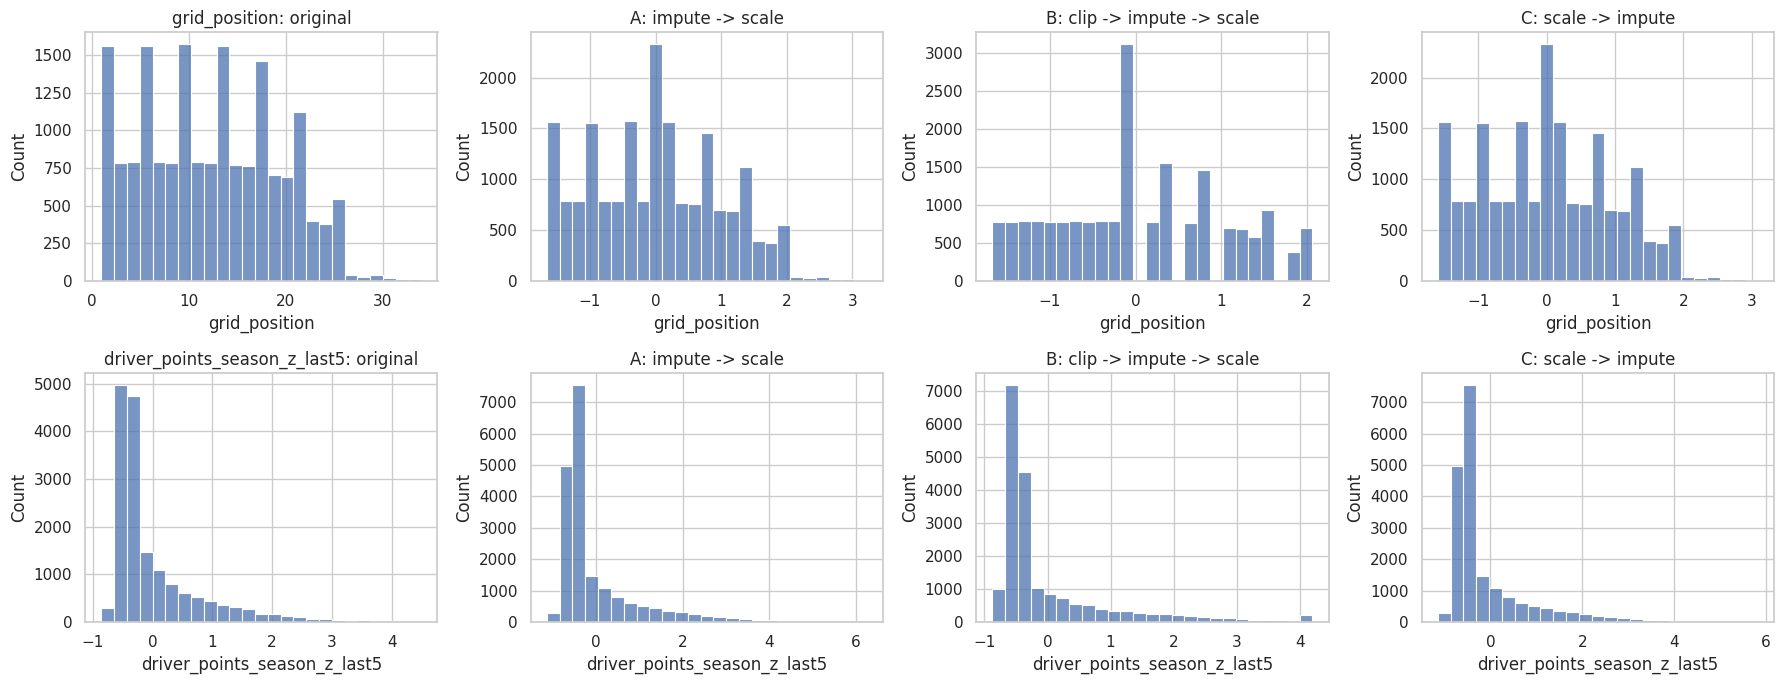

,original,A: impute -> scale,B: clip -> impute -> scale,C: scale -> impute
0,NaN,-0.441959,-0.448956,-0.485852
1,NaN,-0.441959,-0.448956,-0.485852
2,NaN,-0.441959,-0.448956,-0.485852
3,NaN,-0.441959,-0.448956,-0.485852
4,NaN,-0.441959,-0.448956,-0.485852
5,NaN,-0.441959,-0.448956,-0.485852
6,NaN,-0.441959,-0.448956,-0.485852
7,NaN,-0.441959,-0.448956,-0.485852
8,NaN,-0.441959,-0.448956,-0.485852
9,NaN,-0.441959,-0.448956,-0.485852


Training entries: 19483 | Training podium fraction unchanged: 0.12107991582405174
All numeric missing values are filled; separate missingness flags preserve their original absence.


In [233]:
distribution_rows = []
transformed_numeric = {}
def describe_numeric(frame, stage):
    for feature in numeric_features:
        values = frame[feature]
        distribution_rows.append({'stage': stage, 'feature': feature, 'missing': int(values.isna().sum()),
            'minimum': values.min(), 'maximum': values.max(), 'mean': values.mean(), 'std': values.std(ddof=0)})
describe_numeric(X_train[numeric_features], 'Before preprocessing')
for order, pipeline in fitted_experiments.items():
    numeric_pipeline = pipeline.named_steps['preprocess'].named_transformers_['numeric']
    numeric_values = pd.DataFrame(numeric_pipeline.transform(X_train[numeric_features]),
                                 columns=numeric_features, index=X_train.index)
    assert np.isfinite(numeric_values.to_numpy()).all()
    transformed_numeric[order] = numeric_values
    describe_numeric(numeric_values, order)
preprocessing_distributions = pd.DataFrame(distribution_rows)
display(preprocessing_distributions)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for row, feature in enumerate(['grid_position', 'driver_points_season_z_last5']):
    sns.histplot(X_train[feature].dropna(), ax=axes[row, 0], bins=25)
    axes[row, 0].set_title(feature + ': original')
    for col, order in enumerate(experiment_orders, start=1):
        sns.histplot(transformed_numeric[order][feature], ax=axes[row, col], bins=25)
        axes[row, col].set_title(order)
plt.tight_layout(); plt.show(); plt.close()
comparison_feature = 'driver_points_season_z_last5'
value_examples = pd.DataFrame({'original': X_train[comparison_feature]})
for order in experiment_orders:
    value_examples[order] = transformed_numeric[order][comparison_feature]
display(value_examples.head(12))
print('Training entries:', len(X_train), '| Training podium fraction unchanged:', float(y_train.mean()))
print('All numeric missing values are filled; separate missingness flags preserve their original absence.')

### 60. Save feature and preprocessing evidence
Save the selected raw feature table, split assignments, feature evidence, preprocessing effects and validation experiment results. IDs, dates, split, label and audit fields are metadata, not extra model inputs. The feature table contains unprocessed values: the modeling team must fit preprocessing on training data, using the documented order. No test predictions or scores are produced here.

In [234]:
feature_handoff = model_data[['raceId', 'driverId', 'date', 'podium']].copy()
feature_handoff[selected_features] = X
feature_handoff['split'] = np.select([train_mask, validation_mask, test_mask], ['train', 'validation', 'test'], default='unassigned')
assert not feature_handoff['split'].eq('unassigned').any()
feature_handoff.to_csv(output_folder / 'f1_selected_features.csv', index=False)
feature_evidence.to_csv(output_folder / 'feature_selection_evidence.csv', index=False)
preprocessing_experiments.to_csv(output_folder / 'preprocessing_order_experiments.csv', index=False)
preprocessing_distributions.to_csv(output_folder / 'preprocessing_distribution_effects.csv', index=False)
print('Saved feature selection, form features, distribution effects and preprocessing-order evidence.')
missing_indicator_summary.to_csv(output_folder / 'missing_indicator_summary.csv', index=False)


Saved feature selection, form features, distribution effects and preprocessing-order evidence.


# 62. Verify proper training, validation, and test splitting
The previous section already allocated whole races chronologically: first 70% of races to training, next 15% to validation, and last 15% to testing. Do not randomly re-split driver entries, which could mix the same race into different sets. The checks below confirm that race IDs and record indices do not overlap, the dates are ordered, and the target distribution can be inspected. Nothing in this cell fits a model or uses test labels to choose settings.

In [235]:
# Reuse the existing chronological splits rather than making a random split.
split_sets = {
    'Training': (train_ids, X_train, y_train),
    'Validation': (validation_ids, X_validation, y_validation),
    'Test (reserved)': (test_ids, X_test, y_test),
}
assert set(train_ids).isdisjoint(validation_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(validation_ids).isdisjoint(test_ids)
assert X_train.index.is_unique and X_validation.index.is_unique and X_test.index.is_unique
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)
assert X_train.index.equals(y_train.index)
assert X_validation.index.equals(y_validation.index)
assert X_test.index.equals(y_test.index)
assert X_train.columns.tolist() == X_validation.columns.tolist() == X_test.columns.tolist()
assert set(selected_features) == set(X_train.columns)
assert model_data.loc[train_mask, 'date'].max() < model_data.loc[validation_mask, 'date'].min()
assert model_data.loc[validation_mask, 'date'].max() < model_data.loc[test_mask, 'date'].min()
assert all(target.isin([0, 1]).all() for _, _, target in split_sets.values())

split_check = split_summary.copy()
split_check['podiums'] = [int(y_train.sum()), int(y_validation.sum()), int(y_test.sum())]
split_check['podium_fraction'] = [float(y_train.mean()), float(y_validation.mean()), float(y_test.mean())]
display(split_check)
print('Split audit passed: chronological, race-disjoint, row-disjoint, matching feature columns.')
print('All preprocessing steps will be fit on TRAINING data only.')

,split,races,entries,first_date,last_date,podiums,podium_fraction
0,Train,787,19483,1950-05-13,2008-03-23,2359,0.121080
1,Validation,169,3721,2008-04-06,2016-11-27,507,0.136254
2,Test (reserved),169,3379,2017-03-26,2024-12-08,507,0.150044


Split audit passed: chronological, race-disjoint, row-disjoint, matching feature columns.
All preprocessing steps will be fit on TRAINING data only.


# 63. Define and train the linear regression model
How the model works: after missing-value handling, numerical scaling, missingness flags and one-hot encoding, the model learns a weighted sum:
\[
\hat{s}_i=\beta_0+\beta_1z_{i1}+\cdots+\beta_pz_{ip}
\]
The coefficients are chosen to minimize the training mean squared error between each actual label \(y_i\in\{0,1\}\) and its numeric score \(\hat{s}_i\). The score becomes a podium prediction when \(\hat{s}_i\ge 0.5\). For ROC-AUC and average precision we use raw scores, since those ranking metrics do not require calibrated probabilities.
make_linear_pipeline() is defined before it is called, fixing the earlier missing-function error. It builds a fresh preprocessing pipeline based on best_order from the preceding experiments. The same builder also accepts a smaller feature list for the feature-group ablation. Using a fresh pipeline ensures imputers, scaling parameters, clipping limits, and one-hot categories are fit separately using the training rows for every experiment.
Important distinction: the earlier best_order was selected using a logistic-regression preprocessing experiment. We reuse it here for a consistent baseline; that experiment does not prove it is the optimal preprocessing order for OLS. In particular, option B clips even year, which is a limitation discussed below.

In [236]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve)

LINEAR_THRESHOLD = 0.50  # Fixed before examining test labels.


def make_linear_pipeline(order, features=None):
    """Build an OLS model with train-only preprocessing for the given feature subset."""
    if features is None:
        features = selected_features
    features = list(features)
    if not features or len(set(features)) != len(features):
        raise ValueError('Provide a nonempty list of unique features.')
    unknown = set(features) - set(selected_features)
    if unknown:
        raise ValueError(f'Unknown model features: {sorted(unknown)}')

    used_numeric = [column for column in numeric_features if column in features]
    used_categorical = [column for column in categorical_features if column in features]
    template = make_preprocessor(order)  # The preprocessor defined in section 58.
    parts = {name: transformer for name, transformer, _ in template.transformers}
    transformers = []
    if used_numeric:
        transformers.append(('numeric', parts['numeric'], used_numeric))
        transformers.append(('missing_flags', parts['missing_flags'], used_numeric))
    if used_categorical:
        transformers.append(('categories', parts['categories'], used_categorical))

    return Pipeline([
        ('preprocess', ColumnTransformer(transformers)),
        ('model', LinearRegression())  # Ordinary least squares, not logistic regression.
    ])


# Train on TRAIN ONLY. Validation and test are not used by fit().
linear_model = make_linear_pipeline(best_order)
linear_model.fit(X_train, y_train)
train_scores = np.asarray(linear_model.predict(X_train), dtype=float)
validation_scores = np.asarray(linear_model.predict(X_validation), dtype=float)

print('Trained model: LinearRegression (ordinary least squares)')
print('Preprocessing order:', best_order)
print('Original features:', len(selected_features))
print('Encoded columns:', linear_model.named_steps['preprocess'].transform(X_train.iloc[:1]).shape[1])
print('Decision rule: score >= 0.50 predicts podium')

Trained model: LinearRegression (ordinary least squares)
Preprocessing order: B: clip -> impute -> scale
Original features: 14
Encoded columns: 283
Decision rule: score >= 0.50 predicts podium


# 64. Evaluate training and validation performance
We first compare training and validation, without touching the test split. A large training–validation gap may indicate overfitting. Report both regression metrics (RMSE, MAE, R²) and classification metrics after applying the fixed 0.50 threshold (accuracy, precision, recall, podium F1, macro F1, balanced accuracy). ROC-AUC and average precision assess how well the raw score ranks podium finishers.
Macro F1 averages F1 for the podium and non-podium classes; it is more informative than accuracy alone when the podium class is relatively rare. A simple always-no-podium baseline is included to show why accuracy by itself is misleading.

In [237]:
def evaluate_linear_predictions(split_name, actual, scores, threshold=LINEAR_THRESHOLD):
    """Return both binary classification and continuous-score metrics."""
    actual = np.asarray(actual, dtype=int)
    scores = np.asarray(scores, dtype=float)
    predicted = (scores >= threshold).astype(int)
    assert len(actual) == len(scores) and np.isfinite(scores).all()
    return {
        'split': split_name,
        'entries': len(actual),
        'actual_podium_rate': float(actual.mean()),
        'accuracy': accuracy_score(actual, predicted),
        'balanced_accuracy': balanced_accuracy_score(actual, predicted),
        'podium_precision': precision_score(actual, predicted, zero_division=0),
        'podium_recall': recall_score(actual, predicted, zero_division=0),
        'podium_f1': f1_score(actual, predicted, zero_division=0),
        'macro_f1': f1_score(actual, predicted, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(actual, scores),
        'average_precision': average_precision_score(actual, scores),
        'mae': mean_absolute_error(actual, scores),
        'rmse': np.sqrt(mean_squared_error(actual, scores)),
        'r2': r2_score(actual, scores),
        'scores_outside_0_1': float(np.mean((scores < 0) | (scores > 1))),
    }

linear_training_metrics = evaluate_linear_predictions('Training', y_train, train_scores)
linear_validation_metrics = evaluate_linear_predictions('Validation', y_validation, validation_scores)
linear_development_metrics = pd.DataFrame([linear_training_metrics, linear_validation_metrics])
display(linear_development_metrics.round(4))

# An accuracy-only baseline: predict non-podium for every entry.
no_podium_baseline_scores = np.full(len(y_validation), float(y_train.mean()))
no_podium_baseline = evaluate_linear_predictions(
    'Validation: always no podium', y_validation, no_podium_baseline_scores
)
display(pd.DataFrame([
    {key: linear_validation_metrics[key] for key in ['split', 'accuracy', 'macro_f1', 'podium_f1', 'roc_auc', 'average_precision']},
    {key: no_podium_baseline[key] for key in ['split', 'accuracy', 'macro_f1', 'podium_f1', 'roc_auc', 'average_precision']},
]).round(4))

validation_predictions = (validation_scores >= LINEAR_THRESHOLD).astype(int)
print('Validation classification report (threshold = 0.50):')
print(classification_report(y_validation, validation_predictions,
                            labels=[0, 1], target_names=['No podium', 'Podium'], zero_division=0))

,split,entries,actual_podium_rate,accuracy,balanced_accuracy,podium_precision,podium_recall,podium_f1,macro_f1,roc_auc,average_precision,mae,rmse,r2,scores_outside_0_1
0,Training,19483,0.1211,0.8880,0.5945,0.6105,0.2073,0.3095,0.6243,0.8950,0.5116,0.1776,0.2786,0.2707,0.2788
1,Validation,3721,0.1363,0.8928,0.6638,0.7195,0.3491,0.4701,0.7052,0.9099,0.6162,0.1988,0.2831,0.3188,0.2859


,split,accuracy,macro_f1,podium_f1,roc_auc,average_precision
0,Validation,0.8928,0.7052,0.4701,0.9099,0.6162
1,Validation: always no podium,0.8637,0.4634,0.0000,0.5000,0.1363


Validation classification report (threshold = 0.50):
              precision    recall  f1-score   support

   No podium       0.91      0.98      0.94      3214
      Podium       0.72      0.35      0.47       507

    accuracy                           0.89      3721
   macro avg       0.81      0.66      0.71      3721
weighted avg       0.88      0.89      0.88      3721



# 65. Plot the training and validation reports
A linear regression model has no training epochs: it solves for the least-squares coefficients during .fit(), so there is no epoch-by-epoch training-loss history to plot. Instead, we display (1) training versus validation classification metrics, (2) the validation confusion matrix, and (3) the distribution of continuous scores for podium and non-podium entries. Scores outside the 0–1 range illustrate why OLS scores must not be called probabilities.

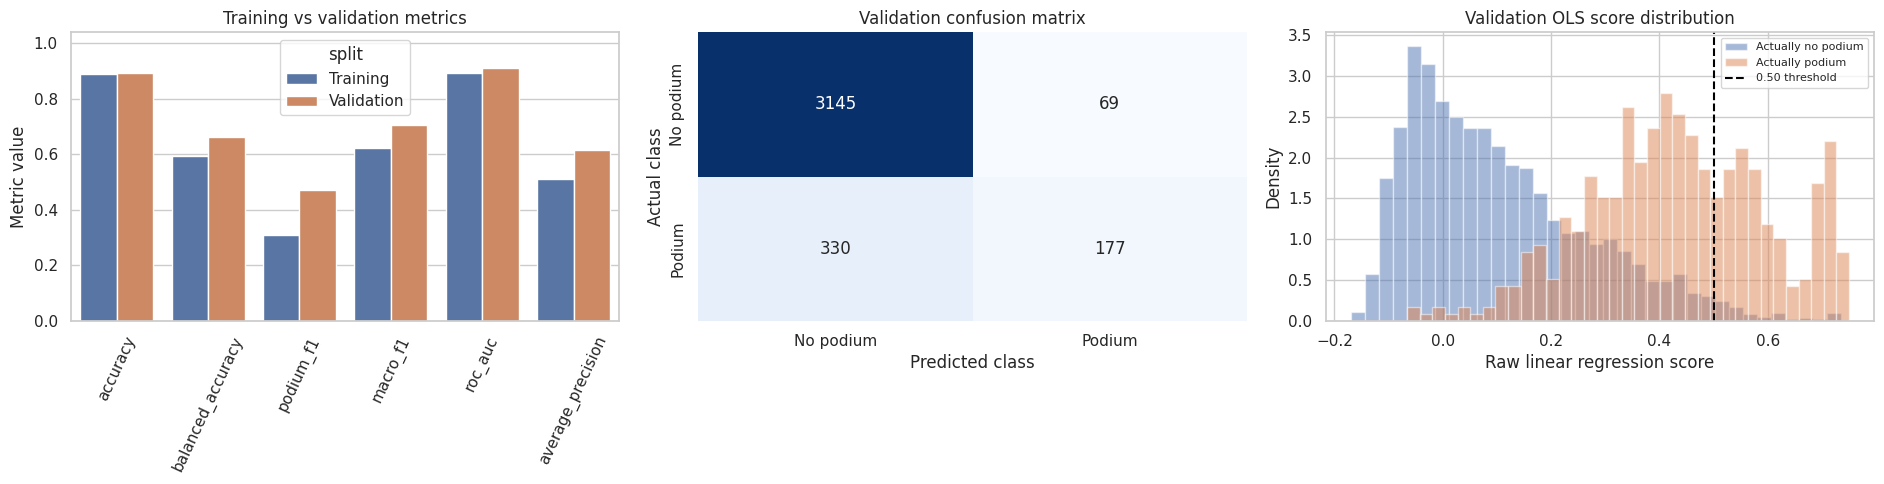

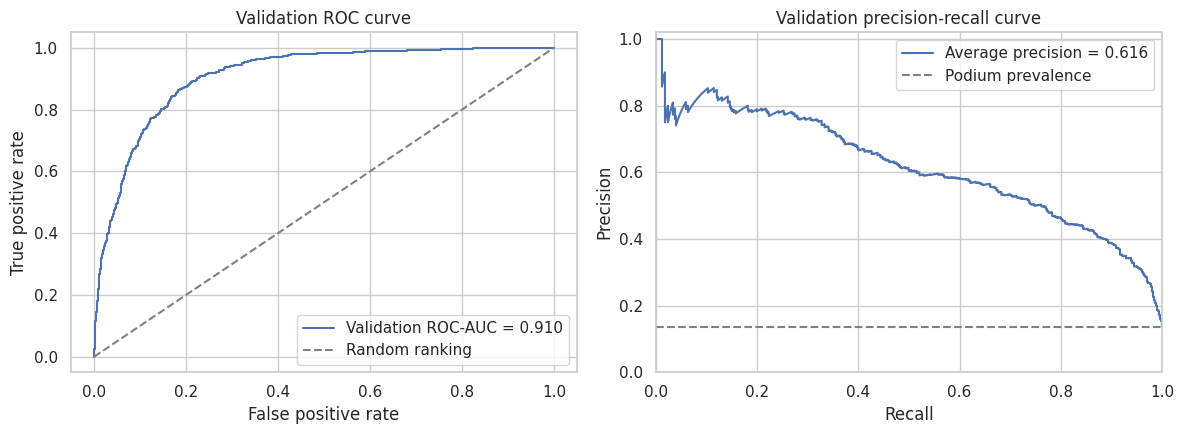

In [238]:
comparison_metrics = ['accuracy', 'balanced_accuracy', 'podium_f1', 'macro_f1', 'roc_auc', 'average_precision']
compare_for_plot = linear_development_metrics.melt(
    id_vars='split', value_vars=comparison_metrics, var_name='metric', value_name='value'
)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.barplot(data=compare_for_plot, x='metric', y='value', hue='split', ax=axes[0])
axes[0].set(title='Training vs validation metrics', xlabel='', ylabel='Metric value', ylim=(0, 1.04))
axes[0].tick_params(axis='x', rotation=65)

val_cm = confusion_matrix(y_validation, validation_predictions, labels=[0, 1])
sns.heatmap(val_cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['No podium', 'Podium'], yticklabels=['No podium', 'Podium'])
axes[1].set(title='Validation confusion matrix', xlabel='Predicted class', ylabel='Actual class')

axes[2].hist(validation_scores[np.asarray(y_validation) == 0], bins=35, alpha=0.5,
             label='Actually no podium', density=True)
axes[2].hist(validation_scores[np.asarray(y_validation) == 1], bins=35, alpha=0.5,
             label='Actually podium', density=True)
axes[2].axvline(LINEAR_THRESHOLD, color='black', ls='--', lw=1.5, label='0.50 threshold')
axes[2].set(title='Validation OLS score distribution', xlabel='Raw linear regression score', ylabel='Density')
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show(); plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fpr, tpr, _ = roc_curve(y_validation, validation_scores)
axes[0].plot(fpr, tpr, label=f'Validation ROC-AUC = {linear_validation_metrics["roc_auc"]:.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
axes[0].set(title='Validation ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend()
precision, recall, _ = precision_recall_curve(y_validation, validation_scores)
axes[1].plot(recall, precision, label=f'Average precision = {linear_validation_metrics["average_precision"]:.3f}')
axes[1].axhline(float(y_validation.mean()), color='gray', ls='--', label='Podium prevalence')
axes[1].set(title='Validation precision-recall curve', xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1.02))
axes[1].legend()
plt.tight_layout(); plt.show(); plt.close()

# 66. Learning curves: does more training history help?
Instead of fictitious epochs, retrain the same OLS pipeline on increasing chronological prefixes of the training races (15%, 25%, 40%, 55%, 70%, 85%, 100%). For each prefix, show its training performance and performance on the same held-out validation set. Each prefix includes complete races only; no validation or test rows enter fitting. The curves help diagnose whether performance improves as more history becomes available.

,training_races,training_entries,train_macro_f1,validation_macro_f1,train_rmse,validation_rmse
0,119,2707,0.5830,0.6522,0.2943,0.2866
1,197,4240,0.5541,0.6250,0.3057,0.2912
2,315,7400,0.5393,0.6182,0.2942,0.2837
3,433,10642,0.5338,0.5952,0.2888,0.2853
4,551,14309,0.5771,0.6781,0.2778,0.2836
5,669,17009,0.5865,0.6744,0.2787,0.2821
6,787,19483,0.6243,0.7052,0.2786,0.2831


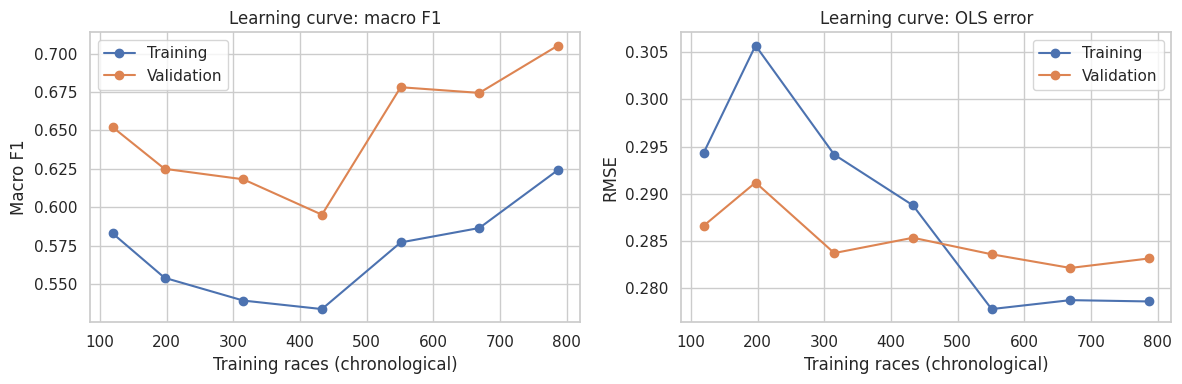

In [239]:
learning_rows = []
training_race_list = train_ids.tolist()
for fraction in [0.15, 0.25, 0.40, 0.55, 0.70, 0.85, 1.00]:
    number_of_races = max(1, int(np.ceil(len(training_race_list) * fraction)))
    included_race_ids = set(training_race_list[:number_of_races])
    prefix_rows = model_data.loc[X_train.index, 'raceId'].isin(included_race_ids)
    X_prefix, y_prefix = X_train.loc[prefix_rows], y_train.loc[prefix_rows]

    prefix_model = make_linear_pipeline(best_order)
    prefix_model.fit(X_prefix, y_prefix)
    prefix_training_metrics = evaluate_linear_predictions(
        'Training prefix', y_prefix, prefix_model.predict(X_prefix)
    )
    prefix_validation_metrics = evaluate_linear_predictions(
        'Validation', y_validation, prefix_model.predict(X_validation)
    )
    learning_rows.append({
        'training_races': number_of_races,
        'training_entries': len(X_prefix),
        'train_macro_f1': prefix_training_metrics['macro_f1'],
        'validation_macro_f1': prefix_validation_metrics['macro_f1'],
        'train_rmse': prefix_training_metrics['rmse'],
        'validation_rmse': prefix_validation_metrics['rmse'],
    })
linear_learning_curve = pd.DataFrame(learning_rows)
display(linear_learning_curve.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(linear_learning_curve['training_races'], linear_learning_curve['train_macro_f1'], 'o-', label='Training')
axes[0].plot(linear_learning_curve['training_races'], linear_learning_curve['validation_macro_f1'], 'o-', label='Validation')
axes[0].set(title='Learning curve: macro F1', xlabel='Training races (chronological)', ylabel='Macro F1')
axes[0].legend()
axes[1].plot(linear_learning_curve['training_races'], linear_learning_curve['train_rmse'], 'o-', label='Training')
axes[1].plot(linear_learning_curve['training_races'], linear_learning_curve['validation_rmse'], 'o-', label='Validation')
axes[1].set(title='Learning curve: OLS error', xlabel='Training races (chronological)', ylabel='RMSE')
axes[1].legend()
plt.tight_layout(); plt.show(); plt.close()

# 67. Feature-group ablation (validation only)
Ablation asks: what happens if we remove one whole type of information? The groups below partition all 14 original features, including categorical identities. For each group we drop those columns, create a fresh model and fit its preprocessing on training data only, then compare validation performance with the full model. This measures predictive contribution under this model and data split; it does not prove causation.
A negative change in macro F1 after removal means the group was helpful; a positive change means removing it improved validation macro F1. We deliberately do not use the test set for ablation.

,removed_group,features_remaining,validation_macro_f1,validation_podium_f1,validation_roc_auc,validation_average_precision,validation_rmse,delta_macro_f1_vs_full,delta_roc_auc_vs_full
0,None (full model),14,0.7052,0.4701,0.9099,0.6162,0.2831,0.0000,0.0000
1,Starting grid and qualifying,12,0.6752,0.4133,0.8814,0.5551,0.2898,-0.0300,-0.0285
2,Recent driver performance,10,0.6498,0.3647,0.9032,0.5851,0.2905,-0.0554,-0.0067
3,Recent constructor performance,12,0.7013,0.4626,0.9043,0.6056,0.2855,-0.0040,-0.0056
4,Driver and season context,10,0.7052,0.4701,0.9099,0.6156,0.2832,0.0000,-0.0001
5,Circuit identity,13,0.7052,0.4701,0.9097,0.6162,0.2832,0.0000,-0.0002
6,Constructor identity,13,0.6905,0.4420,0.9213,0.6319,0.2773,-0.0147,0.0114


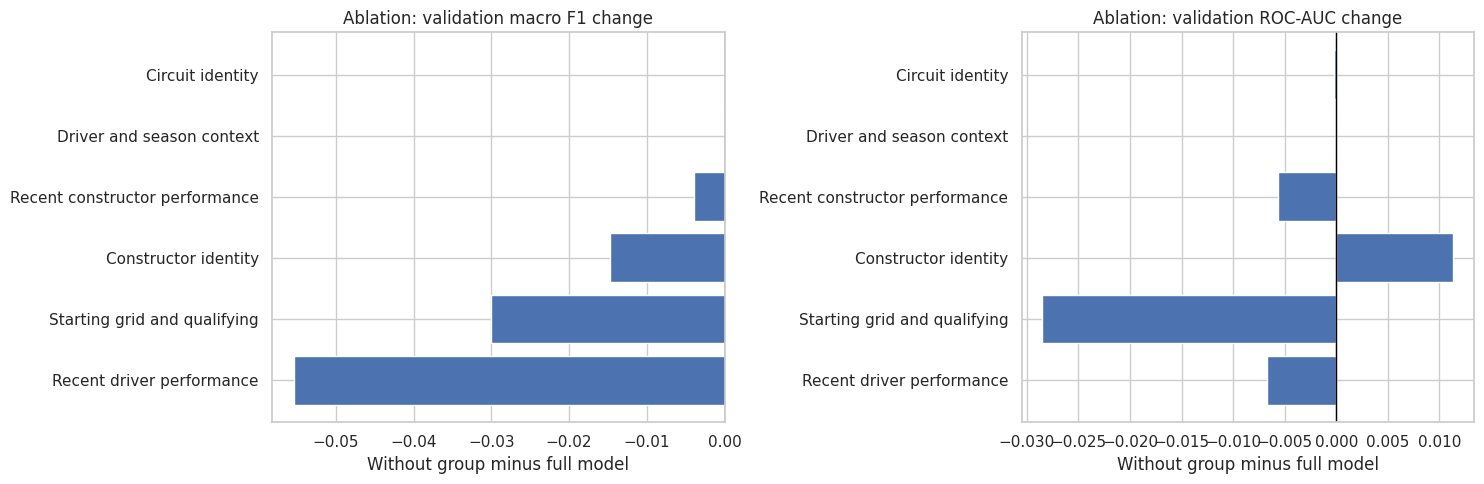

Negative delta = removing the feature group hurts the model; positive delta = removal helps.


In [240]:
feature_groups = {
    'Starting grid and qualifying': ['grid_position', 'qualifying_position'],
    'Recent driver performance': ['driver_points_season_z_last5', 'driver_podium_rate_last5',
                                  'driver_finish_last5', 'driver_history_count'],
    'Recent constructor performance': ['constructor_points_season_z_last5', 'constructor_history_count'],
    'Driver and season context': ['age_at_race', 'home_country', 'year', 'era'],
    'Circuit identity': ['circuitId'],
    'Constructor identity': ['constructorId'],
}
all_grouped_features = [column for group in feature_groups.values() for column in group]
assert len(all_grouped_features) == len(set(all_grouped_features))
assert set(all_grouped_features) == set(selected_features), 'Every chosen feature must belong to one ablation group.'

full_validation_reference = linear_validation_metrics
ablation_rows = [{
    'removed_group': 'None (full model)',
    'features_remaining': len(selected_features),
    'validation_macro_f1': full_validation_reference['macro_f1'],
    'validation_podium_f1': full_validation_reference['podium_f1'],
    'validation_roc_auc': full_validation_reference['roc_auc'],
    'validation_average_precision': full_validation_reference['average_precision'],
    'validation_rmse': full_validation_reference['rmse'],
}]
for group_name, removed_features in feature_groups.items():
    kept_features = [column for column in selected_features if column not in removed_features]
    ablated_model = make_linear_pipeline(best_order, features=kept_features)
    ablated_model.fit(X_train[kept_features], y_train)
    ablated_scores = ablated_model.predict(X_validation[kept_features])
    ablated_metrics = evaluate_linear_predictions('Validation', y_validation, ablated_scores)
    ablation_rows.append({
        'removed_group': group_name,
        'features_remaining': len(kept_features),
        'validation_macro_f1': ablated_metrics['macro_f1'],
        'validation_podium_f1': ablated_metrics['podium_f1'],
        'validation_roc_auc': ablated_metrics['roc_auc'],
        'validation_average_precision': ablated_metrics['average_precision'],
        'validation_rmse': ablated_metrics['rmse'],
    })
linear_ablation = pd.DataFrame(ablation_rows)
linear_ablation['delta_macro_f1_vs_full'] = linear_ablation['validation_macro_f1'] - full_validation_reference['macro_f1']
linear_ablation['delta_roc_auc_vs_full'] = linear_ablation['validation_roc_auc'] - full_validation_reference['roc_auc']
display(linear_ablation.round(4))

ablation_plot = linear_ablation.loc[linear_ablation['removed_group'] != 'None (full model)'].sort_values('delta_macro_f1_vs_full')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(ablation_plot['removed_group'], ablation_plot['delta_macro_f1_vs_full'])
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set(title='Ablation: validation macro F1 change', xlabel='Without group minus full model')
axes[1].barh(ablation_plot['removed_group'], ablation_plot['delta_roc_auc_vs_full'])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set(title='Ablation: validation ROC-AUC change', xlabel='Without group minus full model')
plt.tight_layout(); plt.show(); plt.close()
print('Negative delta = removing the feature group hurts the model; positive delta = removal helps.')

# 68. Evaluate on unseen test races after model decisions are frozen
We now evaluate the original full-feature linear_model on the reserved chronological test split. That model was already trained using training data only; its 0.50 decision threshold, preprocessing order, and feature list were established before this test evaluation. Do not select hyperparameters, feature groups or the later FNN based on the test results. For the FNN stage, use training for fitting and validation for comparison, then treat test results as final reporting only.
Both regression and classification scores are included. A confusion matrix shows actual vs predicted labels, and ROC/PR curves show ranking quality. We report a sport-specific check too: how many of each race's actual podium drivers appear among the three highest-scored drivers? This measure is distinct from threshold-based F1.

In [241]:
# First and only held-out TEST evaluation of this fixed linear regression model.
test_scores = np.asarray(linear_model.predict(X_test), dtype=float)
test_predictions = (test_scores >= LINEAR_THRESHOLD).astype(int)
linear_test_metrics = evaluate_linear_predictions('Test', y_test, test_scores)
linear_performance = pd.DataFrame([
    linear_training_metrics, linear_validation_metrics, linear_test_metrics
])
display(linear_performance.round(4))

print('Final test classification report (threshold = 0.50):')
print(classification_report(y_test, test_predictions,
                            labels=[0, 1], target_names=['No podium', 'Podium'], zero_division=0))


def podium_hits_in_top_three(entry_indices, raw_scores, split_name):
    """Count actual podium finishers within the model's three highest scores per race."""
    races = model_data.loc[entry_indices, ['raceId', 'driverId', 'podium']].copy()
    races['score'] = np.asarray(raw_scores, dtype=float)
    ranked = races.sort_values(['raceId', 'score', 'driverId'], ascending=[True, False, True])
    top_three = ranked.groupby('raceId', sort=False).head(3)
    hits_per_race = top_three.groupby('raceId')['podium'].sum()
    return {
        'split': split_name,
        'races': int(races['raceId'].nunique()),
        'average_podium_drivers_in_top3': float(hits_per_race.mean()),
        'mean_precision_at_3': float((hits_per_race / 3).mean()),
    }

race_ranking_metrics = pd.DataFrame([
    podium_hits_in_top_three(X_validation.index, validation_scores, 'Validation'),
    podium_hits_in_top_three(X_test.index, test_scores, 'Test'),
])
display(race_ranking_metrics.round(4))

,split,entries,actual_podium_rate,accuracy,balanced_accuracy,podium_precision,podium_recall,podium_f1,macro_f1,roc_auc,average_precision,mae,rmse,r2,scores_outside_0_1
0,Training,19483,0.1211,0.8880,0.5945,0.6105,0.2073,0.3095,0.6243,0.8950,0.5116,0.1776,0.2786,0.2707,0.2788
1,Validation,3721,0.1363,0.8928,0.6638,0.7195,0.3491,0.4701,0.7052,0.9099,0.6162,0.1988,0.2831,0.3188,0.2859
2,Test,3379,0.1500,0.8807,0.6960,0.6557,0.4320,0.5208,0.7263,0.9199,0.6342,0.1992,0.2856,0.3606,0.2172


Final test classification report (threshold = 0.50):
              precision    recall  f1-score   support

   No podium       0.91      0.96      0.93      2872
      Podium       0.66      0.43      0.52       507

    accuracy                           0.88      3379
   macro avg       0.78      0.70      0.73      3379
weighted avg       0.87      0.88      0.87      3379



,split,races,average_podium_drivers_in_top3,mean_precision_at_3
0,Validation,169,1.6982,0.5661
1,Test,169,1.8521,0.6174


# 69. Plot the final test reports
These graphics compare validation and test without retraining or modifying the model. The confusion matrices use the same 0.50 decision threshold. ROC and PR curves use raw linear regression scores; PR baselines reflect the different podium prevalence in the two splits.

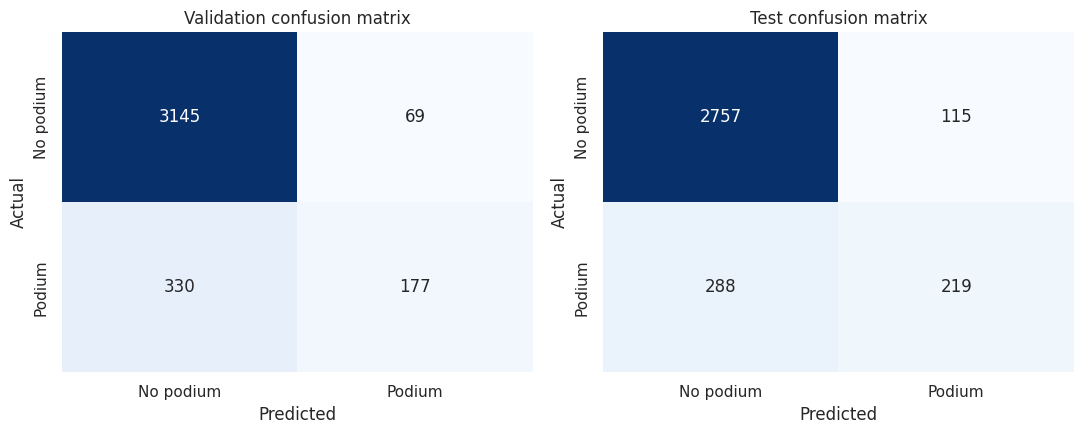

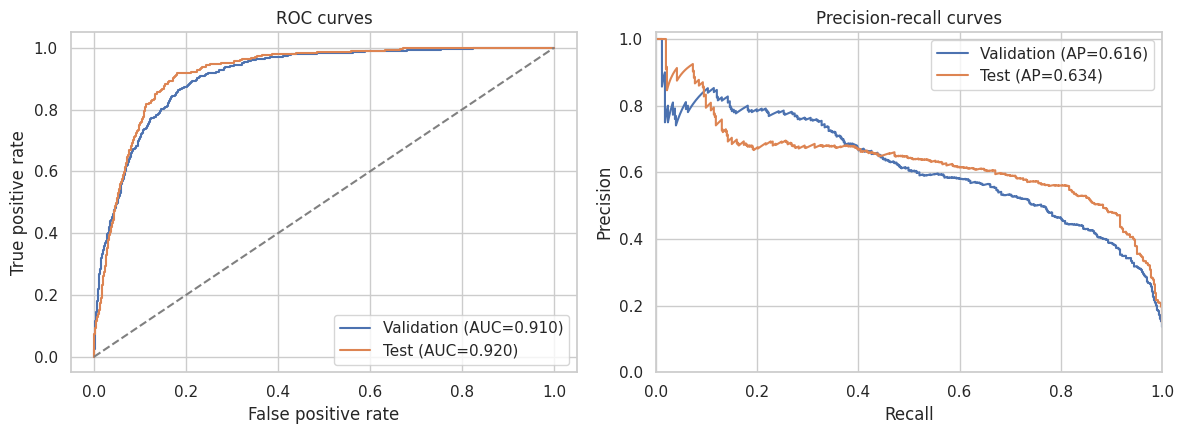

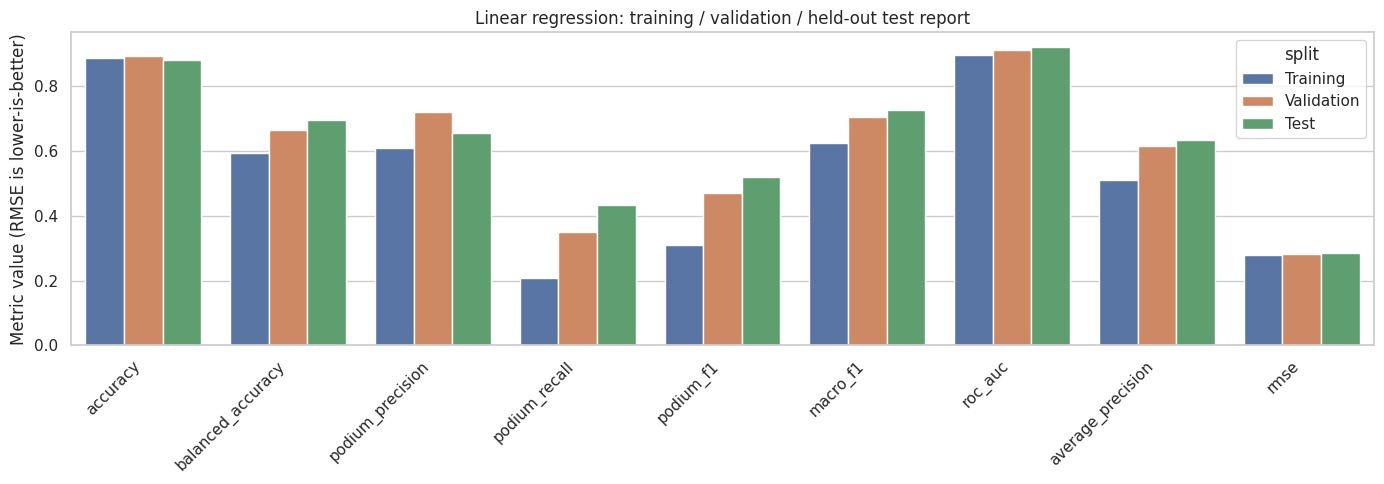

In [242]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, split_name, truth, predicted in [
    (axes[0], 'Validation', y_validation, validation_predictions),
    (axes[1], 'Test', y_test, test_predictions)
]:
    cm = confusion_matrix(truth, predicted, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No podium', 'Podium'], yticklabels=['No podium', 'Podium'])
    ax.set(title=f'{split_name} confusion matrix', xlabel='Predicted', ylabel='Actual')
plt.tight_layout(); plt.show(); plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, truth, scores in [('Validation', y_validation, validation_scores), ('Test', y_test, test_scores)]:
    fpr, tpr, _ = roc_curve(truth, scores)
    ap = average_precision_score(truth, scores)
    prec, rec, _ = precision_recall_curve(truth, scores)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(truth, scores):.3f})')
    axes[1].plot(rec, prec, label=f'{name} (AP={ap:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Precision-recall curves', xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1.02))
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show(); plt.close()

report_columns = ['accuracy', 'balanced_accuracy', 'podium_precision', 'podium_recall',
                  'podium_f1', 'macro_f1', 'roc_auc', 'average_precision', 'rmse']
performance_plot = linear_performance.melt(id_vars='split', value_vars=report_columns,
                                           var_name='metric', value_name='value')
plt.figure(figsize=(14, 5))
sns.barplot(data=performance_plot, x='metric', y='value', hue='split')
plt.xticks(rotation=45, ha='right')
plt.title('Linear regression: training / validation / held-out test report')
plt.xlabel(''); plt.ylabel('Metric value (RMSE is lower-is-better)')
plt.tight_layout(); plt.show(); plt.close()

# 70. Linear regression limitations and interpretation
1. Binary target, continuous model: OLS minimizes squared error, rather than a binary-classification loss. Its scores can fall outside 0 to 1, so they should not be described as well-calibrated podium probabilities. We use ROC-AUC and average precision only as ranking measures; the 0.50 threshold is a simple fixed decision rule, not a tuned optimum.
2. Only additive linear patterns: without explicitly engineered interactions, OLS cannot directly learn more complex effects such as a driver's qualifying position interacting nonlinearly with the constructor or circuit. This is one reason to compare against an FNN later.
3. Class imbalance: roughly three podium finishers per race means accuracy can be high even for an unhelpful model. Compare podium F1, macro F1, recall and average precision, not accuracy alone.
4. Past vs future can differ: vehicle regulations, point systems and team competitiveness change between seasons. The chronological test split measures this more realistically than a random split, but extrapolating to future years is still difficult.
5. Preprocessing caveat: the earlier chosen option B clips all numeric features at training-set percentiles. This includes year, so validation/test years later than the training range can be clipped to the training range. This is consistent with the original experiment but may conceal future-year trends; a later controlled improvement would selectively clip sensible continuous measurements while leaving year and indicator/count features alone.
6. Prediction cutoff: the notebook uses archive starting-grid information as a proxy for the grid known after qualifying and before the race. Late changes may not have been available at the exact intended prediction moment.
7. Ablation is not causal: dropping a feature group changes the model and can also change the effect of correlated inputs. A small ablation gain or loss does not prove that the removed variables have no role in reality.
Era coverage: the added categorical era represents a broad before/after-2014 difference; numeric year remains included. An era absent from training has no learned effect, even though handle_unknown="ignore" allows predictions. The additional past-only season normalization reduces points-scale differences but does not fully harmonize scoring rules. First-season races lack a normalization reference; binary missingness flags preserve this uncertainty. Comparable performance across periods is not guaranteed.


# 71. Save the linear regression results
Save reproducible tables for the report: audit of the existing split, all training/validation/test metrics, chronological learning curves, validation-only feature-group ablations, and row-level predictions with the original race/driver identifiers. A fitted pipeline is also saved for inference. Loading that pipeline with joblib requires the custom preprocessing transformer definitions from the notebook to be available in the Python environment.

In [243]:
import joblib

split_check.to_csv(output_folder / 'linear_split_audit.csv', index=False)
linear_performance.to_csv(output_folder / 'linear_regression_split_metrics.csv', index=False)
linear_learning_curve.to_csv(output_folder / 'linear_regression_learning_curve.csv', index=False)
linear_ablation.to_csv(output_folder / 'linear_regression_feature_group_ablation.csv', index=False)
race_ranking_metrics.to_csv(output_folder / 'linear_regression_race_top3_metrics.csv', index=False)


def save_linear_predictions(file_name, model_indices, truth, scores):
    predictions_table = model_data.loc[model_indices, ['raceId', 'driverId', 'date']].copy()
    predictions_table['actual_podium'] = np.asarray(truth, dtype=int)
    predictions_table['ols_score'] = np.asarray(scores, dtype=float)
    predictions_table['predicted_podium'] = (predictions_table['ols_score'] >= LINEAR_THRESHOLD).astype(int)
    predictions_table.to_csv(output_folder / file_name, index=False)
    return predictions_table

linear_validation_predictions_table = save_linear_predictions(
    'linear_regression_validation_predictions.csv', X_validation.index, y_validation, validation_scores
)
linear_test_predictions_table = save_linear_predictions(
    'linear_regression_test_predictions.csv', X_test.index, y_test, test_scores
)
joblib.dump(linear_model, output_folder / 'linear_regression_pipeline.joblib')

print('Saved linear regression reports and pipeline to:', output_folder.resolve())
print('This is the end of the linear regression section. The FNN has NOT been implemented.')

Saved linear regression reports and pipeline to: /kaggle/working
This is the end of the linear regression section. The FNN has NOT been implemented.


# 72. Preprocess the FNN inputs (training data only)
The FNN cannot process missing values or raw category strings. We therefore reuse exactly the preprocessing steps and feature subsets from the linear regression pipeline: numeric imputation/scaling/clipping, missingness indicators, and one-hot encodings. Only the input representation is shared; the FNN learns fresh weights. The encoded matrix is converted to dense float32 for PyTorch.
The test matrix remains untouched in this section; it will be transformed only for the final test evaluation.

In [244]:
import copy
import random
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import log_loss, brier_score_loss

FNN_CONFIG = {
    'hidden_units': 32,      # One small hidden layer: shallow FNN
    'dropout': 0.20,         # Regularization during training
    'learning_rate': 0.002,
    'weight_decay': 1e-4,
    'batch_size': 256,
    'max_epochs': 120,
    'patience': 12,          # Stop when validation loss no longer improves
    'seed': 42,
}
FNN_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Reuse the same fitted-transformer *definition*, not the fitted OLS model.
# The returned transformer is new, so it is fitted ONLY on X_train below.
def make_fnn_preprocessor(features=None):
    if features is None:
        features = selected_features
    return make_linear_pipeline(best_order, features=features).named_steps['preprocess']


def as_fnn_array(matrix):
    """Convert a sparse/dense transformed design matrix to finite float32."""
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    array = np.asarray(matrix, dtype=np.float32)
    if array.ndim != 2 or array.shape[1] == 0 or not np.isfinite(array).all():
        raise ValueError('FNN input must be a finite, nonempty 2D feature matrix.')
    return array


fnn_preprocessor = make_fnn_preprocessor()
X_train_fnn = as_fnn_array(fnn_preprocessor.fit_transform(X_train[selected_features]))
X_validation_fnn = as_fnn_array(fnn_preprocessor.transform(X_validation[selected_features]))
y_train_fnn = y_train.to_numpy(dtype=np.float32)
y_validation_fnn = y_validation.to_numpy(dtype=np.float32)

assert X_train_fnn.shape[0] == len(y_train_fnn)
assert X_validation_fnn.shape[0] == len(y_validation_fnn)
assert X_train_fnn.shape[1] == X_validation_fnn.shape[1]
assert set(np.unique(y_train_fnn)).issubset({0.0, 1.0})
print('Preprocessing:', best_order)
print('Device:', FNN_DEVICE)
print('Training features:', X_train_fnn.shape, '| Validation features:', X_validation_fnn.shape)
print('Training podium prevalence:', f'{y_train_fnn.mean():.2%}')
print('Validation podium prevalence:', f'{y_validation_fnn.mean():.2%}')

Preprocessing: B: clip -> impute -> scale
Device: cpu
Training features: (19483, 283) | Validation features: (3721, 283)
Training podium prevalence: 12.11%
Validation podium prevalence: 13.63%


# 73. Define and train the shallow neural network
How the FNN works
\[
\underbrace{\mathbf{x}}_{\text{encoded inputs}}
\longrightarrow \underbrace{\mathrm{ReLU}(W_1\mathbf{x}+b_1)}_{\text{32 hidden neurons}}
\longrightarrow \underbrace{W_2\mathbf{h}+b_2}_{\text{one logit}}
\longrightarrow \underbrace{\sigma(z)}_{P(\text{podium})}.
\]
- Hidden layer: 32 fully connected neurons with ReLU activation, allowing non-linear feature combinations.
- Dropout (20%) randomly disables some hidden activations during training to reduce overfitting; it is disabled for predictions.
- Output: one logit for binary classification. BCEWithLogitsLoss combines sigmoid and binary cross-entropy numerically stably; sigmoid(logit) is used for probability scores at inference.
- Optimizer: Adam, with a small weight_decay (L2-style regularization).
- Model selection: after each epoch, evaluate validation loss; preserve the best weights and stop after 12 non-improving epochs. No test labels participate in training or early stopping.
No class weights are used. This keeps the training loss probabilistic, but because podiums are rarer than non-podiums, a threshold of 0.5 may not be optimal for macro F1; we assess this on validation later.

In [245]:
from tqdm.auto import tqdm

def set_fnn_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class ShallowPodiumFNN(nn.Module):
    def __init__(self, input_features, hidden_units=32, dropout=0.20):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_units, 1),
        )

    def forward(self, features):
        return self.network(features).squeeze(-1)  # Raw logits, not probabilities.


@torch.no_grad()
def predict_fnn_probabilities(model, features, batch_size=2048):
    model.eval()  # Disables dropout for reproducible inference.
    features = np.asarray(features, dtype=np.float32)
    probabilities = []
    for first in range(0, len(features), batch_size):
        batch = torch.from_numpy(features[first:first + batch_size]).to(FNN_DEVICE)
        probabilities.append(torch.sigmoid(model(batch)).cpu().numpy())
    if not probabilities:
        return np.array([], dtype=float)
    return np.concatenate(probabilities).astype(float)


def train_shallow_fnn(train_features, train_targets, valid_features, valid_targets,
                      config=FNN_CONFIG, progress_label='FNN training', leave_progress=True):
    """Fit a new model on training data; use validation ONLY for early stopping."""
    set_fnn_seed(config['seed'])
    model = ShallowPodiumFNN(
        input_features=train_features.shape[1],
        hidden_units=config['hidden_units'],
        dropout=config['dropout'],
    ).to(FNN_DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config['learning_rate'],
        weight_decay=config['weight_decay']
    )

    train_tensor = torch.from_numpy(np.asarray(train_features, dtype=np.float32))
    target_tensor = torch.from_numpy(np.asarray(train_targets, dtype=np.float32))
    valid_tensor = torch.from_numpy(np.asarray(valid_features, dtype=np.float32)).to(FNN_DEVICE)
    valid_targets_tensor = torch.from_numpy(np.asarray(valid_targets, dtype=np.float32)).to(FNN_DEVICE)

    loader = DataLoader(
        TensorDataset(train_tensor, target_tensor),
        batch_size=config['batch_size'], shuffle=True,
        generator=torch.Generator().manual_seed(config['seed'])
    )
    history = []
    best_validation_loss = float('inf')
    best_epoch = 0
    best_weights = None
    epochs_without_improvement = 0

    # Live epoch count, percentage, ETA, training loss, validation loss & F1.
    # tqdm.auto uses a colored notebook bar in Kaggle/Jupyter and falls back
    # to a terminal progress bar elsewhere.
    with tqdm(
        total=config['max_epochs'],
        desc=progress_label,
        unit='epoch',
        colour='green',
        leave=leave_progress,
        dynamic_ncols=True,
    ) as progress_bar:
        for epoch in range(1, config['max_epochs'] + 1):
            model.train()
            for batch_x, batch_y in loader:
                batch_x = batch_x.to(FNN_DEVICE)
                batch_y = batch_y.to(FNN_DEVICE)
                optimizer.zero_grad()
                batch_logits = model(batch_x)
                loss = criterion(batch_logits, batch_y)
                loss.backward()
                optimizer.step()

            # Same evaluation-mode loss on both splits for comparable curves.
            model.eval()
            with torch.no_grad():
                train_logits = model(train_tensor.to(FNN_DEVICE))
                valid_logits = model(valid_tensor)
                train_loss = float(criterion(train_logits, target_tensor.to(FNN_DEVICE)).item())
                validation_loss = float(criterion(valid_logits, valid_targets_tensor).item())
                train_probs = torch.sigmoid(train_logits).cpu().numpy()
                valid_probs = torch.sigmoid(valid_logits).cpu().numpy()

            train_f1 = f1_score(train_targets, train_probs >= 0.50,
                                average='macro', zero_division=0)
            valid_f1 = f1_score(valid_targets, valid_probs >= 0.50,
                                average='macro', zero_division=0)
            history.append({
                'epoch': epoch,
                'train_bce_loss': train_loss,
                'validation_bce_loss': validation_loss,
                'train_macro_f1_at_05': train_f1,
                'validation_macro_f1_at_05': valid_f1,
            })

            # Refresh the green progress bar after each completed epoch.
            progress_bar.update(1)
            progress_bar.set_postfix(
                train_loss=f'{train_loss:.4f}',
                val_loss=f'{validation_loss:.4f}',
                val_f1=f'{valid_f1:.3f}',
            )

            if validation_loss < best_validation_loss - 1e-5:
                best_validation_loss = validation_loss
                best_epoch = epoch
                best_weights = copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= config['patience']:
                    # Show 100% of actual epochs completed, not 120 planned.
                    progress_bar.set_description_str(f'{progress_label} (early stopped)')
                    progress_bar.total = progress_bar.n
                    progress_bar.refresh()
                    break

    model.load_state_dict(best_weights)
    model.eval()
    return model, pd.DataFrame(history), best_epoch


fnn_model, fnn_history, fnn_best_epoch = train_shallow_fnn(
    X_train_fnn, y_train_fnn, X_validation_fnn, y_validation_fnn,
    progress_label='FNN: full model'
)
fnn_train_probabilities = predict_fnn_probabilities(fnn_model, X_train_fnn)
fnn_validation_probabilities = predict_fnn_probabilities(fnn_model, X_validation_fnn)

print('Trained shallow FNN:', X_train_fnn.shape[1], 'encoded inputs ->',
      FNN_CONFIG['hidden_units'], 'ReLU neurons -> 1 logit')
print('Best validation-loss epoch:', fnn_best_epoch, '/', len(fnn_history), 'epochs run')
print('Number of trainable parameters:', sum(p.numel() for p in fnn_model.parameters()))

FNN: full model:   0%|          | 0/120 [00:00<?, ?epoch/s]

Trained shallow FNN: 283 encoded inputs -> 32 ReLU neurons -> 1 logit
Best validation-loss epoch: 12 / 24 epochs run
Number of trainable parameters: 9121


# 74. Plot performance during training and validation
The loss plot traces binary cross-entropy on training and validation races. If training loss keeps improving while validation loss rises, the network is overfitting. The macro F1 plot uses a fixed 0.50 threshold for each epoch as a diagnostic; it is not the early-stopping criterion. The final restored model corresponds to the lowest validation BCE, not necessarily the last epoch run.

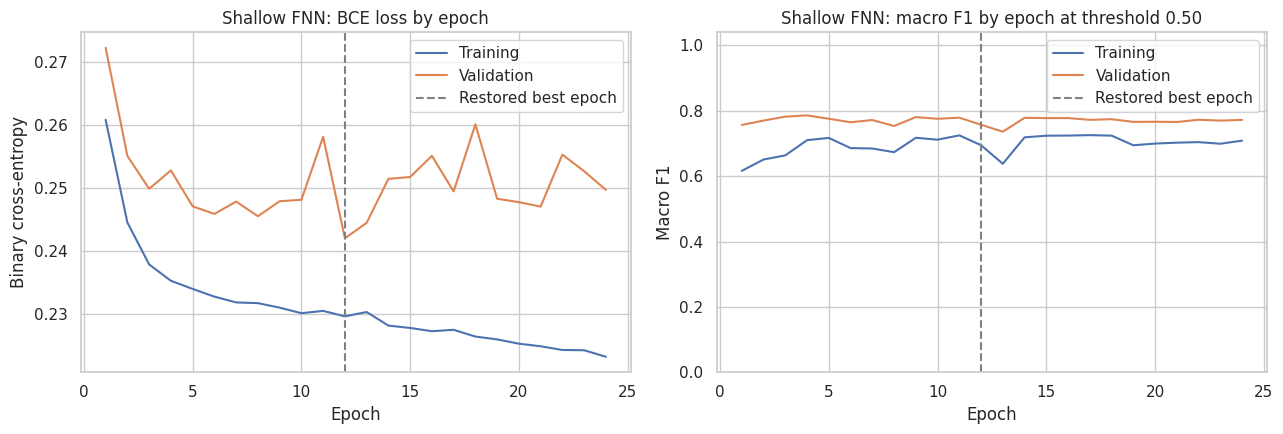

,epoch,train_bce_loss,validation_bce_loss,train_macro_f1_at_05,validation_macro_f1_at_05
0,1,0.2609,0.2723,0.6162,0.7567
11,12,0.2295,0.2420,0.6946,0.7573
23,24,0.2231,0.2497,0.7086,0.7721


In [246]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(fnn_history['epoch'], fnn_history['train_bce_loss'], label='Training')
axes[0].plot(fnn_history['epoch'], fnn_history['validation_bce_loss'], label='Validation')
axes[0].axvline(fnn_best_epoch, color='gray', linestyle='--', label='Restored best epoch')
axes[0].set(title='Shallow FNN: BCE loss by epoch', xlabel='Epoch', ylabel='Binary cross-entropy')
axes[0].legend()

axes[1].plot(fnn_history['epoch'], fnn_history['train_macro_f1_at_05'], label='Training')
axes[1].plot(fnn_history['epoch'], fnn_history['validation_macro_f1_at_05'], label='Validation')
axes[1].axvline(fnn_best_epoch, color='gray', linestyle='--', label='Restored best epoch')
axes[1].set(title='Shallow FNN: macro F1 by epoch at threshold 0.50',
            xlabel='Epoch', ylabel='Macro F1', ylim=(0, 1.04))
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close()

display(fnn_history.iloc[[0, fnn_best_epoch - 1, len(fnn_history) - 1]]
        .drop_duplicates('epoch').round(4))

# 75. Choose a prediction threshold using validation only
The FNN predicts a probability-like score in [0, 1]. To turn it into podium / no podium, we choose a cutoff. Because around three drivers per race finish on the podium, the default 0.50 cutoff may miss too many podiums. We compare a predeclared grid of thresholds (0.10–0.90) and select the one with the highest validation macro F1; ties favor higher podium F1 and then a cutoff closer to 0.50.
This threshold is frozen before the test section and reused for the full model and each ablation. We report the FNN's performance at 0.50 as well for a straightforward comparison to ordinary linear regression. The threshold selection uses validation labels, never test labels.

In [247]:
def evaluate_fnn_predictions(split_name, actual, probabilities, threshold=0.50):
    """Classification plus proper binary-score metrics for a fixed threshold."""
    actual = np.asarray(actual, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    if len(actual) != len(probabilities) or not np.isfinite(probabilities).all():
        raise ValueError('Labels and probabilities must be finite and aligned.')
    if not np.logical_and(probabilities >= 0, probabilities <= 1).all():
        raise ValueError('FNN probabilities must lie within [0, 1].')
    predicted = (probabilities >= threshold).astype(int)
    return {
        'split': split_name,
        'entries': len(actual),
        'actual_podium_rate': float(actual.mean()),
        'predicted_podium_rate': float(predicted.mean()),
        'accuracy': accuracy_score(actual, predicted),
        'balanced_accuracy': balanced_accuracy_score(actual, predicted),
        'podium_precision': precision_score(actual, predicted, zero_division=0),
        'podium_recall': recall_score(actual, predicted, zero_division=0),
        'podium_f1': f1_score(actual, predicted, zero_division=0),
        'macro_f1': f1_score(actual, predicted, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(actual, probabilities),
        'average_precision': average_precision_score(actual, probabilities),
        'log_loss': log_loss(actual, probabilities, labels=[0, 1]),
        'brier_score': brier_score_loss(actual, probabilities),
    }


fnn_threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.901, 0.025), 3):
    metrics = evaluate_fnn_predictions(
        'Validation', y_validation, fnn_validation_probabilities, threshold
    )
    fnn_threshold_rows.append({
        'threshold': float(threshold),
        'validation_macro_f1': metrics['macro_f1'],
        'validation_podium_f1': metrics['podium_f1'],
        'validation_precision': metrics['podium_precision'],
        'validation_recall': metrics['podium_recall'],
        'distance_from_0_50': abs(float(threshold) - 0.5),
    })
fnn_threshold_table = pd.DataFrame(fnn_threshold_rows)
chosen_row = fnn_threshold_table.sort_values(
    ['validation_macro_f1', 'validation_podium_f1', 'distance_from_0_50'],
    ascending=[False, False, True], kind='stable'
).iloc[0]
FNN_THRESHOLD = float(chosen_row['threshold'])

fnn_validation_default_metrics = evaluate_fnn_predictions(
    'Validation (threshold 0.50)', y_validation, fnn_validation_probabilities, 0.50
)
fnn_training_metrics = evaluate_fnn_predictions(
    'Training', y_train, fnn_train_probabilities, FNN_THRESHOLD
)
fnn_validation_metrics = evaluate_fnn_predictions(
    'Validation', y_validation, fnn_validation_probabilities, FNN_THRESHOLD
)
fnn_development_metrics = pd.DataFrame([fnn_training_metrics, fnn_validation_metrics])
print(f'Chosen validation macro-F1 threshold: {FNN_THRESHOLD:.3f}')
display(pd.DataFrame([
    {'model': 'FNN, threshold 0.50', **{k: fnn_validation_default_metrics[k]
                                       for k in ['accuracy', 'macro_f1', 'podium_f1', 'roc_auc', 'average_precision']}},
    {'model': f'FNN, threshold {FNN_THRESHOLD:.3f}', **{k: fnn_validation_metrics[k]
                                        for k in ['accuracy', 'macro_f1', 'podium_f1', 'roc_auc', 'average_precision']}},
    {'model': 'OLS, threshold 0.50', **{k: linear_validation_metrics[k]
                                       for k in ['accuracy', 'macro_f1', 'podium_f1', 'roc_auc', 'average_precision']}},
]).round(4))
display(fnn_development_metrics.round(4))
print('Validation classification report (chosen threshold):')
print(classification_report(y_validation,
    (fnn_validation_probabilities >= FNN_THRESHOLD).astype(int),
    labels=[0, 1], target_names=['No podium', 'Podium'], zero_division=0))

Chosen validation macro-F1 threshold: 0.400


,model,accuracy,macro_f1,podium_f1,roc_auc,average_precision
0,"FNN, threshold 0.50",0.8928,0.7573,0.5760,0.9125,0.6217
1,"FNN, threshold 0.400",0.8839,0.7782,0.6250,0.9125,0.6217
2,"OLS, threshold 0.50",0.8928,0.7052,0.4701,0.9099,0.6162


,split,entries,actual_podium_rate,predicted_podium_rate,accuracy,balanced_accuracy,podium_precision,podium_recall,podium_f1,macro_f1,roc_auc,average_precision,log_loss,brier_score
0,Training,19483,0.1211,0.1157,0.8916,0.7358,0.5548,0.5303,0.5423,0.7404,0.9081,0.5626,0.2295,0.0718
1,Validation,3721,0.1363,0.1733,0.8839,0.8107,0.5581,0.7101,0.6250,0.7782,0.9125,0.6217,0.2420,0.0745


Validation classification report (chosen threshold):
              precision    recall  f1-score   support

   No podium       0.95      0.91      0.93      3214
      Podium       0.56      0.71      0.62       507

    accuracy                           0.88      3721
   macro avg       0.76      0.81      0.78      3721
weighted avg       0.90      0.88      0.89      3721



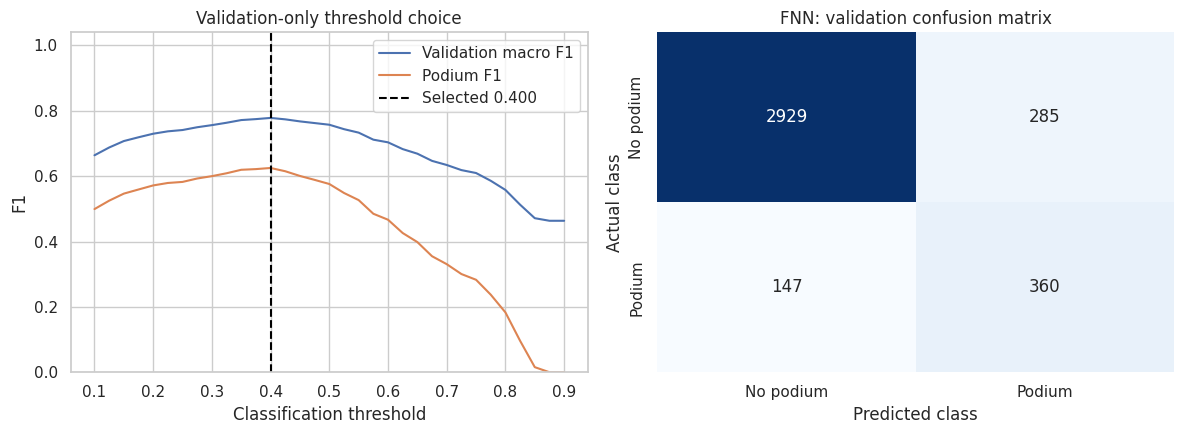

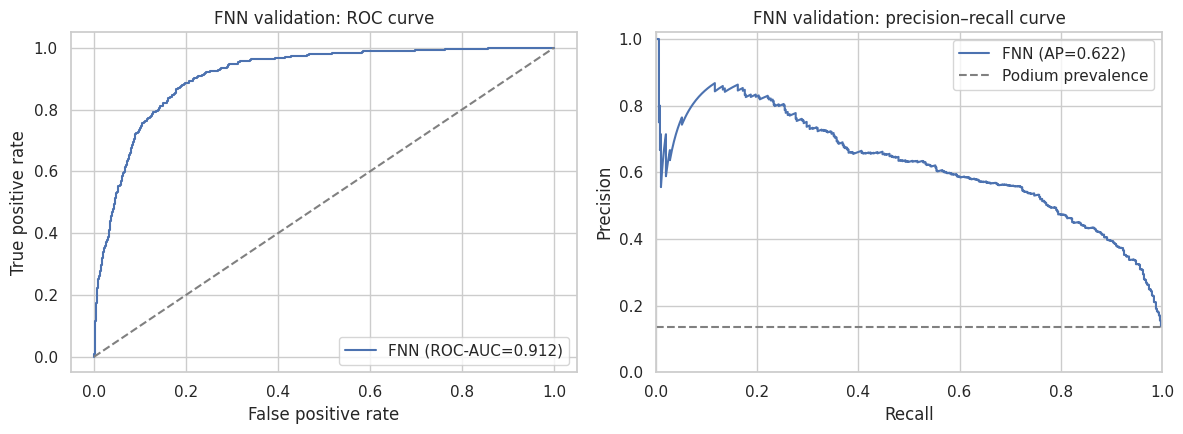

In [248]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fnn_threshold_table['threshold'], fnn_threshold_table['validation_macro_f1'], label='Validation macro F1')
axes[0].plot(fnn_threshold_table['threshold'], fnn_threshold_table['validation_podium_f1'], label='Podium F1')
axes[0].axvline(FNN_THRESHOLD, linestyle='--', color='black', label=f'Selected {FNN_THRESHOLD:.3f}')
axes[0].set(title='Validation-only threshold choice', xlabel='Classification threshold', ylabel='F1', ylim=(0, 1.04))
axes[0].legend()

fnn_val_predictions = (fnn_validation_probabilities >= FNN_THRESHOLD).astype(int)
sns.heatmap(confusion_matrix(y_validation, fnn_val_predictions, labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['No podium', 'Podium'], yticklabels=['No podium', 'Podium'])
axes[1].set(title='FNN: validation confusion matrix', xlabel='Predicted class', ylabel='Actual class')
plt.tight_layout()
plt.show()
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fpr, tpr, _ = roc_curve(y_validation, fnn_validation_probabilities)
axes[0].plot(fpr, tpr, label=f'FNN (ROC-AUC={fnn_validation_metrics["roc_auc"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='FNN validation: ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend()
precision, recall, _ = precision_recall_curve(y_validation, fnn_validation_probabilities)
axes[1].plot(recall, precision, label=f'FNN (AP={fnn_validation_metrics["average_precision"]:.3f})')
axes[1].axhline(float(y_validation.mean()), color='gray', linestyle='--', label='Podium prevalence')
axes[1].set(title='FNN validation: precision–recall curve', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close()

# 76. Feature-group ablation (validation only)
Retrain six fresh FNNs, each missing one of the feature groups already defined for linear regression. Every run fits a fresh preprocessor on training data and uses the same architecture, optimizer settings, random seed and early-stopping rule. Compare validation macro F1, podium F1, ROC-AUC and average precision to the full FNN.
- A negative delta after removing a group means the full model performed better.
- A positive delta means this single retraining did better without that group.
- The same threshold selected for the full network is used for each ablation, to avoid independently optimizing thresholds on the same validation data.
- Rankings are not causal evidence: correlated features and random initialization can affect the results. The test data is not inspected here.

FNN: feature ablations:   0%|          | 0/6 [00:00<?, ?group/s]

Without Starting grid and qualifying:   0%|          | 0/120 [00:00<?, ?epoch/s]

Starting grid and qualifying: macro F1=0.7184, ROC-AUC=0.8742


Without Recent driver performance:   0%|          | 0/120 [00:00<?, ?epoch/s]

Recent driver performance: macro F1=0.7559, ROC-AUC=0.9040


...

Without Circuit identity:   0%|          | 0/120 [00:00<?, ?epoch/s]

Circuit identity: macro F1=0.7731, ROC-AUC=0.9105


Without Constructor identity:   0%|          | 0/120 [00:00<?, ?epoch/s]

Constructor identity: macro F1=0.7820, ROC-AUC=0.9234


,removed_group,features_remaining,encoded_features,best_epoch,validation_macro_f1,validation_podium_f1,validation_roc_auc,validation_average_precision,validation_log_loss,delta_macro_f1_vs_full,delta_podium_f1_vs_full,delta_roc_auc_vs_full,delta_average_precision_vs_full
0,None (full FNN),14,283,12,0.7782,0.6250,0.9125,0.6217,0.2420,0.0000,0.0000,0.0000,0.0000
1,Starting grid and qualifying,12,279,12,0.7184,0.5211,0.8742,0.5525,0.2774,-0.0597,-0.1039,-0.0383,-0.0692
2,Recent driver performance,10,275,12,0.7559,0.5899,0.9040,0.5935,0.2523,-0.0222,-0.0351,-0.0085,-0.0282
3,Recent constructor performance,12,279,12,0.7672,0.6063,0.9059,0.6148,0.2500,-0.0109,-0.0187,-0.0065,-0.0069
4,Driver and season context,10,276,62,0.7945,0.6460,0.9237,0.6648,0.2254,0.0164,0.0210,0.0113,0.0431
5,Circuit identity,13,220,12,0.7731,0.6136,0.9105,0.6185,0.2431,-0.0051,-0.0114,-0.0020,-0.0032
6,Constructor identity,13,86,30,0.7820,0.6299,0.9234,0.6488,0.2286,0.0039,0.0049,0.0109,0.0271


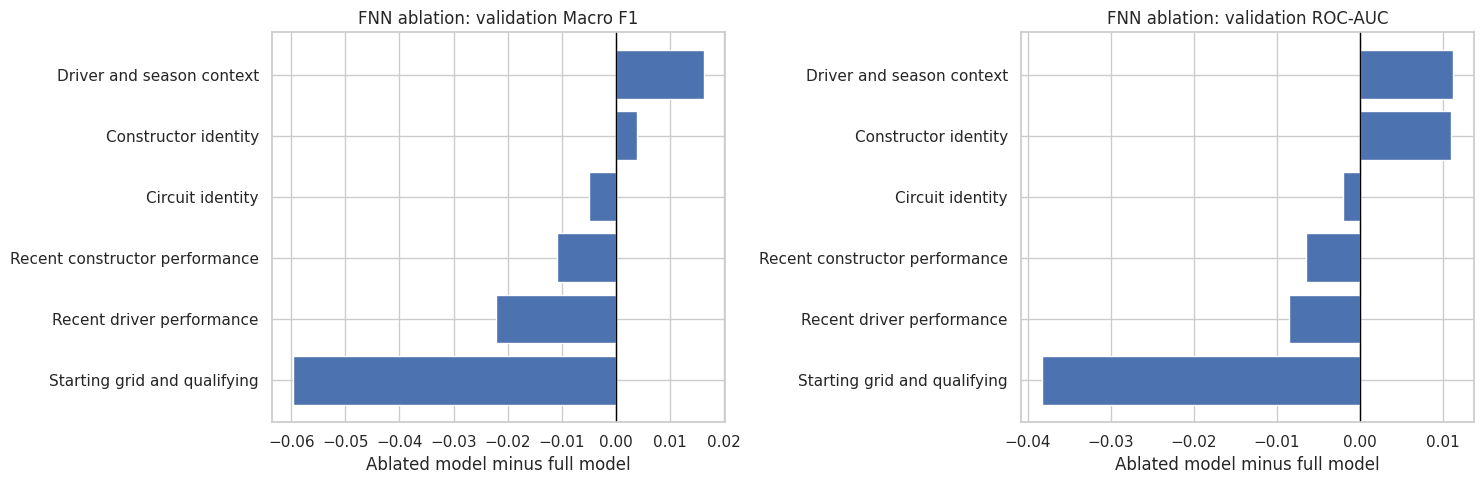

In [249]:
assert set(feature_groups) and {
    feature for group in feature_groups.values() for feature in group
} == set(selected_features)

fnn_ablation_rows = [{
    'removed_group': 'None (full FNN)',
    'features_remaining': len(selected_features),
    'encoded_features': X_train_fnn.shape[1],
    'best_epoch': fnn_best_epoch,
    'validation_macro_f1': fnn_validation_metrics['macro_f1'],
    'validation_podium_f1': fnn_validation_metrics['podium_f1'],
    'validation_roc_auc': fnn_validation_metrics['roc_auc'],
    'validation_average_precision': fnn_validation_metrics['average_precision'],
    'validation_log_loss': fnn_validation_metrics['log_loss'],
}]

for group_name, removed_columns in tqdm(
    feature_groups.items(), total=len(feature_groups),
    desc='FNN: feature ablations', unit='group', colour='green'
):
    retained_columns = [feature for feature in selected_features if feature not in removed_columns]
    reduced_preprocessor = make_fnn_preprocessor(retained_columns)
    reduced_train = as_fnn_array(reduced_preprocessor.fit_transform(X_train[retained_columns]))
    reduced_validation = as_fnn_array(reduced_preprocessor.transform(X_validation[retained_columns]))

    reduced_model, reduced_history, reduced_best_epoch = train_shallow_fnn(
        reduced_train, y_train_fnn, reduced_validation, y_validation_fnn,
        progress_label=f'Without {group_name}', leave_progress=False
    )
    reduced_validation_probs = predict_fnn_probabilities(reduced_model, reduced_validation)
    scores = evaluate_fnn_predictions(
        'Validation', y_validation, reduced_validation_probs, FNN_THRESHOLD
    )
    fnn_ablation_rows.append({
        'removed_group': group_name,
        'features_remaining': len(retained_columns),
        'encoded_features': reduced_train.shape[1],
        'best_epoch': reduced_best_epoch,
        'validation_macro_f1': scores['macro_f1'],
        'validation_podium_f1': scores['podium_f1'],
        'validation_roc_auc': scores['roc_auc'],
        'validation_average_precision': scores['average_precision'],
        'validation_log_loss': scores['log_loss'],
    })
    print(f'{group_name}: macro F1={scores["macro_f1"]:.4f}, ROC-AUC={scores["roc_auc"]:.4f}')

fnn_ablation = pd.DataFrame(fnn_ablation_rows)
for metric in ['macro_f1', 'podium_f1', 'roc_auc', 'average_precision']:
    fnn_ablation[f'delta_{metric}_vs_full'] = (
        fnn_ablation[f'validation_{metric}'] - fnn_validation_metrics[metric]
    )
display(fnn_ablation.round(4))

fnn_ablation_plot = fnn_ablation.loc[fnn_ablation['removed_group'] != 'None (full FNN)']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in [
    (axes[0], 'delta_macro_f1_vs_full', 'Macro F1'),
    (axes[1], 'delta_roc_auc_vs_full', 'ROC-AUC'),
]:
    values = fnn_ablation_plot.sort_values(metric)
    ax.barh(values['removed_group'], values[metric])
    ax.axvline(0, color='black', linewidth=1)
    ax.set(title=f'FNN ablation: validation {title}', xlabel='Ablated model minus full model')
plt.tight_layout()
plt.show()
plt.close()

# 77. Evaluate on the held-out test races — one final evaluation
At this point, the full FNN weights, training preprocessing and validation-chosen threshold FNN_THRESHOLD are frozen. Do not select a new architecture, epoch, feature group, or threshold using test performance. The final test check below (a) transforms test features with the already fitted training preprocessor, (b) predicts podium probabilities, and (c) evaluates classification metrics and per-race top-three rankings.
Important: Choosing a feature group based on ablation would mean training another final model before test; this section deliberately evaluates the original full 14-feature network, just as the original linear regression section did.

In [250]:
# Test features are transformed ONLY after all FNN training and validation decisions.
X_test_fnn = as_fnn_array(fnn_preprocessor.transform(X_test[selected_features]))
fnn_test_probabilities = predict_fnn_probabilities(fnn_model, X_test_fnn)
fnn_test_predictions = (fnn_test_probabilities >= FNN_THRESHOLD).astype(int)
fnn_test_metrics = evaluate_fnn_predictions(
    'Test', y_test, fnn_test_probabilities, FNN_THRESHOLD
)
fnn_performance = pd.DataFrame([
    fnn_training_metrics, fnn_validation_metrics, fnn_test_metrics
])
print('Shallow FNN performance (all splits, threshold chosen on validation):')
display(fnn_performance.round(4))
print(f'FINAL held-out test classification report (threshold {FNN_THRESHOLD:.3f}):')
print(classification_report(y_test, fnn_test_predictions,
                            labels=[0, 1], target_names=['No podium', 'Podium'], zero_division=0))

# A race-relative metric: how many of the true podium finishers are in the top 3 predicted scores?
fnn_race_ranking = pd.DataFrame([
    podium_hits_in_top_three(X_validation.index, fnn_validation_probabilities, 'Validation'),
    podium_hits_in_top_three(X_test.index, fnn_test_probabilities, 'Test'),
])
print('Race-level top-3 ranking performance:')
display(fnn_race_ranking.round(4))

Shallow FNN performance (all splits, threshold chosen on validation):


,split,entries,actual_podium_rate,predicted_podium_rate,accuracy,balanced_accuracy,podium_precision,podium_recall,podium_f1,macro_f1,roc_auc,average_precision,log_loss,brier_score
0,Training,19483,0.1211,0.1157,0.8916,0.7358,0.5548,0.5303,0.5423,0.7404,0.9081,0.5626,0.2295,0.0718
1,Validation,3721,0.1363,0.1733,0.8839,0.8107,0.5581,0.7101,0.6250,0.7782,0.9125,0.6217,0.2420,0.0745
2,Test,3379,0.1500,0.2578,0.8591,0.8717,0.5178,0.8895,0.6546,0.7830,0.9261,0.6791,0.2759,0.0842


FINAL held-out test classification report (threshold 0.400):
              precision    recall  f1-score   support

   No podium       0.98      0.85      0.91      2872
      Podium       0.52      0.89      0.65       507

    accuracy                           0.86      3379
   macro avg       0.75      0.87      0.78      3379
weighted avg       0.91      0.86      0.87      3379

Race-level top-3 ranking performance:


,split,races,average_podium_drivers_in_top3,mean_precision_at_3
0,Validation,169,1.8462,0.6154
1,Test,169,1.9645,0.6548


# 78. Plot unseen-test reports and compare against linear regression
The following graphs compare validation vs test without any retraining. ROC-AUC and average precision use raw probability scores; confusion matrices and F1 require the frozen chosen threshold. A separate table and chart compare ordinary linear regression (fixed threshold 0.50) with the FNN (threshold tuned on validation) using the same selected features and chronological race splits. Interpret threshold-dependent comparisons with that difference in mind.

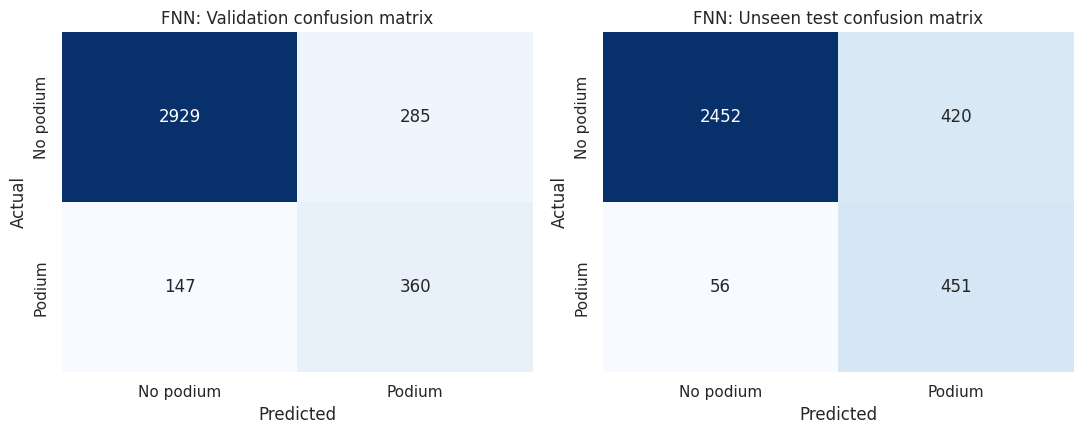

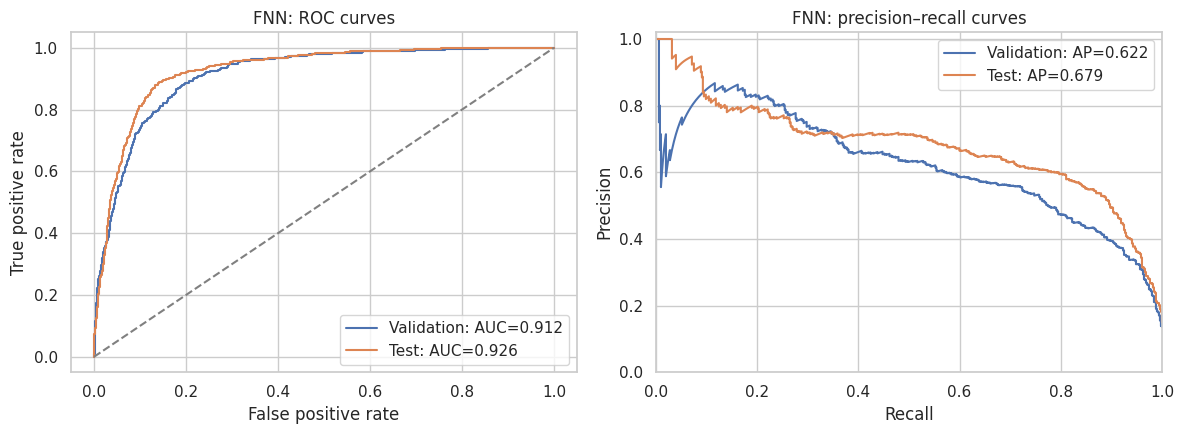

Linear regression vs shallow FNN:


,model,split,accuracy,balanced_accuracy,podium_precision,podium_recall,podium_f1,macro_f1,roc_auc,average_precision
0,Ordinary linear regression (threshold 0.50),Training,0.8880,0.5945,0.6105,0.2073,0.3095,0.6243,0.8950,0.5116
1,Ordinary linear regression (threshold 0.50),Validation,0.8928,0.6638,0.7195,0.3491,0.4701,0.7052,0.9099,0.6162
2,Ordinary linear regression (threshold 0.50),Test,0.8807,0.6960,0.6557,0.4320,0.5208,0.7263,0.9199,0.6342
3,Shallow FNN (threshold 0.400),Training,0.8916,0.7358,0.5548,0.5303,0.5423,0.7404,0.9081,0.5626
4,Shallow FNN (threshold 0.400),Validation,0.8839,0.8107,0.5581,0.7101,0.6250,0.7782,0.9125,0.6217
5,Shallow FNN (threshold 0.400),Test,0.8591,0.8717,0.5178,0.8895,0.6546,0.7830,0.9261,0.6791


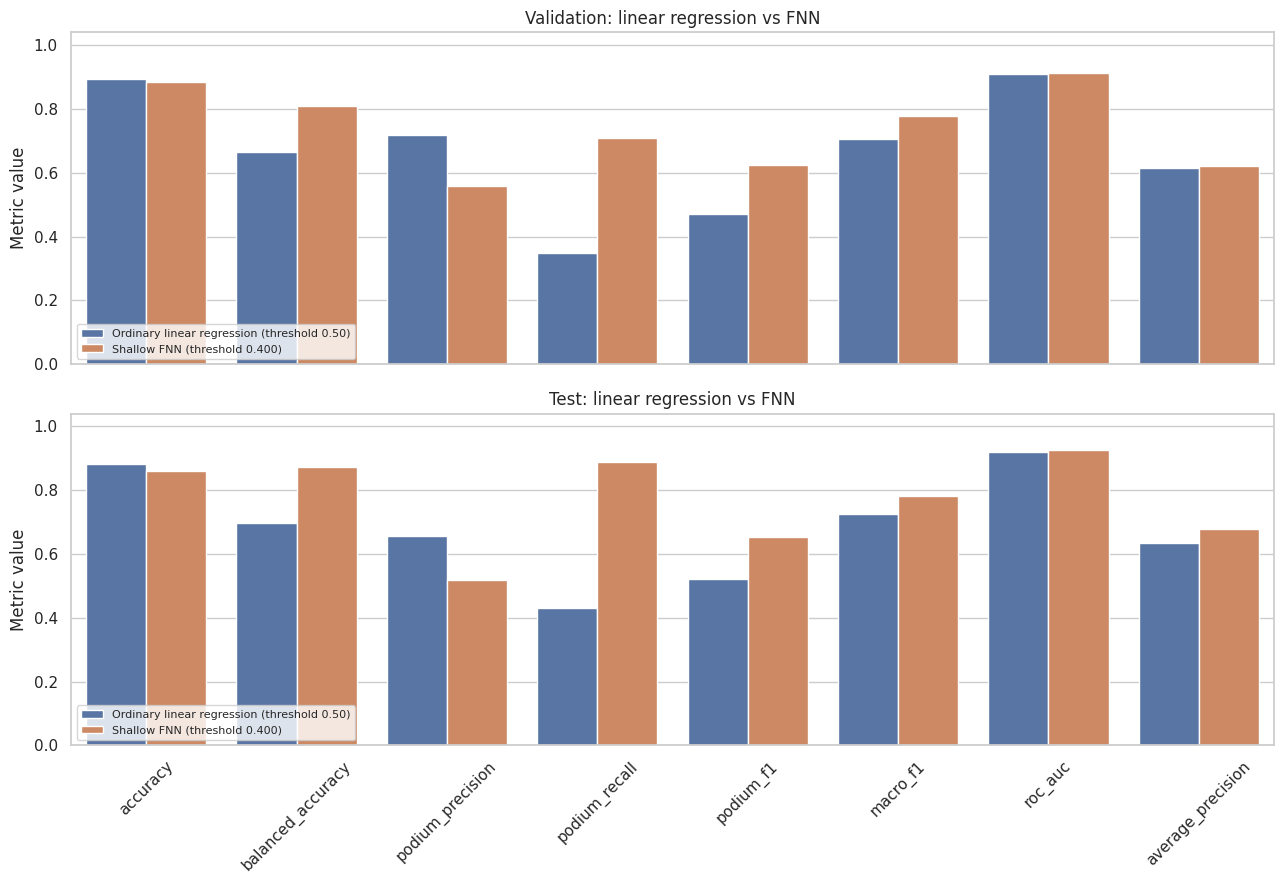

In [251]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, actual, predicted in [
    (axes[0], 'Validation', y_validation, fnn_val_predictions),
    (axes[1], 'Unseen test', y_test, fnn_test_predictions),
]:
    cm = confusion_matrix(actual, predicted, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No podium', 'Podium'], yticklabels=['No podium', 'Podium'])
    ax.set(title=f'FNN: {name} confusion matrix', xlabel='Predicted', ylabel='Actual')
plt.tight_layout()
plt.show()
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, actual, probabilities in [
    ('Validation', y_validation, fnn_validation_probabilities),
    ('Test', y_test, fnn_test_probabilities),
]:
    fpr, tpr, _ = roc_curve(actual, probabilities)
    precision, recall, _ = precision_recall_curve(actual, probabilities)
    axes[0].plot(fpr, tpr, label=f'{name}: AUC={roc_auc_score(actual, probabilities):.3f}')
    axes[1].plot(recall, precision, label=f'{name}: AP={average_precision_score(actual, probabilities):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='FNN: ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='FNN: precision–recall curves', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
plt.close()

shared_metrics = ['accuracy', 'balanced_accuracy', 'podium_precision', 'podium_recall',
                  'podium_f1', 'macro_f1', 'roc_auc', 'average_precision']
linear_compare = linear_performance[['split'] + shared_metrics].copy()
linear_compare.insert(0, 'model', 'Ordinary linear regression (threshold 0.50)')
fnn_compare = fnn_performance[['split'] + shared_metrics].copy()
fnn_compare.insert(0, 'model', f'Shallow FNN (threshold {FNN_THRESHOLD:.3f})')
fnn_vs_linear = pd.concat([linear_compare, fnn_compare], ignore_index=True)
print('Linear regression vs shallow FNN:')
display(fnn_vs_linear.round(4))

comparison_long = fnn_vs_linear.loc[fnn_vs_linear['split'].isin(['Validation', 'Test'])].melt(
    id_vars=['model', 'split'], value_vars=shared_metrics,
    var_name='metric', value_name='value'
)
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, split in zip(axes, ['Validation', 'Test']):
    sns.barplot(data=comparison_long[comparison_long['split'] == split],
                x='metric', y='value', hue='model', ax=ax)
    ax.set(title=f'{split}: linear regression vs FNN', xlabel='', ylabel='Metric value', ylim=(0, 1.04))
    ax.legend(loc='lower left', fontsize=8)
axes[-1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
plt.close()

# 79. FNN limitations and how to interpret the results
1. Imbalanced outcomes: only about three podium places are available per race. Accuracy alone can hide poor podium recall; macro F1, podium F1, ROC-AUC, average precision and per-race top-3 hits tell a fuller story.
2. Small dataset / overfitting: a neural network can fit noise and may generalize poorly across rule changes or new constructors. Dropout, weight decay and early stopping help, but do not guarantee generalization. Inspect the training–validation loss gap.
3. Dependence on validation: early stopping and threshold tuning use the same chronological validation block. The reported validation macro F1 is therefore optimistically selected. The held-out test is the final generalization estimate; do not tune in response to it.
4. Probability calibration: sigmoid scores lie in [0, 1], but they are not guaranteed to be calibrated. The Brier score and log loss offer additional evidence. Threshold tuning changes class predictions, not the scores themselves.
5. Preprocessing caveat: the chosen preprocessing may clip calendar year to training quantiles (if option B won). The FNN inherits this limitation to stay directly comparable to linear regression. A later controlled experiment could exempt year and other bounded indicators from clipping.
6. Time cutoff and historical features: the archive's starting grid can incorporate late changes unavailable just after qualifying. Past-only rolling features assume earlier races' results are known; this is appropriate for chronological next-race prediction.
7. Ablation is not causal: a single retraining per removed group is sensitive to feature correlations and initialization. Repeated seeds would give a more stable estimate but increase training cost.
8. One sigmoid per driver is not a full race simulator: the model independently estimates each driver's chance of a podium, so its probabilities across drivers are not constrained to sum to three. The optional top-three ranking metric evaluates race-relative usefulness instead.
9. Fair comparison: the FNN trains with cross-entropy and uses a validation-tuned threshold, whereas the linear baseline uses squared-error loss and a fixed 0.50 threshold. ROC-AUC and average precision are more direct threshold-independent comparisons.
Era coverage: the added categorical era represents a broad before/after-2014 difference; numeric year remains included. An era absent from training has no learned effect, even though handle_unknown="ignore" allows predictions. The additional past-only season normalization reduces points-scale differences but does not fully harmonize scoring rules. First-season races lack a normalization reference; binary missingness flags preserve this uncertainty. Comparable performance across periods is not guaranteed.


# 80. Save all FNN artifacts
Save the fitted training-only preprocessor, best-epoch neural-network weights, decision threshold, epoch history, validation threshold experiment, train/validation/test metrics, validation-only ablation, top-three ranking, and per-driver validation/test predictions. Also export the side-by-side model comparison. To use the checkpoint later, reconstruct ShallowPodiumFNN(input_features, hidden_units, dropout), load its state_dict, and apply joblib.load(...) to the same incoming feature columns before predicting. Note: TrainingQuantileClipper and NumericMissingFlags are custom notebook classes; they must be defined/imported before reloading the joblib preprocessor in a fresh Python process.

In [252]:
import joblib
output_folder.mkdir(parents=True, exist_ok=True)
fnn_history.to_csv(output_folder / 'fnn_training_history.csv', index=False)
fnn_threshold_table.to_csv(output_folder / 'fnn_validation_threshold_search.csv', index=False)
fnn_performance.to_csv(output_folder / 'fnn_split_metrics.csv', index=False)
fnn_ablation.to_csv(output_folder / 'fnn_feature_group_ablation.csv', index=False)
fnn_race_ranking.to_csv(output_folder / 'fnn_race_top3_metrics.csv', index=False)
fnn_vs_linear.to_csv(output_folder / 'fnn_vs_linear_regression_metrics.csv', index=False)


def save_fnn_predictions(file_name, indices, actual, probabilities, threshold):
    rows = model_data.loc[indices, ['raceId', 'driverId', 'date']].copy()
    rows['actual_podium'] = np.asarray(actual, dtype=int)
    rows['podium_probability'] = np.asarray(probabilities, dtype=float)
    rows['predicted_podium'] = (rows['podium_probability'] >= threshold).astype(int)
    rows.to_csv(output_folder / file_name, index=False)
    return rows


fnn_validation_predictions_table = save_fnn_predictions(
    'fnn_validation_predictions.csv', X_validation.index,
    y_validation, fnn_validation_probabilities, FNN_THRESHOLD
)
fnn_test_predictions_table = save_fnn_predictions(
    'fnn_test_predictions.csv', X_test.index,
    y_test, fnn_test_probabilities, FNN_THRESHOLD
)

joblib.dump(fnn_preprocessor, output_folder / 'shallow_fnn_preprocessor.joblib')
torch.save({
    'state_dict': {key: value.detach().cpu() for key, value in fnn_model.state_dict().items()},
    'input_features': int(X_train_fnn.shape[1]),
    'hidden_units': FNN_CONFIG['hidden_units'],
    'dropout': FNN_CONFIG['dropout'],
    'best_epoch': fnn_best_epoch,
    'validation_selected_threshold': FNN_THRESHOLD,
    'preprocessing_order': best_order,
    'selected_features': list(selected_features),
}, output_folder / 'shallow_fnn_model.pt')
print('FNN results, best-epoch model, preprocessor and model comparisons saved to:', output_folder.resolve())

FNN results, best-epoch model, preprocessor and model comparisons saved to: /kaggle/working


## Model Explainability (XAI)

The previous sections trained, tuned and tested two models. The XAI section **does not change, retrain or re-select anything**: it only asks *how the frozen full shallow FNN reaches its predictions*.

**Choices (kept deliberately simple):**
- **Model explained: the shallow FNN.** Its hidden-layer behaviour cannot be read off a coefficient table; compare the newly computed metrics before claiming that it outperforms the linear model. (The linear model's weights are already directly readable.)
- **Data explained: the validation races, never the test races.** The test split stays reserved for final reporting only, and all XAI choices (sample sizes, which rows to show) are fixed by rules written in the code, not picked after looking at the results.
- **Level of explanation: the 14 original features**, not the encoded columns (whose count depends on training categories). A one-hot column such as `constructorId_6` or a missing-value flag is not meaningful on its own, so every method below returns one number per original feature (and per ablation feature group).
- **Methods:** permutation importance (global, uses the real metrics), SHAP (global and local), LIME (local, a second opinion on the same rows).

**Important – importance is not causation.** Every plot below describes what the *model relies on* to make predictions. A feature being important does not mean it *causes* podium finishes. For example, `constructor_points_season_z_last5` can matter because strong teams keep winning (a common cause), not because points history changes the result of the next race. Likewise, a feature with low importance is not shown to be irrelevant in reality: a correlated feature (such as `qualifying_position` next to `grid_position`) can carry the same information.

In [253]:
import subprocess, sys, importlib
for _package in ['shap', 'lime']:
    try:
        importlib.import_module(_package)
    except ImportError:  # Kaggle needs Internet switched on for this one-time install.
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', _package])
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr

XAI_SEED = 42

def save_xai_figure(name):
    plt.savefig(output_folder / f'xai_{name}.png', dpi=150, bbox_inches='tight')

def fnn_predict_raw(frame):
    # Raw 14-feature table -> podium probability, using the FROZEN training-fitted preprocessor and FNN.
    encoded = as_fnn_array(fnn_preprocessor.transform(frame[selected_features]))
    return predict_fnn_probabilities(fnn_model, encoded)

# Sanity check: this wrapper must reproduce the probabilities already reported in the FNN section.
xai_probabilities = fnn_predict_raw(X_validation)
assert np.allclose(xai_probabilities, fnn_validation_probabilities, atol=1e-5), 'Wrapper does not match the trained FNN.'
xai_base_ap = average_precision_score(y_validation, xai_probabilities)
xai_base_auc = roc_auc_score(y_validation, xai_probabilities)
print(f'Explaining the frozen FNN on {len(X_validation)} validation entries ({validation_ids.nunique()} races).')
print(f'Reference scores: PR-AUC (average precision) = {xai_base_ap:.4f}, ROC-AUC = {xai_base_auc:.4f}')

Explaining the frozen FNN on 3721 validation entries (169 races).
Reference scores: PR-AUC (average precision) = 0.6217, ROC-AUC = 0.9125


### 80. Global explanation 1: permutation importance
**Idea.** Take the validation set, shuffle one feature's values across entries (breaking its link with the outcome while keeping its distribution), and measure how much the model's score falls. A large fall means the model leans on that feature. We repeat the shuffle 10 times and report the mean and standard deviation.

**Choices.**
- **Metric: PR-AUC (average precision) first, ROC-AUC second.** Both ignore the decision threshold, so the explanation is not tied to the 0.325 cut-off. PR-AUC is the better headline because podiums are only about 15% of entries.
- **Features and feature groups.** Each of the 14 features is shuffled alone. We also shuffle each ablation group (the six groups from sections 67 and 76) *together*, with one common shuffle. This matters for correlated inputs: if only `grid_position` is shuffled, the model can still lean on `qualifying_position`, which makes each look less important than the pair really is. The grouped result can be compared directly with the ablation table.
- **Why this complements the ablation.** Ablation *retrains* without a group (the network can compensate with other features); permutation keeps the trained model fixed and damages one input. They answer slightly different questions, so agreement between them is reassuring and disagreement is informative.
- **Caveat.** Shuffling can create unrealistic rows (for example a front-row grid with a poor qualifying position), so values for strongly correlated features should be read together with the grouped results.

,unit,kind,drop_pr_auc,std_pr_auc,drop_roc_auc,std_roc_auc
0,grid_position,feature,0.3162,0.0137,0.2297,0.0109
8,constructor_points_season_z_last5,feature,0.0375,0.0064,0.0183,0.0018
6,driver_podium_rate_last5,feature,0.0281,0.0047,0.0106,0.0011
13,era,feature,0.0029,0.0083,-0.0019,0.0013
5,driver_points_season_z_last5,feature,0.0027,0.0027,0.0014,0.0004
1,qualifying_position,feature,0.0013,0.0055,-0.0000,0.0004
10,constructor_history_count,feature,0.0000,0.0012,-0.0000,0.0002
3,year,feature,0.0000,0.0000,0.0000,0.0000
9,driver_history_count,feature,-0.0002,0.0007,0.0001,0.0001
7,driver_finish_last5,feature,-0.0011,0.0022,0.0007,0.0003


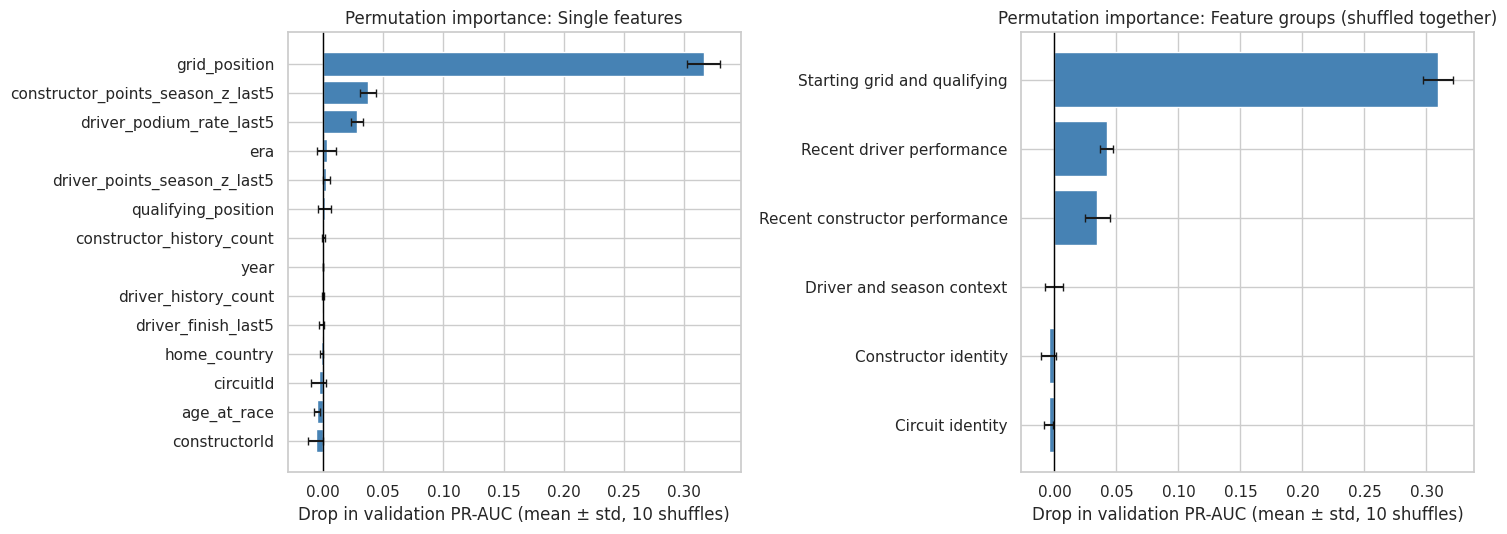

A drop near zero means the model does not rely on that input; a negative drop is shuffling noise.


In [254]:
def permutation_importance_table(units, n_repeats=10, seed=XAI_SEED):
    # Shuffle each unit (one feature, or a whole group with ONE shared shuffle) and record the score drop.
    rng = np.random.default_rng(seed)
    rows = []
    for name, (kind, columns) in units.items():
        ap_drops, auc_drops = [], []
        for _ in range(n_repeats):
            order = rng.permutation(len(X_validation))
            shuffled = X_validation.copy()
            for column in columns:  # column by column, so every column keeps its own dtype
                shuffled[column] = X_validation[column].to_numpy()[order]
            probabilities = fnn_predict_raw(shuffled)
            ap_drops.append(xai_base_ap - average_precision_score(y_validation, probabilities))
            auc_drops.append(xai_base_auc - roc_auc_score(y_validation, probabilities))
        rows.append({'unit': name, 'kind': kind,
                     'drop_pr_auc': np.mean(ap_drops), 'std_pr_auc': np.std(ap_drops),
                     'drop_roc_auc': np.mean(auc_drops), 'std_roc_auc': np.std(auc_drops)})
    return pd.DataFrame(rows)

perm_units = {feature: ('feature', [feature]) for feature in selected_features}
perm_units.update({group: ('group', list(columns)) for group, columns in feature_groups.items()})
permutation_table = permutation_importance_table(perm_units)
perm_features = permutation_table.loc[permutation_table['kind'].eq('feature')].sort_values('drop_pr_auc', ascending=False)
perm_groups = permutation_table.loc[permutation_table['kind'].eq('group')].sort_values('drop_pr_auc', ascending=False)
display(permutation_table.sort_values(['kind', 'drop_pr_auc'], ascending=[True, False]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for axis, data, title in [(axes[0], perm_features, 'Single features'), (axes[1], perm_groups, 'Feature groups (shuffled together)')]:
    data = data.iloc[::-1]
    axis.barh(data['unit'], data['drop_pr_auc'], xerr=data['std_pr_auc'], color='steelblue', capsize=3)
    axis.axvline(0, color='black', linewidth=1)
    axis.set(title=f'Permutation importance: {title}', xlabel='Drop in validation PR-AUC (mean ± std, 10 shuffles)')
plt.tight_layout(); save_xai_figure('permutation_importance'); plt.show(); plt.close()
print('A drop near zero means the model does not rely on that input; a negative drop is shuffling noise.')

### 81. Global explanation 2: SHAP
**Idea.** SHAP gives every prediction an additive breakdown: *average predicted podium probability* + (contribution of each feature) = *this entry's predicted probability*. The contribution of a feature is its average marginal effect over all orders in which features could be revealed to the model (a Shapley value). Averaging the absolute contributions over many entries gives a global ranking; plotting their signs against feature values shows the direction of the effect.

**Choices.**
- **Kernel SHAP, applied to the 14 raw features.** Kernel SHAP works for any model, so it needs no changes to the PyTorch network. We wrap the whole frozen pipeline (preprocessing + FNN) so that the 14 original columns are the "players". The Shapley estimate uses 1,500 coalitions per entry with no feature-selection shortcut; sampling noise remains, and no one-hot columns need to be summed back afterwards. The three categorical columns (circuit, constructor and era) are passed as integer codes inside the wrapper and decoded back to their labels before the model sees them.
- **Output scale: predicted podium probability**, which is easier to read than log-odds.
- **Background: 40 random training entries; explained rows: 150 random validation entries** (both with fixed seed 42). Kernel SHAP cost grows with background size × rows; this size is a speed/accuracy compromise, so treat small differences between features as noise. Missing values stay missing in the background and in the explained rows, exactly as the model sees them.
- **Check:** the contributions plus the base value must add up to each entry's model probability.

Base value (average background probability): 0.1284
Largest additivity gap over 150 explained entries: 5.96e-08


,feature,mean_abs_shap
0,grid_position,0.0970
3,year,0.0298
8,constructor_points_season_z_last5,0.0267
12,constructorId,0.0259
13,era,0.0240
6,driver_podium_rate_last5,0.0223
1,qualifying_position,0.0177
11,circuitId,0.0104
7,driver_finish_last5,0.0071
5,driver_points_season_z_last5,0.0057


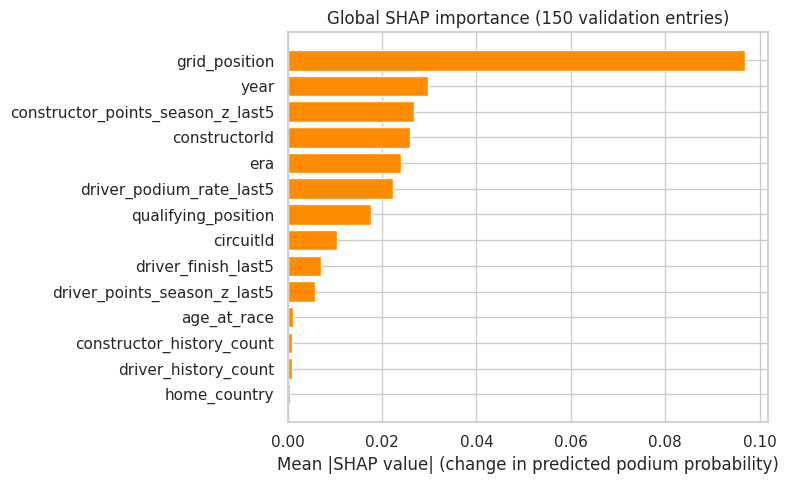

/tmp/ipykernel_58/111927752.py:57: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_sample[:, numeric_positions], shap_sample[numeric_features], feature_names=numeric_features,


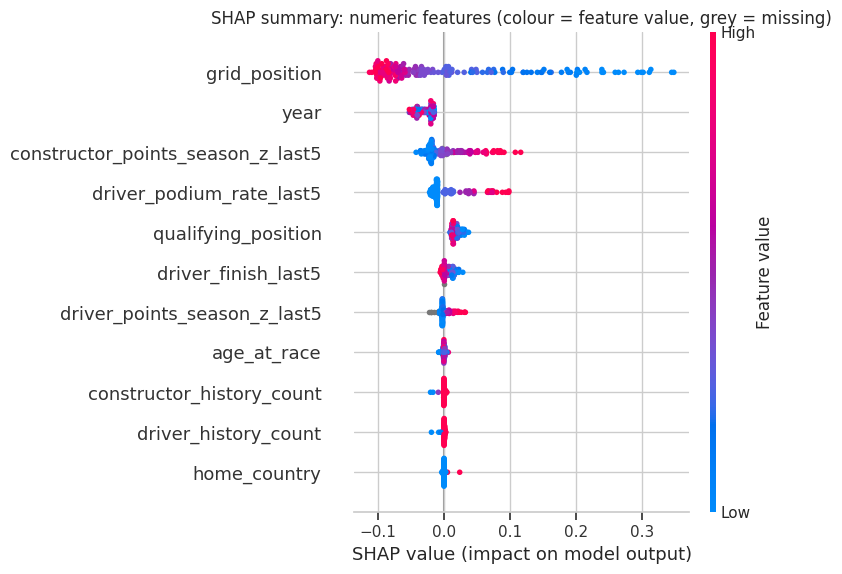

In [255]:
categorical_levels = {column: sorted(set(X_train[column]) | set(X_validation[column])) for column in categorical_features}

def encode_for_shap(frame):
    # Numeric features stay numeric (NaN kept); the three categorical columns become integer codes.
    out = frame[selected_features].copy()
    for column in categorical_features:
        out[column] = pd.Categorical(out[column], categories=categorical_levels[column]).codes.astype(float)
    return out.to_numpy(dtype=float)

def decode_from_shap(array):
    frame = pd.DataFrame(array, columns=selected_features)
    for column in categorical_features:
        levels = np.asarray(categorical_levels[column], dtype=object)
        frame[column] = levels[frame[column].round().astype(int).to_numpy()]
    return frame

def shap_model_function(array):
    return fnn_predict_raw(decode_from_shap(np.asarray(array, dtype=float)))

# The encode/decode round trip must be lossless, or the explanations would describe the wrong inputs.
_check = decode_from_shap(encode_for_shap(X_validation.head(50)))
assert _check[categorical_features].equals(X_validation.head(50)[categorical_features].reset_index(drop=True))
assert np.allclose(_check[numeric_features].to_numpy(float), X_validation.head(50)[numeric_features].to_numpy(float), equal_nan=True)

shap_background = encode_for_shap(X_train.sample(40, random_state=XAI_SEED))
shap_sample = X_validation.sample(150, random_state=XAI_SEED)
shap_explainer = shap.KernelExplainer(shap_model_function, shap_background)
shap_base_value = float(np.ravel(shap_explainer.expected_value)[0])

def kernel_shap_values(frame, nsamples):
    values = shap_explainer.shap_values(encode_for_shap(frame), nsamples=nsamples, l1_reg=0, silent=True)
    values = np.asarray(values[0] if isinstance(values, list) else values)
    if values.ndim == 3:
        values = values[..., 0]
    assert values.shape == (len(frame), len(selected_features))
    return values

shap_values_sample = kernel_shap_values(shap_sample, nsamples=1500)

# Efficiency check: base value + sum of contributions = the model's own probability.
shap_gap = np.abs(shap_base_value + shap_values_sample.sum(axis=1) - fnn_predict_raw(shap_sample))
assert shap_gap.max() < 1e-2, 'SHAP contributions do not add up to the model output.'
print(f'Base value (average background probability): {shap_base_value:.4f}')
print(f'Largest additivity gap over {len(shap_sample)} explained entries: {shap_gap.max():.2e}')

shap_importance = pd.DataFrame({'feature': selected_features,
                                'mean_abs_shap': np.abs(shap_values_sample).mean(axis=0)}).sort_values('mean_abs_shap', ascending=False)
display(shap_importance.round(4))

numeric_positions = [selected_features.index(feature) for feature in numeric_features]
fig, axis = plt.subplots(figsize=(8, 5))
ordered = shap_importance.iloc[::-1]
axis.barh(ordered['feature'], ordered['mean_abs_shap'], color='darkorange')
axis.set(title='Global SHAP importance (150 validation entries)', xlabel='Mean |SHAP value| (change in predicted podium probability)')
plt.tight_layout(); save_xai_figure('shap_bar'); plt.show(); plt.close()

shap.summary_plot(shap_values_sample[:, numeric_positions], shap_sample[numeric_features], feature_names=numeric_features,
                  show=False, max_display=len(numeric_features))
plt.title('SHAP summary: numeric features (colour = feature value, grey = missing)')
plt.tight_layout(); save_xai_figure('shap_beeswarm'); plt.show(); plt.close()

**How to read the SHAP summary plot.** Each dot is one validation entry. Its horizontal position is how much that feature pushed this entry's predicted podium probability up (right) or down (left) relative to the base value; its colour is the feature's value (red = high, blue = low, grey = missing). For example, if low `grid_position` values (blue, i.e. front of the grid) sit on the right, the model raises the podium probability for front-row starters. The categorical features (circuit, constructor and era) are shown in the bar chart only; their temporary integer codes are labels, not numeric magnitudes.

### 82. Do the explanations agree with each other and with the ablation?
Three independent views of the same model should tell a broadly consistent story. We compare, at feature-group level, (1) grouped permutation importance, (2) SHAP (the *group's* contribution is the sum of its features' contributions for each entry, then averaged in absolute value), and (3) the validation-only ablation from section 75 (drop in average precision when the group is removed and the network is retrained). Disagreements are not errors: ablation allows retraining to compensate with correlated features, permutation and SHAP do not.

,permutation_drop_pr_auc,permutation_drop_roc_auc,mean_abs_shap,ablation_delta_pr_auc,ablation_delta_roc_auc,ablation_loss_pr_auc
unit,,,,,,
Starting grid and qualifying,0.3095,0.1974,0.0979,-0.0692,-0.0383,0.0692
Recent driver performance,0.0424,0.0193,0.0312,-0.0282,-0.0085,0.0282
Recent constructor performance,0.0346,0.0182,0.0274,-0.0069,-0.0065,0.0069
Driver and season context,-0.0003,-0.0027,0.0349,0.0431,0.0113,-0.0431
Constructor identity,-0.0047,-0.0009,0.0259,0.0271,0.0109,-0.0271
Circuit identity,-0.0048,-0.0001,0.0104,-0.0032,-0.0020,0.0032


Spearman rank correlation across 6 groups, permutation vs SHAP: 0.83
Spearman rank correlation across 6 groups, permutation vs ablation: 0.77
Spearman rank correlation across 6 groups, SHAP vs ablation: 0.37
Spearman rank correlation across 14 single features, permutation vs SHAP: 0.46


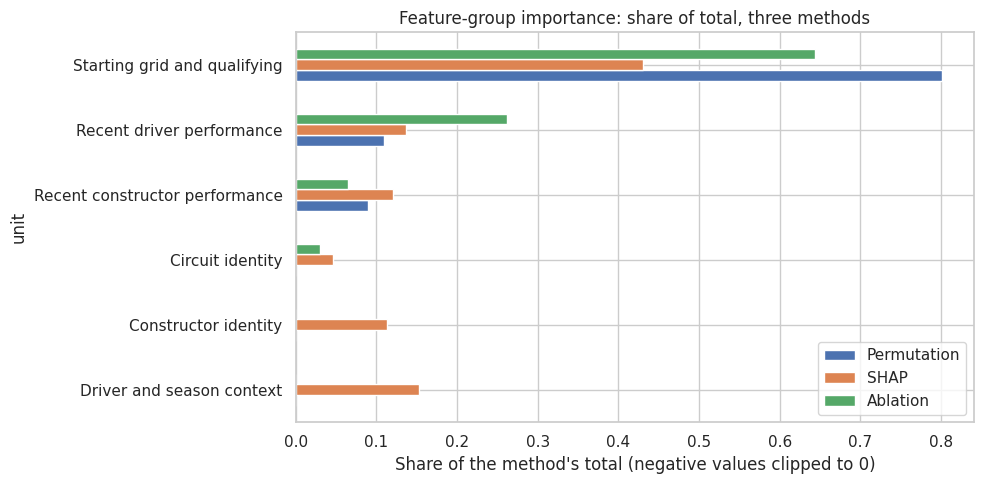

Training Spearman correlation between grid_position and qualifying_position: 0.99 (strongly correlated inputs share credit, so look at the grouped result.)


In [256]:
group_shap = pd.DataFrame({group: np.abs(shap_values_sample[:, [selected_features.index(c) for c in columns]].sum(axis=1)).mean()
                           for group, columns in feature_groups.items()}, index=['mean_abs_shap']).T
group_compare = (perm_groups.set_index('unit')[['drop_pr_auc', 'drop_roc_auc']]
                 .rename(columns={'drop_pr_auc': 'permutation_drop_pr_auc', 'drop_roc_auc': 'permutation_drop_roc_auc'})
                 .join(group_shap)
                 .join(fnn_ablation.set_index('removed_group')[['delta_average_precision_vs_full', 'delta_roc_auc_vs_full']]
                       .rename(columns={'delta_average_precision_vs_full': 'ablation_delta_pr_auc',
                                        'delta_roc_auc_vs_full': 'ablation_delta_roc_auc'})))
group_compare['ablation_loss_pr_auc'] = -group_compare['ablation_delta_pr_auc']  # positive = removal hurt
display(group_compare.sort_values('permutation_drop_pr_auc', ascending=False).round(4))

# Rank agreement (6 groups only, so treat as a rough indication).
rank_pairs = {'permutation vs SHAP': ('permutation_drop_pr_auc', 'mean_abs_shap'),
              'permutation vs ablation': ('permutation_drop_pr_auc', 'ablation_loss_pr_auc'),
              'SHAP vs ablation': ('mean_abs_shap', 'ablation_loss_pr_auc')}
for label, (first, second) in rank_pairs.items():
    rho = spearmanr(group_compare[first], group_compare[second]).correlation
    print(f'Spearman rank correlation across 6 groups, {label}: {rho:.2f}')
feature_rank_rho = spearmanr(perm_features.set_index('unit')['drop_pr_auc'].reindex(selected_features),
                             shap_importance.set_index('feature')['mean_abs_shap'].reindex(selected_features)).correlation
print(f'Spearman rank correlation across {len(selected_features)} single features, permutation vs SHAP: {feature_rank_rho:.2f}')

normalised = group_compare[['permutation_drop_pr_auc', 'mean_abs_shap', 'ablation_loss_pr_auc']].clip(lower=0)
normalised = (normalised / normalised.sum()).sort_values('permutation_drop_pr_auc')
normalised.rename(columns={'permutation_drop_pr_auc': 'Permutation', 'mean_abs_shap': 'SHAP', 'ablation_loss_pr_auc': 'Ablation'}).plot.barh(figsize=(10, 5))
plt.title('Feature-group importance: share of total, three methods'); plt.xlabel('Share of the method\'s total (negative values clipped to 0)')
plt.tight_layout(); save_xai_figure('method_agreement'); plt.show(); plt.close()

train_grid_corr = spearmanr(X_train['grid_position'], X_train['qualifying_position'], nan_policy='omit').correlation
print(f'Training Spearman correlation between grid_position and qualifying_position: {train_grid_corr:.2f} '
      '(strongly correlated inputs share credit, so look at the grouped result.)')

In [257]:
# Written interpretation generated from the numbers above (nothing is hard-coded).
negligible = perm_features.loc[perm_features['drop_pr_auc'] < 2 * perm_features['std_pr_auc'], 'unit'].tolist()
top3_perm = perm_features.head(3)
top3_shap = shap_importance.head(3)
print('GLOBAL FINDINGS')
print('- Permutation (PR-AUC drop) top 3 features: ' +
      ', '.join(f"{r.unit} ({r.drop_pr_auc:.3f})" for r in top3_perm.itertuples()))
print('- SHAP (mean |contribution to probability|) top 3 features: ' +
      ', '.join(f"{r.feature} ({r.mean_abs_shap:.3f})" for r in top3_shap.itertuples()))
overlap = set(top3_perm['unit']) & set(top3_shap['feature'])
print(f'- {len(overlap)} of the top-3 features are shared by both methods: {sorted(overlap)}')
best_group = perm_groups.iloc[0]
print(f"- Most relied-on group by permutation: '{best_group['unit']}' (PR-AUC drop {best_group['drop_pr_auc']:.3f}); "
      f"by ablation: '{group_compare['ablation_loss_pr_auc'].idxmax()}'.")
print('- Features whose permutation drop is within 2 standard deviations of zero (model barely relies on them): ' +
      (', '.join(negligible) if negligible else 'none'))
print('These statements describe what the model uses, not what causes podium finishes.')

GLOBAL FINDINGS
- Permutation (PR-AUC drop) top 3 features: grid_position (0.316), constructor_points_season_z_last5 (0.038), driver_podium_rate_last5 (0.028)
- SHAP (mean |contribution to probability|) top 3 features: grid_position (0.097), year (0.030), constructor_points_season_z_last5 (0.027)
- 2 of the top-3 features are shared by both methods: ['constructor_points_season_z_last5', 'grid_position']
- Most relied-on group by permutation: 'Starting grid and qualifying' (PR-AUC drop 0.310); by ablation: 'Starting grid and qualifying'.
- Features whose permutation drop is within 2 standard deviations of zero (model barely relies on them): era, driver_points_season_z_last5, qualifying_position, constructor_history_count, driver_history_count, driver_finish_last5, home_country, circuitId, age_at_race, constructorId
These statements describe what the model uses, not what causes podium finishes.


### 83. Local explanation 1: SHAP waterfall for single predictions
A local explanation answers: *why did the model give this particular driver in this particular race this probability?* We explain two validation entries chosen by a rule fixed in advance, so that we neither cherry-pick flattering cases nor hide failures:

1. **A correct podium prediction:** among true podium finishers that the model flags (probability ≥ the validated threshold), the one whose probability is closest to the median of that group, i.e. a *typical* success rather than the easiest one.
2. **The most serious miss:** the true podium finisher with the lowest predicted probability, i.e. the model's worst false negative.

The waterfall starts from the base value and adds each feature's contribution until it reaches the entry's predicted probability. The finishing position is shown below only to describe the case after the fact; it is never an input.

,case,date,driver_name,constructor_name,circuit_name,positionOrder,predicted_probability
19667,Typical correct podium prediction,2008-08-24,Lewis Hamilton,McLaren,Valencia Street Circuit,2,0.594113
19819,Most serious miss (false negative),2009-03-29,Jarno Trulli,Toyota,Albert Park Grand Prix Circuit,3,0.001598


,19667,19819
grid_position,2.0,20.0
qualifying_position,2.0,8.0
age_at_race,23.628137,34.711185
year,2008.0,2009.0
home_country,0.0,0.0
driver_points_season_z_last5,0.985914,NaN
driver_podium_rate_last5,0.4,0.0
driver_finish_last5,7.2,12.4
constructor_points_season_z_last5,0.952132,NaN
driver_history_count,5.0,5.0


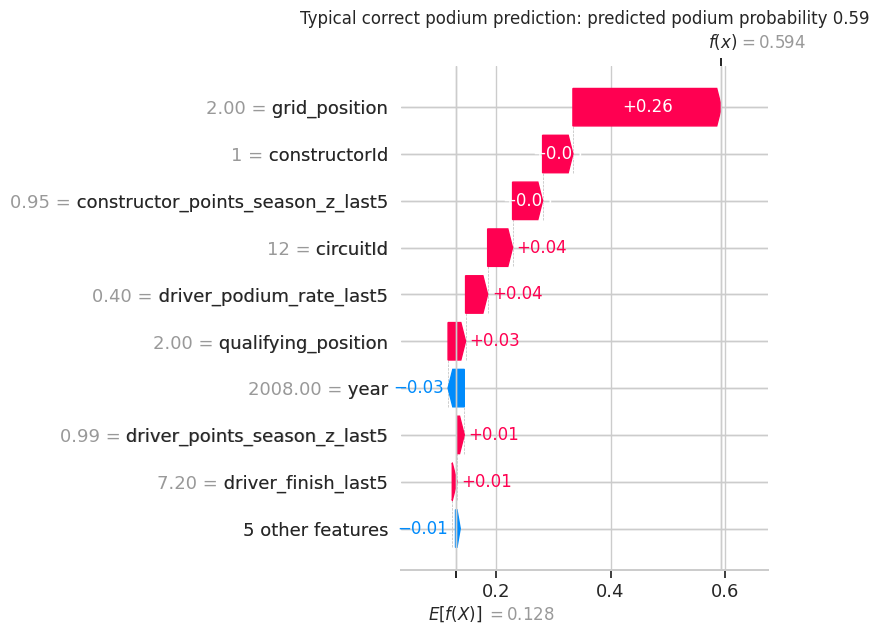

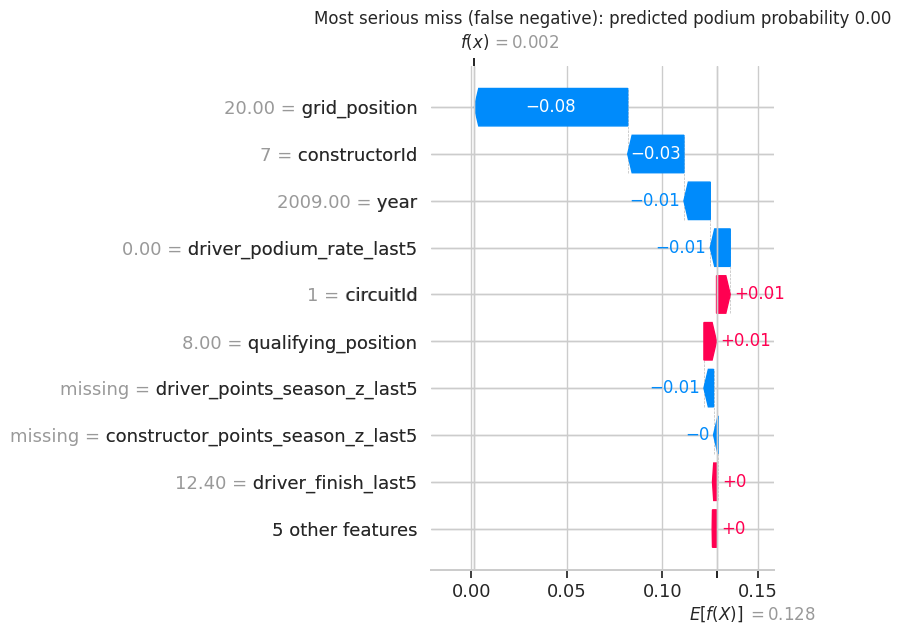

In [258]:
validation_positions = np.arange(len(X_validation))
truth_validation = y_validation.to_numpy()
flagged_podium = validation_positions[(truth_validation == 1) & (fnn_validation_probabilities >= FNN_THRESHOLD)]
missed_podium = validation_positions[(truth_validation == 1) & (fnn_validation_probabilities < FNN_THRESHOLD)]
assert len(flagged_podium) and len(missed_podium), 'Need at least one correct and one missed podium to illustrate.'
typical_hit = flagged_podium[np.argmin(np.abs(fnn_validation_probabilities[flagged_podium]
                                              - np.median(fnn_validation_probabilities[flagged_podium])))]
worst_miss = missed_podium[np.argmin(fnn_validation_probabilities[missed_podium])]
local_cases = {'Typical correct podium prediction': X_validation.index[typical_hit],
               'Most serious miss (false negative)': X_validation.index[worst_miss]}

case_table = model_data.loc[list(local_cases.values()), ['date', 'driver_name', 'constructor_name', 'circuit_name', 'positionOrder']].copy()
case_table.insert(0, 'case', list(local_cases.keys()))
case_table['predicted_probability'] = [fnn_validation_probabilities[typical_hit], fnn_validation_probabilities[worst_miss]]
display(case_table)
display(X_validation.loc[list(local_cases.values()), selected_features].T)

local_shap_values = kernel_shap_values(X_validation.loc[list(local_cases.values())], nsamples=3000)
for (title, entry_index), values in zip(local_cases.items(), local_shap_values):
    row = X_validation.loc[entry_index]
    model_probability = float(fnn_predict_raw(X_validation.loc[[entry_index]])[0])
    assert abs(shap_base_value + values.sum() - model_probability) < 1e-2
    display_values = np.array([('missing' if pd.isna(row[f]) else (f'{row[f]:.2f}' if f in numeric_features else str(row[f])))
                               for f in selected_features], dtype=object)
    explanation = shap.Explanation(values=values, base_values=shap_base_value, data=display_values,
                                   feature_names=list(selected_features))
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.title(f'{title}: predicted podium probability {model_probability:.2f}')
    plt.tight_layout(); save_xai_figure('shap_waterfall_' + ('hit' if title.startswith('Typical') else 'miss')); plt.show(); plt.close()

### 84. Local explanation 2: LIME for the same two entries
**Idea.** LIME explains one prediction by generating many slightly altered copies of that entry, asking the network for each copy's probability, and fitting a small *linear* model that is only trusted near that entry. Its weights say which input values pushed this prediction up or down locally.

**Choices and caveats.**
- **Same two entries as the SHAP waterfalls**, so the two local methods can be compared directly.
- **LIME runs on the encoded inputs** (the network's actual input columns, counted dynamically after preprocessing), because LIME cannot handle missing values and string categories directly. Numeric inputs there are standardised, so a condition such as `grid_position <= -0.8` means "about one standard deviation better than the training average", not a raw grid slot. Binary columns are one-hot categories (including era) or missing-value flags.
- **Fixed seed and 5,000 perturbations.** LIME is random; the local fit quality (R²) is printed so weak explanations can be recognised.
- LIME and SHAP are different estimators, so exact agreement is not expected. We compare which *original features* appear among each method's top contributors.

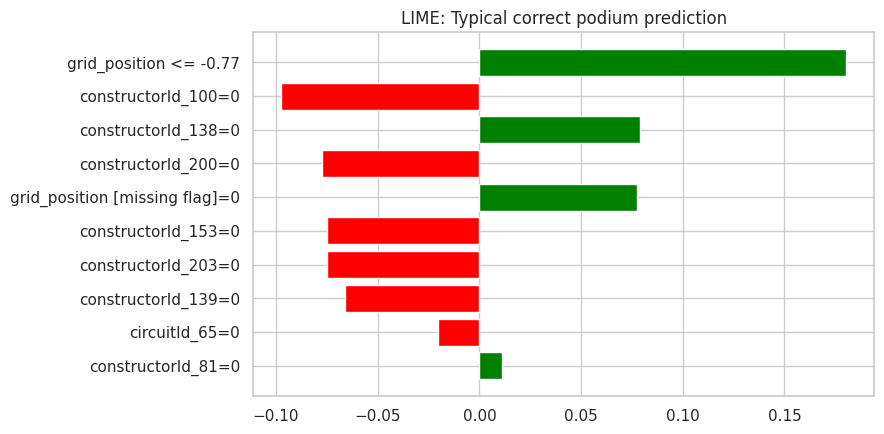

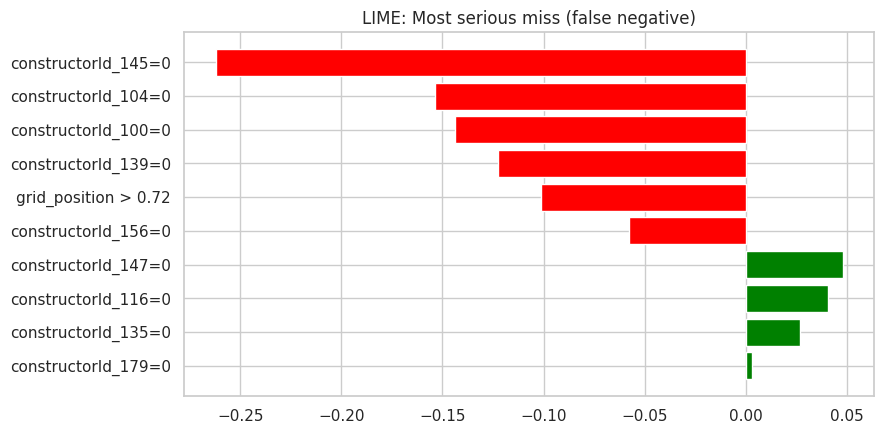

,case,lime_local_R2,shap_top5,lime_top5,shared_in_top5
0,Typical correct podium prediction,0.524756,"[grid_position, constructorId, constructor_poi...","[grid_position, constructorId, constructorId, ...",2
1,Most serious miss (false negative),0.155644,"[grid_position, constructorId, year, driver_po...","[constructorId, constructorId, constructorId, ...",2


In [259]:
encoded_names = (list(numeric_features) + [f'{feature} [missing flag]' for feature in numeric_features] +
                 list(fnn_preprocessor.named_transformers_['categories'].get_feature_names_out(categorical_features)))
assert len(encoded_names) == X_train_fnn.shape[1]
low_cardinality = [j for j in range(X_train_fnn.shape[1]) if np.unique(X_train_fnn[:, j]).size <= 10]  # flags, IDs, counts

lime_explainer = LimeTabularExplainer(
    X_train_fnn, feature_names=encoded_names, class_names=['No podium', 'Podium'], mode='classification',
    categorical_features=low_cardinality, discretize_continuous=True, random_state=XAI_SEED)

def lime_predict(array):
    probability = predict_fnn_probabilities(fnn_model, np.asarray(array, dtype=np.float32))
    return np.column_stack([1 - probability, probability])

def raw_feature_of(label):
    # LIME labels such as '-0.80 < grid_position <= 0.12' -> the original feature name.
    return max((f for f in selected_features if f in label), key=len)

local_agreement = []
for (title, entry_index), values in zip(local_cases.items(), local_shap_values):
    encoded_row = as_fnn_array(fnn_preprocessor.transform(X_validation.loc[[entry_index]][selected_features]))[0]
    lime_explanation = lime_explainer.explain_instance(encoded_row, lime_predict, num_features=10, num_samples=5000)
    lime_top = [raw_feature_of(label) for label, _ in lime_explanation.as_list()]
    shap_top = [selected_features[i] for i in np.argsort(-np.abs(values))[:5]]
    shared = sorted(set(lime_top[:5]) & set(shap_top))
    local_agreement.append({'case': title, 'lime_local_R2': lime_explanation.score,
                            'shap_top5': shap_top, 'lime_top5': lime_top[:5], 'shared_in_top5': len(shared)})
    fig = lime_explanation.as_pyplot_figure()
    fig.set_size_inches(9, 4.5)
    plt.title(f'LIME: {title}')
    plt.tight_layout(); save_xai_figure('lime_' + ('hit' if title.startswith('Typical') else 'miss')); plt.show(); plt.close()
display(pd.DataFrame(local_agreement))

### 85. How to interpret the explanations, and what they cannot tell us
- **Reading the global results together.** A feature the model really depends on should rank high in permutation importance *and* SHAP, and its group should lose accuracy in the ablation. Where the three methods agree, we can state with more confidence that the *model* uses that information. Disagreements point to correlated inputs (shared credit) or to a model that compensates after retraining.
- **Reading the local results.** The waterfall and LIME plots explain two individual predictions, not the whole model. The "most serious miss" case is included on purpose: it shows which evidence the model weighed when it was wrong, which is how explanations help find weaknesses rather than just justify successes.
- **Not causal.** Permutation importance, SHAP and LIME all describe the trained model's behaviour on our data. They do not show that changing a feature would change the real-world result. Team strength, car performance and era act as common causes of both the features (grid, recent points) and podium finishes, so the model can use them without any of them causing the outcome in the sense of an intervention.
- **Pre-race validity.** All features explained here come from the leakage-safe feature table (qualifying, grid, and strictly past-race form), so an explanation never points to information that would be unavailable at the prediction cutoff.
- **Estimation noise.** Kernel SHAP uses 150 explained rows and 40 background rows; LIME is a random local fit; permutation importance uses 10 shuffles on 1,440 entries in 72 races, and rows within a race are not independent. Small gaps between neighbouring features should not be over-interpreted.
- **Single model, single split.** We explain the one trained FNN on the validation block. Another seed or a later era could rank minor features differently; the large effects (those far above the permutation noise) are the trustworthy ones.

### 86. Save the XAI results
The tables are saved next to the earlier results; the plots were already saved as `xai_*.png` in the same folder for the report.

In [260]:
permutation_table.to_csv(output_folder / 'xai_permutation_importance.csv', index=False)
shap_importance.to_csv(output_folder / 'xai_shap_global_importance.csv', index=False)
group_compare.to_csv(output_folder / 'xai_group_method_comparison.csv')
pd.DataFrame(local_agreement).to_csv(output_folder / 'xai_local_lime_vs_shap.csv', index=False)
case_table.to_csv(output_folder / 'xai_local_cases.csv', index=False)
print('Saved XAI tables and figures to:', output_folder.resolve())

Saved XAI tables and figures to: /kaggle/working
